# Assessing Beer Profiles and Ratings

## 1. Introduction

### Research Introduction and Motivation
The patterns and clusters in this dataset could be interesting for someone whose career relates to beer, or someone who simply drinks beer. "Characteristics of beer quality (or of good beer) are  generally dependent on the beer style..." [3] In other words, it could give them insight as to which beer taste profiles are more common, or which flavors and attributes work better together. \

This information could also be interesting to someone that brews, markets, or sells beer. This knowledge could help a brewery refine the taste and quality of beer as they could look into which flavors result in better taste reviews. They could also look at current beers' attributes that may make them more successful. Champion Brewing Company, for example, used qualities "on which IPAs are judged at the Great American Beer Festival (SRM, ABV, IBU) and matched that range with the 10-best-selling IPAs nationally, as well as the 10 worst selling IPAs" [1] in order to craft their beer. They even dubbed this beer, "ML IPA" for "Machine Learning."

It could also help a marketing team in a beer company skills identify which beer attributes result in better reviews and more sales. Business analyst Pochepskiy Oleg writes, "New England IPAs have captured the taste buds of beer enthusiasts with their fruity, juicy flavors and cloudy appearance. This style continues to dominate the craft beer scene." [2] If fruity and sweet beers often have better aroma, a marketing team could use that attribute to create a brand image for a beer and better appeal to certain beer enthusiasts. \

Further, someone who sells beer could use this data to better understand beer trends in the market.

[1] [Using data science to brew beer](https://datascience.virginia.edu/pages/using-data-science-brew-beer)

[2] [Expert Perspectives: Analyzing the 22 Major Beer Trends](https://www.cleverence.com/articles/business-blogs/expert-perspectives-analyzing-the-22-major-beer-trends/)

[3] [Beer Quality Evaluation-A Sensory Aspect](https://doi.org/10.3390/beverages8010015)

#### How research motivation impacts the desired type of clustering

Types of clustering results we may encounter for this analysis: \

* **A clustering where each cluster is well-separated.** \
This result would be helpful, as it could potentially create distinct clusters in which certain flavors are put together. These can then be overlayed with the pre-assigned class labels for `Brewery`, thus creating a collection of flavors that each brewery tends to sell. This could help a marketing team better select a specific theme or vibe to advertise. It could also help a brewery gain a better understanding of the competitors' flavor profiles.
* **A clustering where at least one cluster was a singleton outlier**. \
This wouldn't be extremely helpful, as it doesn't give a brewery any understanding of the overall industry. Although it may be interesting to look into why a beer would be an outlier, it is hard to say if it would be of any functional importance.
* **A fuzzy clustering** \
This would be helpful, as it could tell us which beers tend to be most similar, as well as which belong to their respectful clusters with more "confidence," or in technical terms, a higher membership score. For example, observations in a cluster that have higher `review_aroma` scores may also tend to have a lower `ABV` (Alcohol by volume). We then might notice that the darker, or high membership points, tend to be observations with a higher number of reviews.
* **A dendrogram which displays a nested cluster relationship** \
A dendogram may be helpful to a brewery. With the information on what beers were clustered together first, a brewery can gain a better understanding of which attributes of a beer are more commonly seen together. Something that could also help is using the y axis to guage clusters that were further away from each other. This would mean that two groups of beers are very different in their attribute values. We will also see how this could help indentify any outliers.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn import preprocessing

from sklearn.cluster import AgglomerativeClustering
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram

from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import matplotlib.cm as cm

## 2. Dataset Discussion

### Dataset Display

In [ ]:
#note you need to upload the dataset to the colab notebook or have it in the proper directory if running on vscode
df=pd.read_csv('beer_profile_and_ratings.csv')
len(df)

3197

In [ ]:
df.head()

,Name,Style,Brewery,Beer Name (Full),Description,ABV,Min IBU,Max IBU,Astringency,Body,...,Fruits,Hoppy,Spices,Malty,review_aroma,review_appearance,review_palate,review_taste,review_overall,number_of_reviews
0,Amber,Altbier,Alaskan Brewing Co.,Alaskan Brewing Co. Alaskan Amber,"Notes:Richly malty and long on the palate, wit...",5.3,25,50,13,32,...,33,57,8,111,3.498994,3.636821,3.556338,3.643863,3.847082,497
1,Double Bag,Altbier,Long Trail Brewing Co.,Long Trail Brewing Co. Double Bag,"Notes:This malty, full-bodied double alt is al...",7.2,25,50,12,57,...,24,35,12,84,3.798337,3.846154,3.904366,4.024948,4.034304,481
2,Long Trail Ale,Altbier,Long Trail Brewing Co.,Long Trail Brewing Co. Long Trail Ale,Notes:Long Trail Ale is a full-bodied amber al...,5.0,25,50,14,37,...,10,54,4,62,3.409814,3.667109,3.600796,3.631300,3.830239,377
3,Doppelsticke,Altbier,Uerige Obergärige Hausbrauerei GmbH / Zum Uerige,Uerige Obergärige Hausbrauerei GmbH / Zum Ueri...,Notes:,8.5,25,50,13,55,...,49,40,16,119,4.148098,4.033967,4.150815,4.205163,4.005435,368
4,Sleigh'r Dark Doüble Alt Ale,Altbier,Ninkasi Brewing Company,Ninkasi Brewing Company Sleigh'r Dark Doüble A...,Notes:Called 'Dark Double Alt' on the label.Se...,7.2,25,50,25,51,...,11,51,20,95,3.625000,3.973958,3.734375,3.765625,3.817708,96


In [ ]:
df.isna().sum()

,0
Name,0
Style,0
Brewery,0
Beer Name (Full),0
Description,0
ABV,0
Min IBU,0
Max IBU,0
Astringency,0
Body,0


The original dataset here consisted of 3197 observations. Seeing as this dataset is rather larger and may significantly impact runtime, as well as reading a dendogram from HAC, we take a randomized subset of the original dataframe to only include 200 observations. Seed is set to 437 for reproducability. We also observed that there are no null or missing values.

In [ ]:
seed=437
df = df.sample(n=200, random_state=seed).reset_index(drop=True)

In [ ]:
df.head(n=5)

,Name,Style,Brewery,Beer Name (Full),Description,ABV,Min IBU,Max IBU,Astringency,Body,...,Fruits,Hoppy,Spices,Malty,review_aroma,review_appearance,review_palate,review_taste,review_overall,number_of_reviews
0,Heavy Seas Black Cannon,IPA - Black / Cascadian Dark Ale,Heavy Seas Beer,Heavy Seas Beer Heavy Seas Black Cannon,Notes:,7.25,50,70,20,94,...,70,140,11,121,3.768293,4.004065,3.841463,3.934959,3.861789,123
1,Moinette Brune,Strong Ale - Belgian Dark,Brasserie Dupont sprl,Brasserie Dupont sprl Moinette Brune,Notes:,8.50,25,50,13,51,...,84,22,28,54,3.916667,3.936667,3.813333,3.856667,3.846667,150
2,Double Old Thumper Ale,Barleywine - English,Shipyard Brewing Co.,Shipyard Brewing Co. Double Old Thumper Ale,Notes:,11.20,40,60,2,62,...,80,68,17,125,3.515873,3.928571,3.531746,3.452381,3.357143,63
3,Schleimhammer Roggenbier,Rye Beer - Roggenbier,Mill Street Brew Pub,Mill Street Brew Pub Mill Street Schleimhammer...,Notes:Roggenbier is an ancient style of beer f...,5.20,10,20,22,36,...,42,32,56,116,3.764706,3.794118,3.676471,3.808824,3.911765,34
4,Lou Pepe - Kriek,Lambic - Fruit,Brasserie Cantillon,Brasserie Cantillon Cantillon Lou Pepe - Kriek,Notes:,5.00,15,21,23,22,...,74,7,5,13,4.316206,4.357708,4.300395,4.462451,4.320158,253


### Dataset Source

The source of this data is Kaggle. Information from two datasets, [Beer Tasting Profiles](https://www.kaggle.com/stephenpolozoff/top-beer-information) and [1.5 Million Beer Reviews](https://www.kaggle.com/rdoume/beerreviews), was combined to create the one we use here: beer_profile_and_ratings.csv \
This csv file was downloaded 12/10/2024

### Original Dataset Information

Each observation in this dataset represents a unique beer \

The data in *Beer Tasting Profiles* was crowdsourced for class project purposes, where most people that were asked to provide their reviews are located in the US. \

The data in *1.5 Million Beer Reviews* is taken from BeerAdvocate: an online beer rating site. \

The odds of this dataset accounting for every single beer that has ever existed are very low. There are likely tons of beers that haven't ever been documented on BeerAdvocate, especially ones that exist in foreign countries or areas where people have less access to technology. \

Based on this, people in my research motivation might be concerned that they are missing out on beers that have not yet been discovered by the vast majority of people.

#### Selected Variables

In this analysis, we intend to use the following categorical variables:

- `Style` (style of beer)
- `Brewery` (name of brewery)
- `Rating` (`review_overall` variable transformed to a categorical variable representing a rating)

And the following numerical variables:

- `ABV` (alcohol by volume)
- `Bitter`
- `Sweet`
- `Sour`
- `Salty`
- `Fruits`
- `review_aroma` (score for beer aroma)
- `review_taste` (score for beer taste)
- `number_of_reviews`

## 3. Dataset Cleaning and Exploration

### Missing Value Detection and Cleaning

This dataset has no missing values.

Below, we transform `review_overall` to a categorical variable named `Rating`, where a review score from 2.5 to 3 means 'Horrible,' 3 to 3.5 means 'Bad,' and so on.

In [ ]:
bins = [1.5, 2.5, 3.5, 4, 4.5, 5]
labels = ['Horrible', 'Bad', 'Mediocre', 'Good', 'Excellent']

df['Rating'] = pd.cut(df['review_overall'], bins=bins, labels=labels, include_lowest=True)

We also take a subset of the original dataframe in order to include variables we are interested in.

In [ ]:
num_cols=['ABV','Bitter','Sweet','Sour','Salty','Fruits','review_aroma','review_taste','number_of_reviews']
cat_cols = ['Style','Brewery', 'Rating']

cat_df=df[cat_cols]
num_df=df[num_cols]

In [ ]:
num_df.describe()

,ABV,Bitter,Sweet,Sour,Salty,Fruits,review_aroma,review_taste,number_of_reviews
count,200.000000,200.00000,200.000000,200.00000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,6.691100,38.43000,54.535000,32.73000,0.765000,35.905000,3.636582,3.684150,196.435000
std,4.234546,26.79693,31.474625,35.79825,1.239944,30.109615,0.491584,0.521546,278.731037
min,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000,1.744898,1.438776,1.000000
25%,5.000000,18.00000,32.750000,10.00000,0.000000,12.750000,3.416396,3.459178,22.000000
50%,6.000000,32.00000,50.000000,22.00000,0.000000,25.000000,3.713093,3.808258,83.500000
75%,7.500000,53.00000,69.250000,41.25000,1.000000,56.750000,3.951488,3.988465,265.500000
max,57.500000,145.00000,178.000000,206.00000,6.000000,123.000000,4.555921,4.620614,2217.000000


### Outlier Identification - Two Variable Outliers



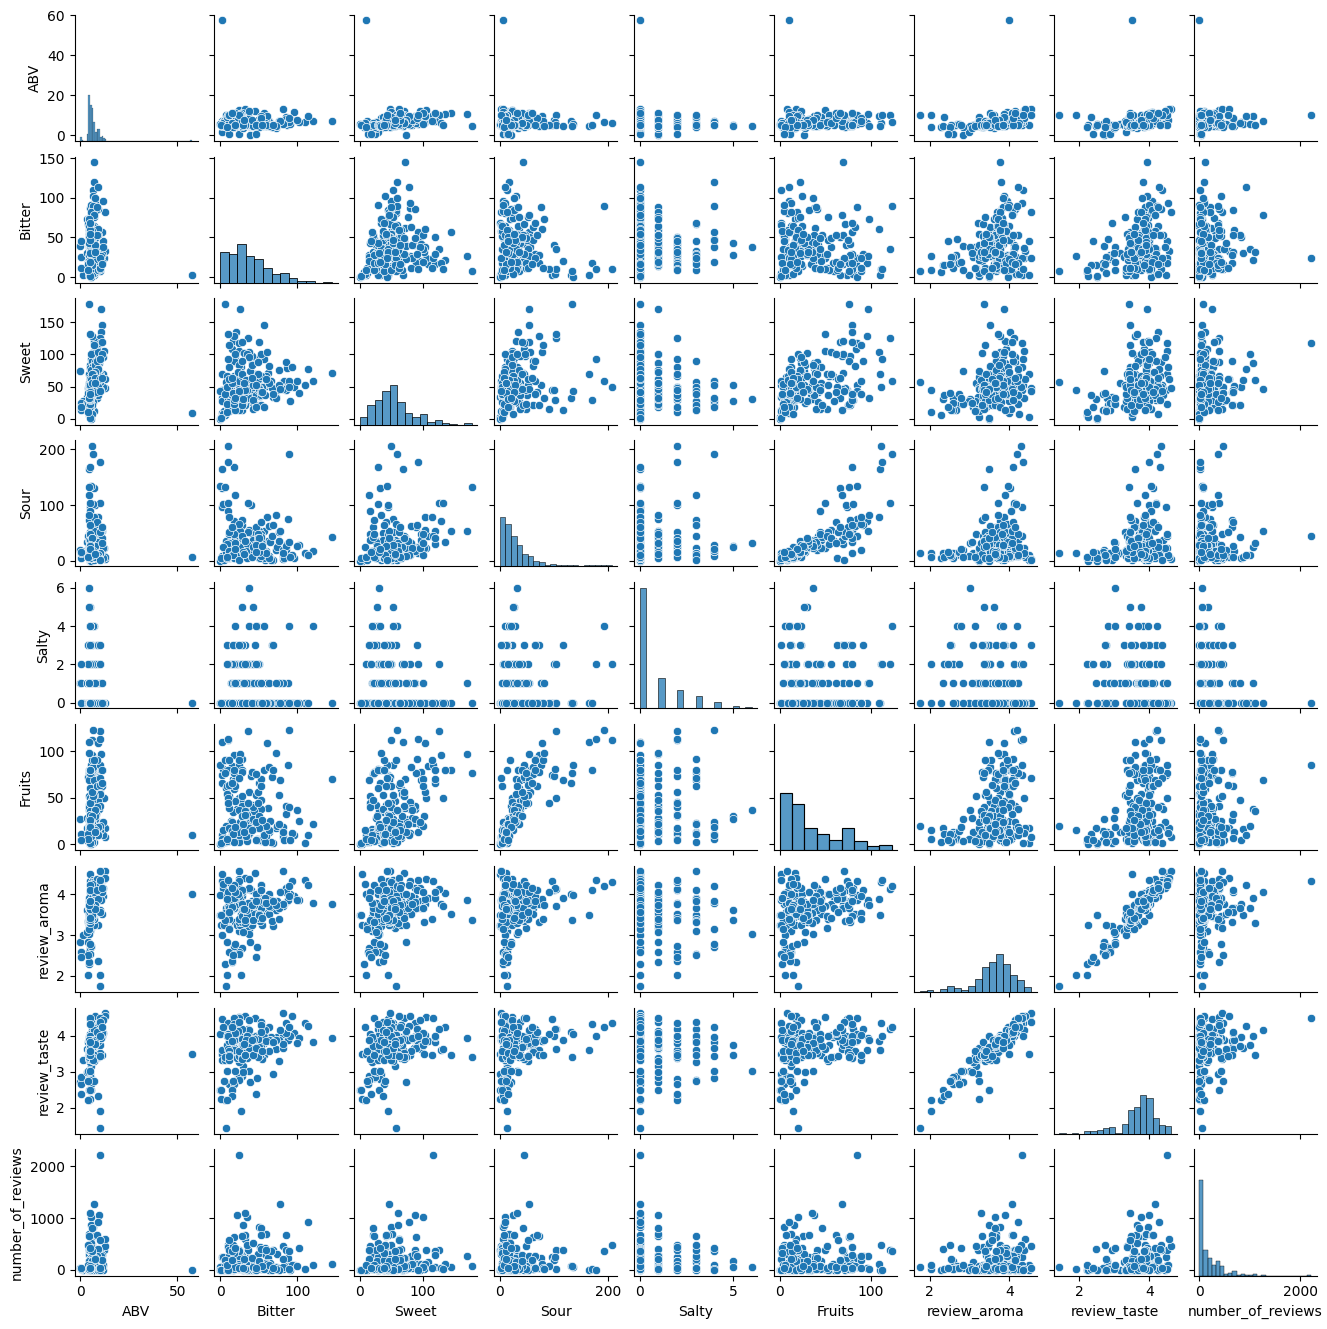

In [ ]:
sns.pairplot(df[num_cols], height=1.5)
plt.show()

Looking at these pairplots, we see an observation that has a an extremely high ABV. Since this may be an outlier, we take a closer look.

In [ ]:
df[df['ABV']>50]

,Name,Style,Brewery,Beer Name (Full),Description,ABV,Min IBU,Max IBU,Astringency,Body,...,Hoppy,Spices,Malty,review_aroma,review_appearance,review_palate,review_taste,review_overall,number_of_reviews,Rating
51,Schorschbock 57%,Bock - Eisbock,Schorschbräu,Schorschbräu Schorschbock 57%,Notes:,57.5,25,35,0,7,...,0,2,4,4.0,4.0,4.0,3.5,4.0,1,Mediocre


### Outlier Identification - 3+ Variable Outliers

HAC with Average Linkage

In [ ]:
X=num_df

In [ ]:
dm=pdist(X, metric='euclidean')
dist_mat=squareform(dm)
Z = linkage(dm, method='average')

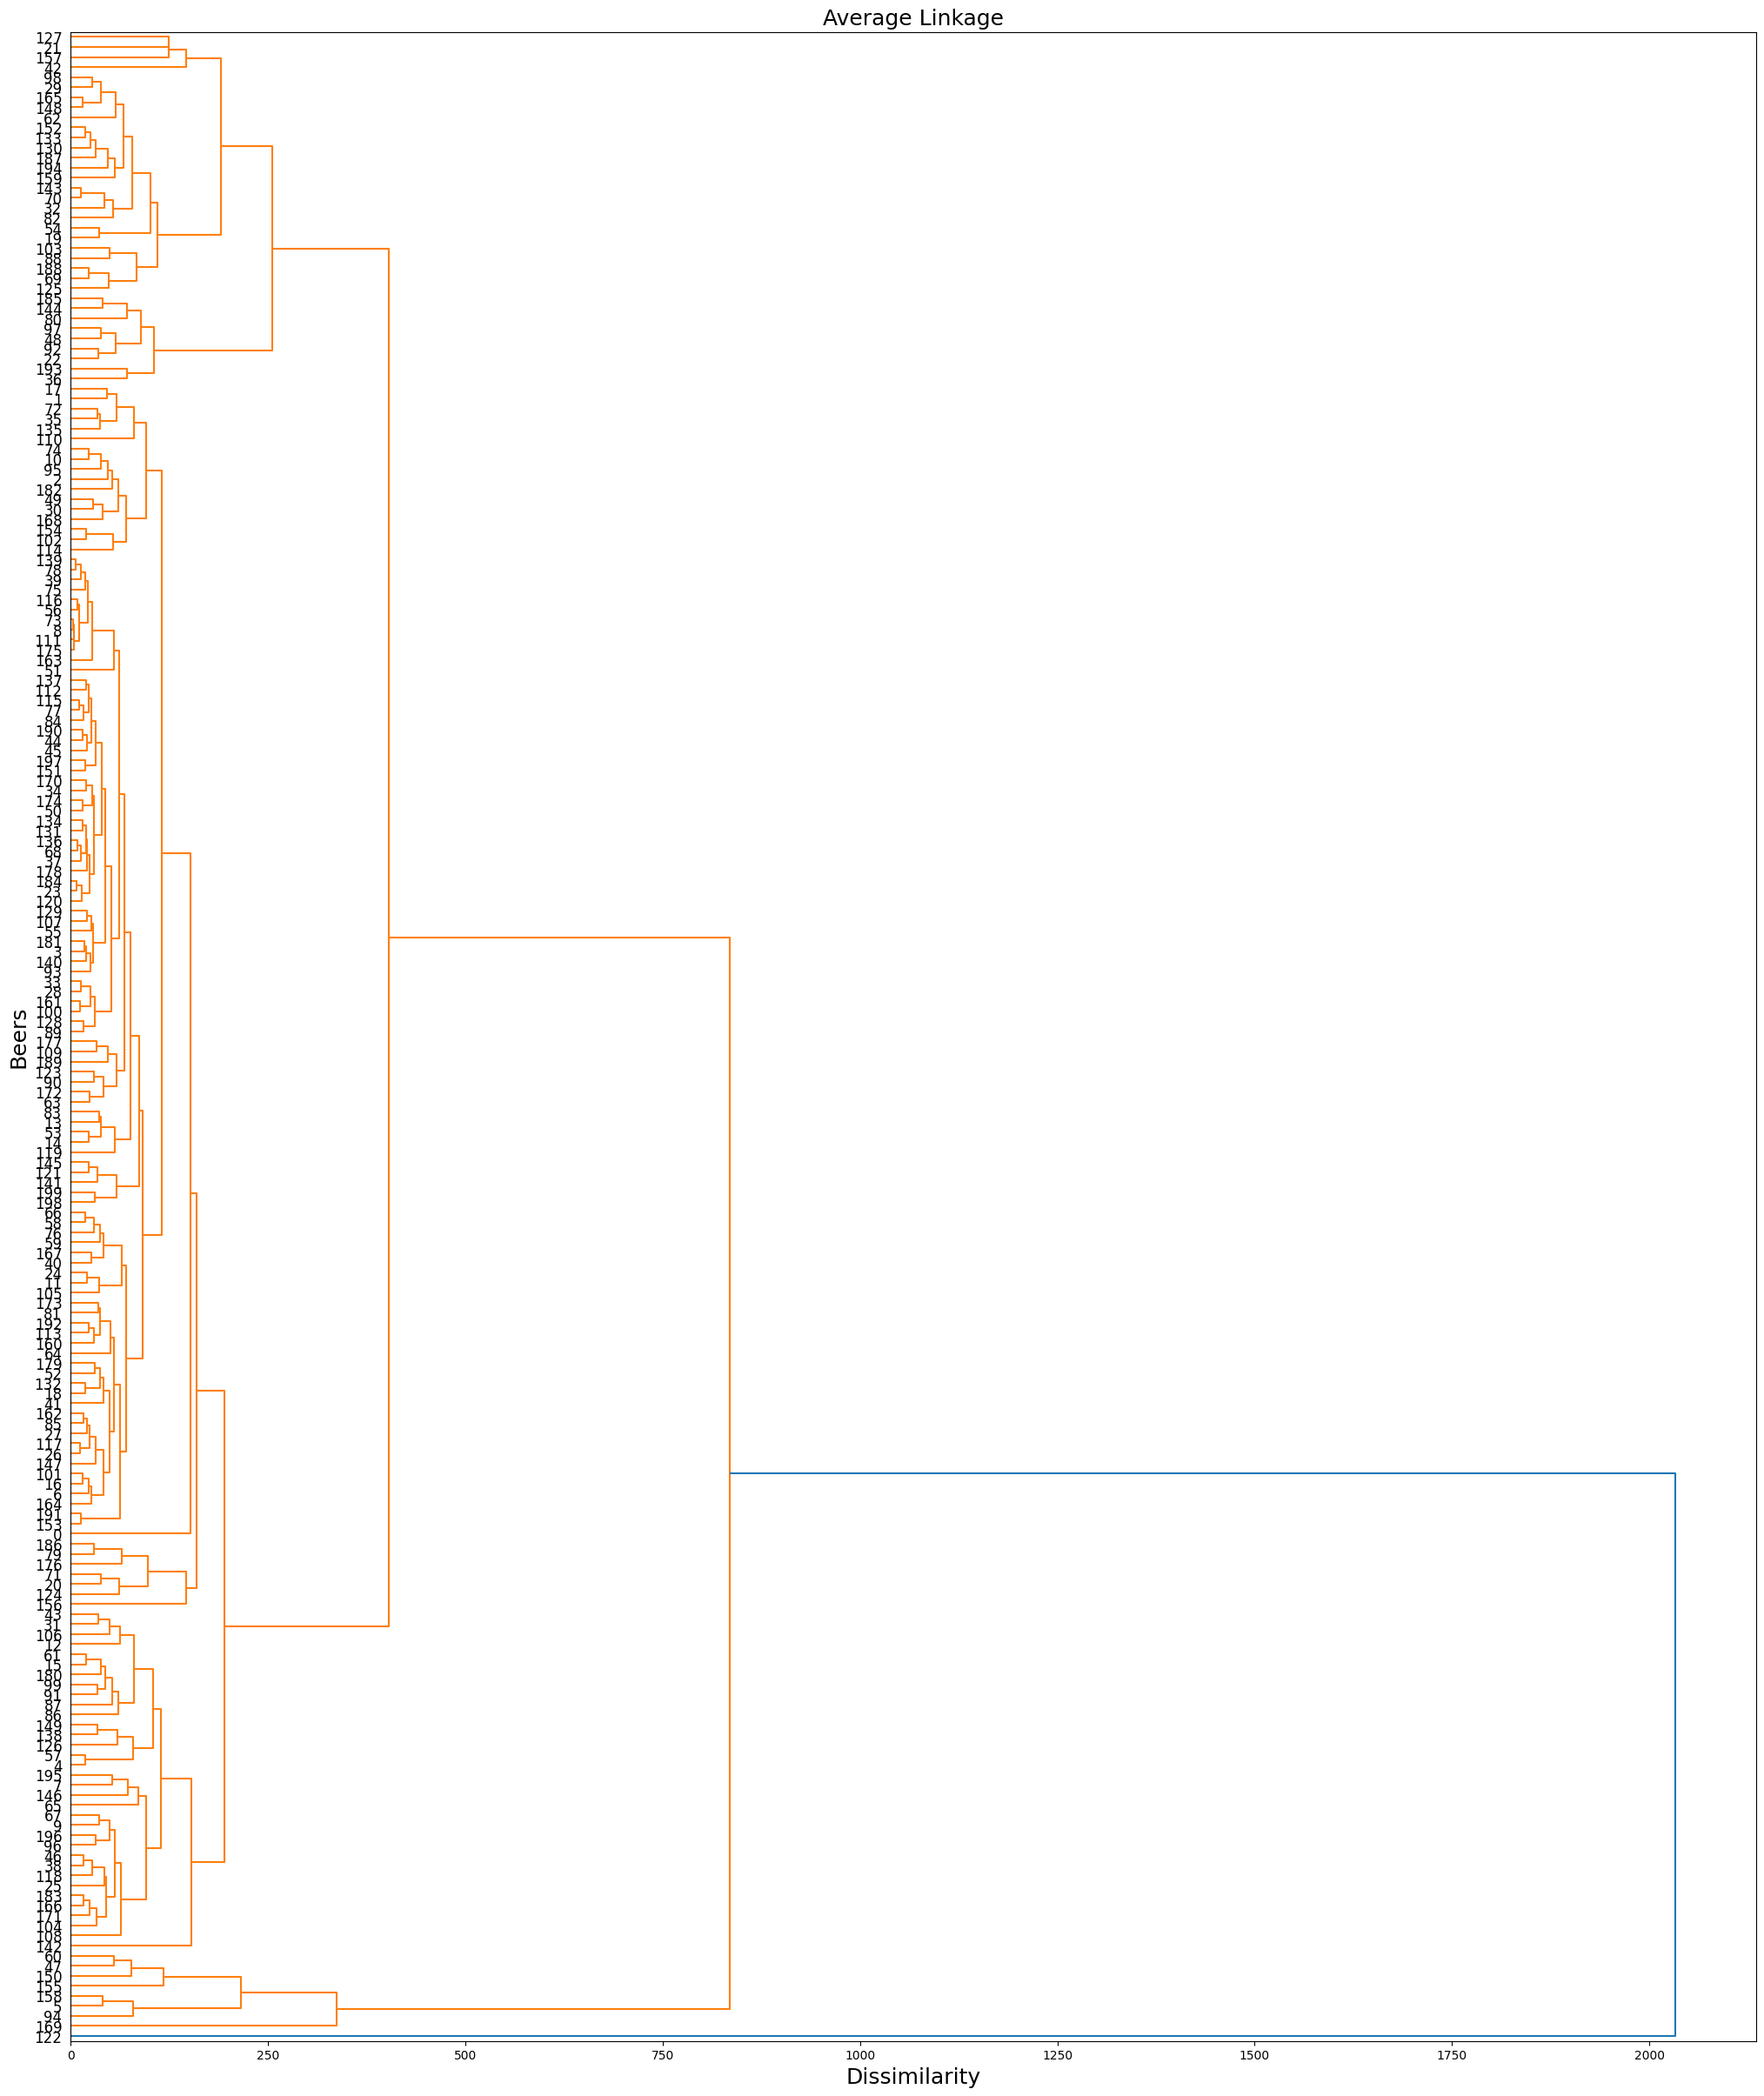

In [ ]:
fig, ax = plt.subplots(figsize=(25, 30))
d=dendrogram(Z, orientation='right', ax=ax)
ax.set_xlabel('Dissimilarity', fontsize=18)
ax.set_ylabel('Beers', fontsize=18)
plt.yticks(fontsize=12)
plt.title('Average Linkage', fontsize=18)
plt.show()

Looking at the dendogram, we see that observation 122 is the very last one to cluster with the remaining observations at very a high disimilarity score.

In [ ]:
num_df.iloc[122]

,122
ABV,10.000000
Bitter,24.000000
Sweet,117.000000
Sour,44.000000
Salty,0.000000
Fruits,85.000000
review_aroma,4.318448
review_taste,4.487145
number_of_reviews,2217.000000


Looking st the insights found later in our Descriptive Analystics part, we realize why this may be an outlier. Observation 122 has relatively high `ABV`, `Sweet`, `review_aroma`, `review_taste`, and `Fruits` values, each exceeding the 75th percentile for their respective attribute. This analysis does not necessarily suggest that there are additional outliers that we were not able to detect in our scatterplots. Observation 122 seems to be an outlier due to its relatively high number of reviews, which was also evident in the scatterplots.

### Outlier Consideration

- Since observation 51 has a very high ABV, and only one review, it may not be reliable. Observation 122 seems to be an outlier only because it has a high amount of reviews. Although this could be reliable data, it might throw off our algorithms in later steps. Including either outlier could also result in singleton clusters. Therefore, we remove both. \
- We also kept in mind that this dataframe is a small subset that covers less than 10% of the original dataset. This means an outlier in this dataset may not classify as an outlier in the larger, overall data.


- If any outliers are dropped, this could help as skewness would be reduced in the distribution of certain variables. A con of dropping outliers would be that we introduce bias into our model. We might also miss out on valuable information.


- Putting an outlier in its own singleton cluster is also an option. This would allow us to keep the data without forcing it to cluster with other data points, which could skew the nature of the cluster.
-  Although putting an outlier in a larger, further cluster is an option, again, it is not preferred as it might affect the overall accuracy of our clustering
- Identifying an outlier here could possibly affect what clustering algorithm we are going to choose. Again, there seems to be two stark outliers and we have chosen to remove them.

In [ ]:
df.drop(122, inplace=True)

In [ ]:
df = df[df['ABV']<50] #removed observation 51
df=df.reset_index()

#remake numerical and categorical dataframes
cat_df=df[cat_cols]
num_df=df[num_cols]

#### Noise Consideration and Identification

We created the following 4 plots:
* k=3 nearest neighbor sorted distance plot,
* k=4 nearest neighbor sorted distance plot,
* k=5 nearest neighbor sorted distance plot,
* k=6 nearest neighbor sorted distance plot.


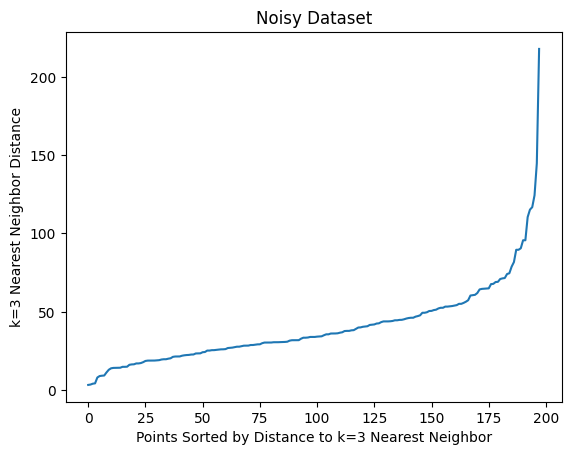

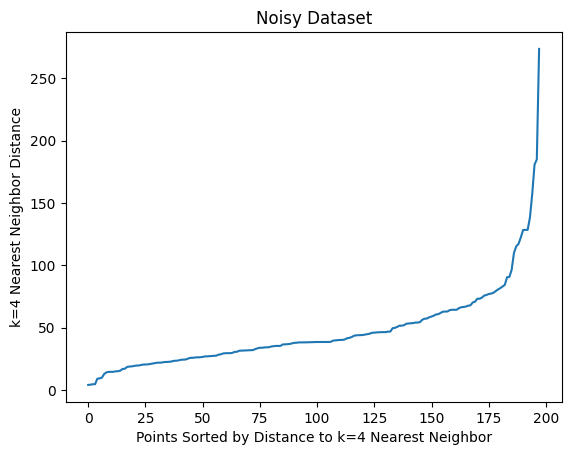

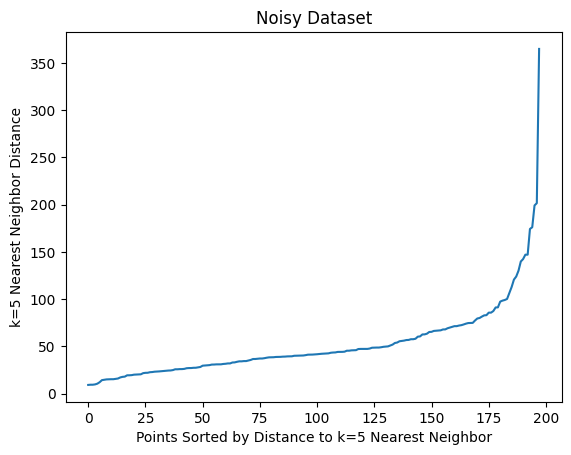

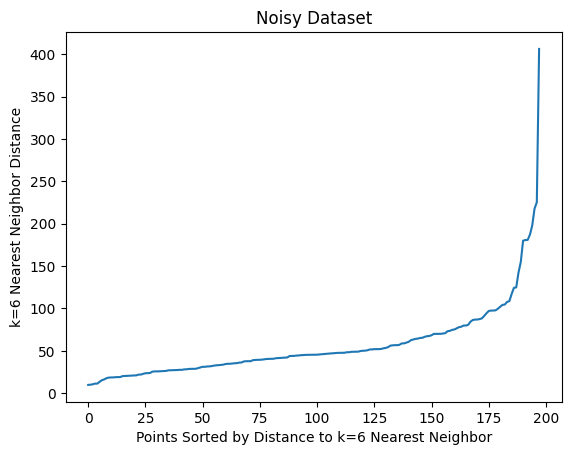

In [ ]:
for k in range(3, 7):
    nbrs=NearestNeighbors(n_neighbors=k, algorithm='ball_tree').fit(num_df)
    distances, indices=nbrs.kneighbors(num_df)

    plt.plot(np.sort(distances.T[k-1]))
    plt.xlabel('Points Sorted by Distance to k=%s Nearest Neighbor'%k)
    plt.ylabel('k=%s Nearest Neighbor Distance' %k)
    plt.title('Noisy Dataset')
    plt.show()

Observing the plots above, we see that there is a dramatic spike at around the 185 point mark. This tells us that barely 8% of the observations consist of noise points. Since this isn't a large amount of noise, we believe that it is okay to keep. However, we may have to keep this in mind in our clustering process as some algorithms are robust to some noise, while others are not. For example, although we plan on using k-means, we will also consider results from Fuzzy c-means due to it being able to handle noise in the data.

### Other Data Cleaning

Like mentioned previously, we did take some additional data cleaning steps. This included:
- Taking a randomized 200 row subset from the original dataset
- Transforming review_overall from a (continuous) numerical to a categorical variable
- Dropping 2 outliers to insure better results in our later algorithms (such as HAC)


## 4. Basic Descriptive Analytics

Basic summary statistics for numerical attributes:

In [ ]:
num_df.describe()

,ABV,Bitter,Sweet,Sour,Salty,Fruits,review_aroma,review_taste,number_of_reviews
count,198.000000,198.000000,198.000000,198.000000,198.000000,198.000000,198.000000,198.000000,198.000000
mean,6.417778,38.681818,54.449495,32.808081,0.772727,35.787879,3.631303,3.681024,187.217172
std,2.208726,26.793150,31.150771,35.920012,1.243813,30.002292,0.490968,0.520881,239.741884
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.744898,1.438776,1.000000
25%,5.000000,18.000000,33.000000,10.000000,0.000000,13.000000,3.415855,3.458614,22.500000
50%,6.000000,32.500000,50.000000,22.000000,0.000000,25.000000,3.703503,3.808258,83.500000
75%,7.450000,53.000000,68.500000,41.000000,1.000000,56.000000,3.941550,3.982886,262.750000
max,13.000000,145.000000,178.000000,206.000000,6.000000,123.000000,4.555921,4.620614,1270.000000


Categorical variable counts:

In [ ]:
df['Style'].value_counts()

,count
Style,
Stout - American,6
Kölsch,6
IPA - Black / Cascadian Dark Ale,5
Scotch Ale / Wee Heavy,5
Porter - American,5
...,...
Chile Beer,1
Barleywine - American,1
Porter - Robust,1


In [ ]:
df['Brewery'].value_counts()

,count
Brewery,
Boston Beer Company (Samuel Adams),7
Brasserie Cantillon,4
Smuttynose Brewing Company,3
Dark Horse Brewing Company,3
Saint Arnold Brewing Company,3
...,...
Rock Art Brewery,1
Clown Shoes,1
Stoudts Brewing Co.,1


In [ ]:
df['Rating'].value_counts()

,count
Rating,
Mediocre,98
Good,53
Bad,41
Horrible,5
Excellent,1


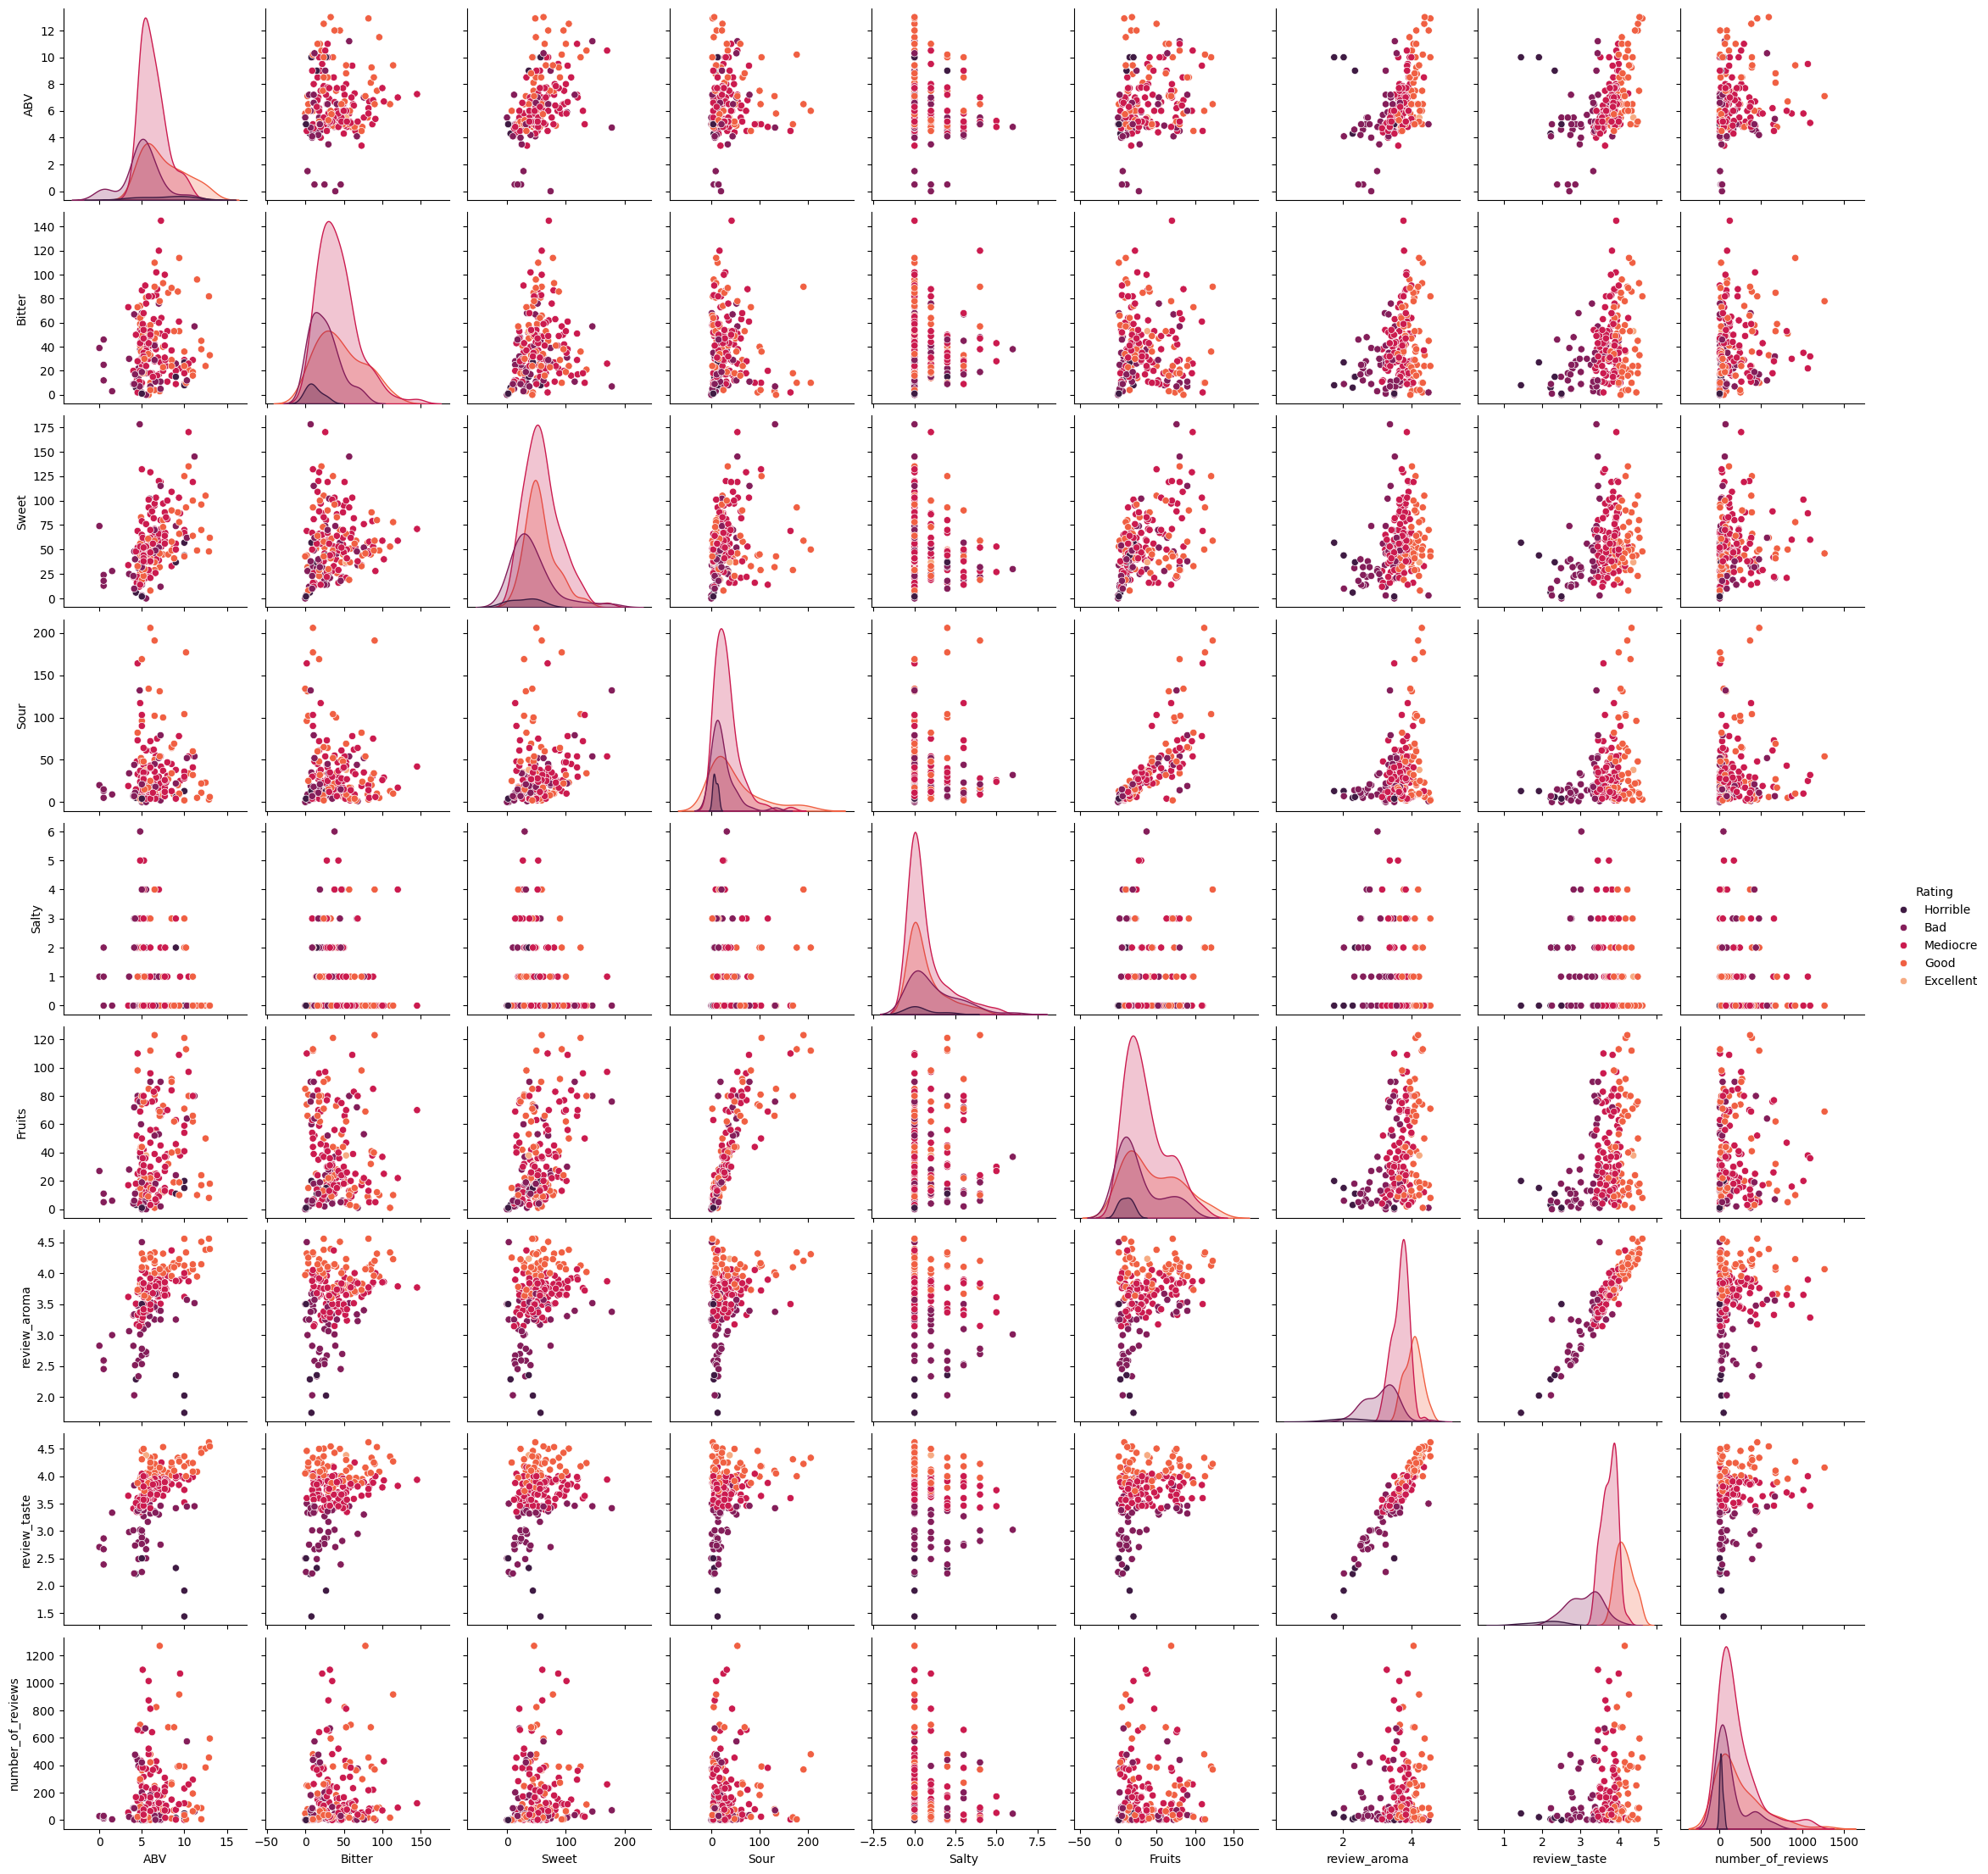

In [ ]:
df1= pd.concat([num_df, cat_df['Rating']], axis=1)

figout = sns.pairplot(df1, hue='Rating', palette='rocket')
plt.show()

Looking at the same numerical pairplot now color coded by `Rating`, we see that there are some patterns. For example, the 'Horrible' ratings tend to have lower `review_aroma` and `review_taste` values. This is no surprise, as the `Rating` column was built from `review_overall`. Someone's overall review likely takes into account both taste and aroma reviews. \
Going back to the pairwise relationships themselves, `Sour` and `Fruits` may have a slight positive linear relationship.

## 5. Scaling Decisions


Based on these summary statistics and scatterplots, we are choosing to scale this dataset. This will be helpful seeing as the `review_aroma` and `review_taste` variables range from 0 to 5, while the other numerical variables could surpass 200. Additionally, the y-axis of our Nearest Neighbor plots reached a whopping 1200, which means there are features in our data that have vastly different ranges.

In [ ]:
st_tmp = StandardScaler()

num_df_scaled = pd.DataFrame(st_tmp.fit_transform(num_df), columns=num_df.columns)
df_scaled = pd.concat([cat_df.reset_index(drop=True), num_df_scaled], axis=1)
df_scaled

,Style,Brewery,Rating,ABV,Bitter,Sweet,Sour,Salty,Fruits,review_aroma,review_taste,number_of_reviews
0,IPA - Black / Cascadian Dark Ale,Heavy Seas Beer,Mediocre,0.377743,3.978169,0.532650,0.256548,-0.622832,1.143207,0.279727,0.488746,-0.268539
1,Strong Ale - Belgian Dark,Brasserie Dupont sprl,Mediocre,0.945115,-0.848699,1.755616,0.340279,-0.622832,1.611021,0.582700,0.338058,-0.155632
2,Barleywine - English,Shipyard Brewing Co.,Bad,2.170638,0.685422,2.914215,0.591471,-0.622832,1.477360,-0.235703,-0.440068,-0.519442
3,Rye Beer - Roggenbier,Mill Street Brew Pub,Mediocre,-0.552746,-0.399688,-0.432849,0.312369,-0.622832,0.207580,0.272403,0.245975,-0.640712
4,Lambic - Fruit,Brasserie Cantillon,Good,-0.643525,-1.372545,-0.336299,1.763699,-0.622832,1.276869,1.398541,1.504006,0.275086
...,...,...,...,...,...,...,...,...,...,...,...,...
193,Tripel,Russian River Brewing Company,Good,2.079858,-0.848699,0.307367,0.758932,-0.622832,1.009546,1.042316,1.080222,0.028364
194,Old Ale,Saint Arnold Brewing Company,Mediocre,0.581997,-0.287435,0.049900,-0.580758,0.183186,-0.761463,0.011671,0.169771,0.086908
195,Low Alcohol Beer,Warsteiner Brauerei,Bad,-2.686063,0.273829,-1.173065,-0.497027,0.989203,-1.028785,-2.408874,-2.490412,-0.653257
196,Wheat Beer - American Pale,Captain Lawrence Brewing Co.,Good,-0.870474,1.284103,-0.690316,1.372957,0.183186,2.078835,0.199833,0.373344,-0.682529


In [ ]:
df_scaled.head(n=5)

,Style,Brewery,Rating,ABV,Bitter,Sweet,Sour,Salty,Fruits,review_aroma,review_taste,number_of_reviews
0,IPA - Black / Cascadian Dark Ale,Heavy Seas Beer,Mediocre,0.377743,3.978169,0.532650,0.256548,-0.622832,1.143207,0.279727,0.488746,-0.268539
1,Strong Ale - Belgian Dark,Brasserie Dupont sprl,Mediocre,0.945115,-0.848699,1.755616,0.340279,-0.622832,1.611021,0.582700,0.338058,-0.155632
2,Barleywine - English,Shipyard Brewing Co.,Bad,2.170638,0.685422,2.914215,0.591471,-0.622832,1.477360,-0.235703,-0.440068,-0.519442
3,Rye Beer - Roggenbier,Mill Street Brew Pub,Mediocre,-0.552746,-0.399688,-0.432849,0.312369,-0.622832,0.207580,0.272403,0.245975,-0.640712
4,Lambic - Fruit,Brasserie Cantillon,Good,-0.643525,-1.372545,-0.336299,1.763699,-0.622832,1.276869,1.398541,1.504006,0.275086


## 6. Clusterability and Clustering Structure

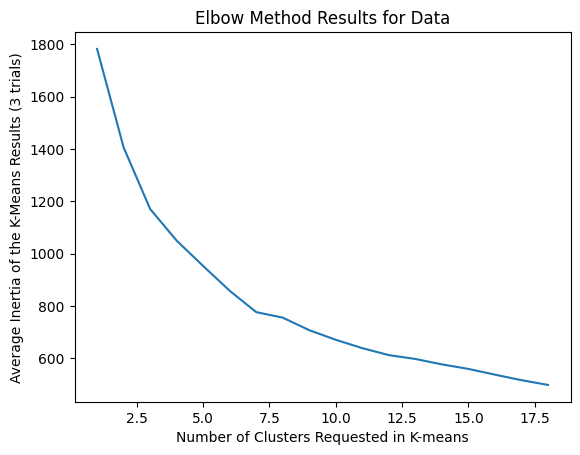

In [ ]:
from sklearn.cluster import KMeans
import numpy as np
import warnings
warnings.filterwarnings("ignore")

cluster_num_list=range(1,19)
avg_inertia_list=[]
for k in cluster_num_list:
  sub_inertia_list=[]
  for i in range(0,4):
    kmeans = KMeans(n_clusters=k, random_state=i).fit(num_df_scaled)
    sub_inertia_list.append(kmeans.inertia_)
  avg_inertia_list.append(np.average(sub_inertia_list))

plt.plot(cluster_num_list,avg_inertia_list)
plt.xlabel('Number of Clusters Requested in K-means')
plt.ylabel('Average Inertia of the K-Means Results (3 trials)')
plt.title('Elbow Method Results for Data')
plt.show()

### Clusterability:
The clear downward trend followed by a leveling-off behavior confirms that the data can be meaningfully partitioned into distinct clusters. This validates the dataset's clusterability.

### Elbow Plot:
There appears around k=7, suggesting that that is the optimal cluster number for the dataset.

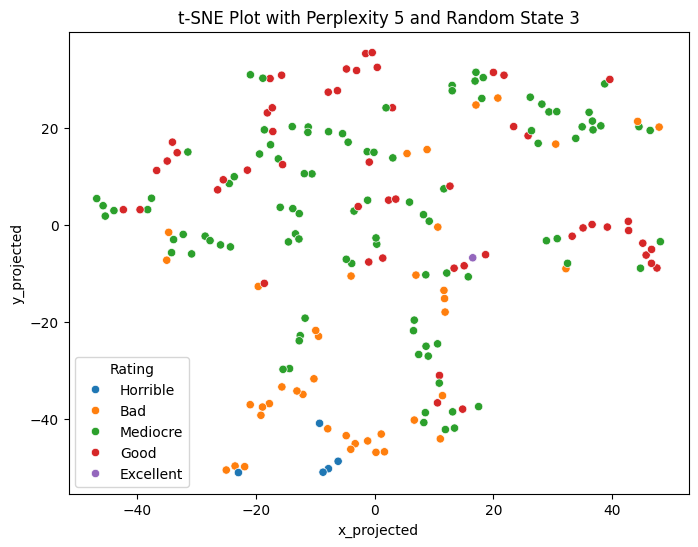

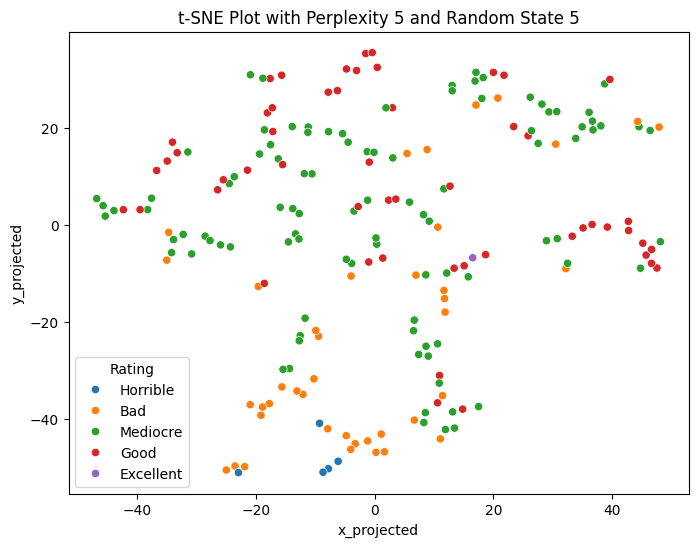

--------------------------------------------


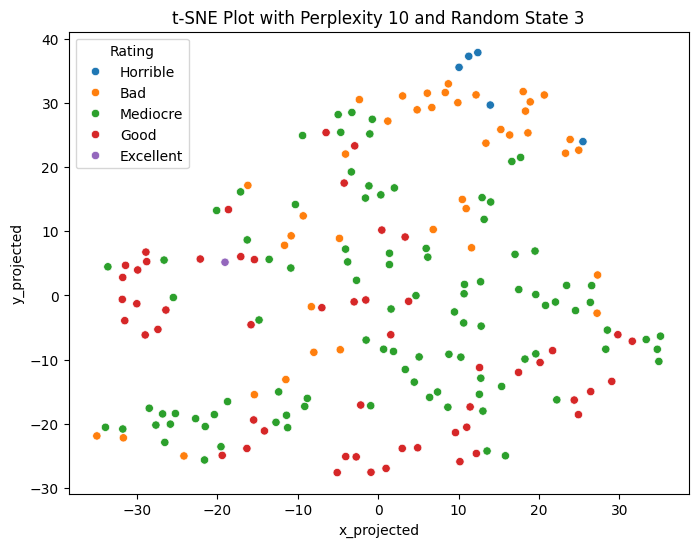

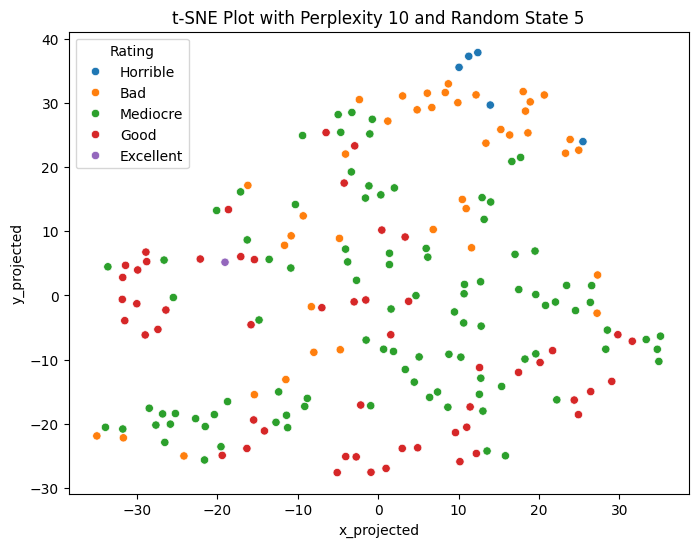

--------------------------------------------


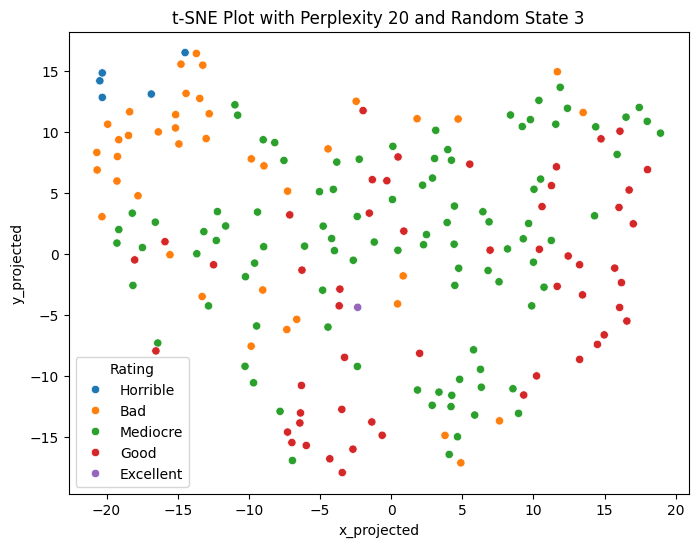

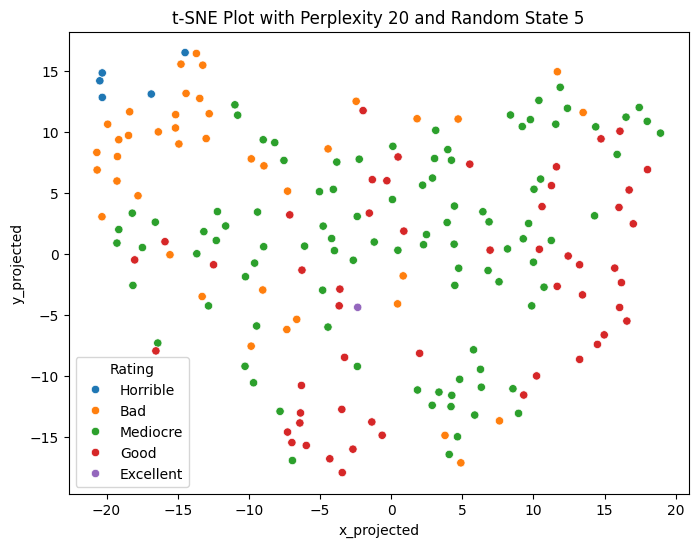

--------------------------------------------


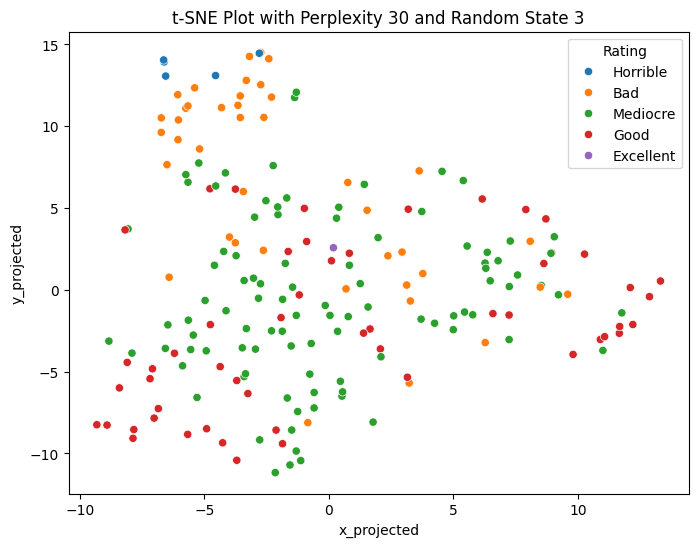

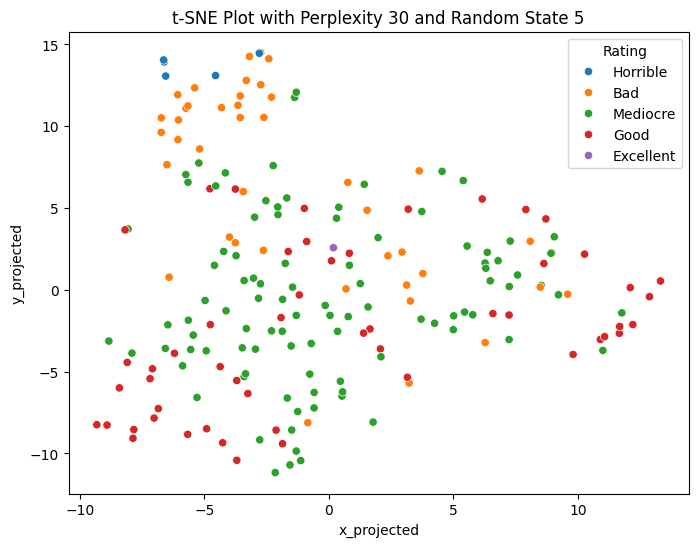

--------------------------------------------


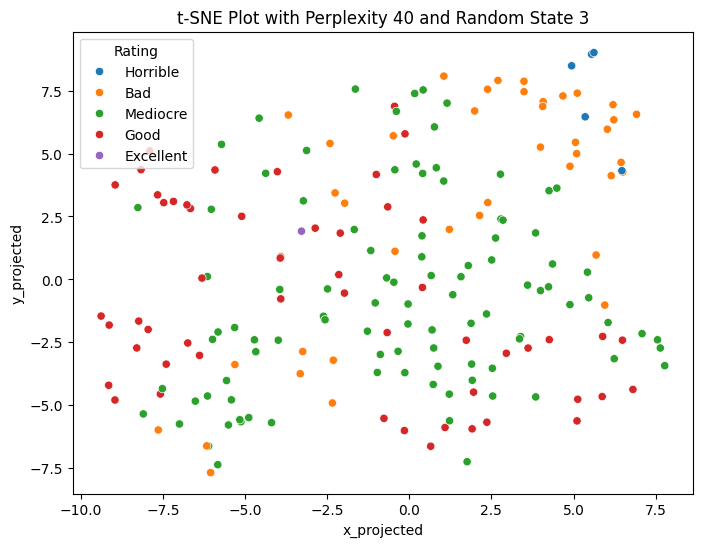

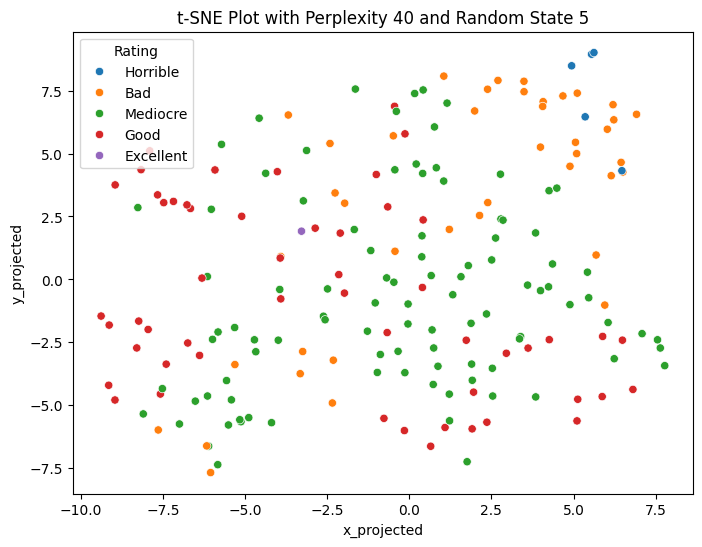

--------------------------------------------


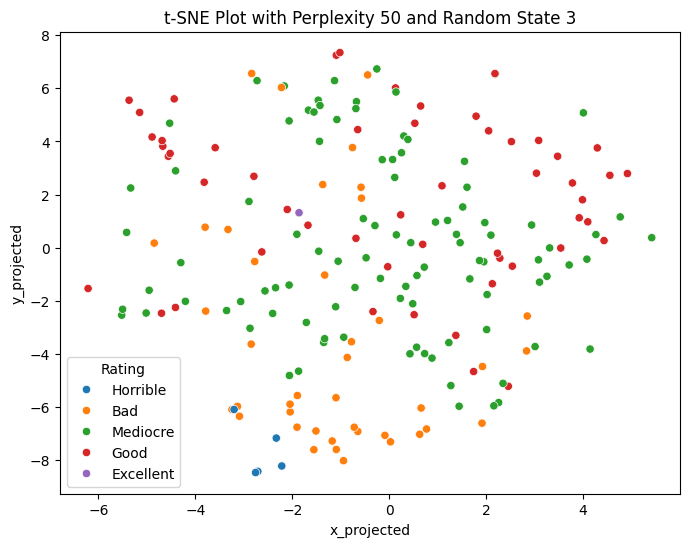

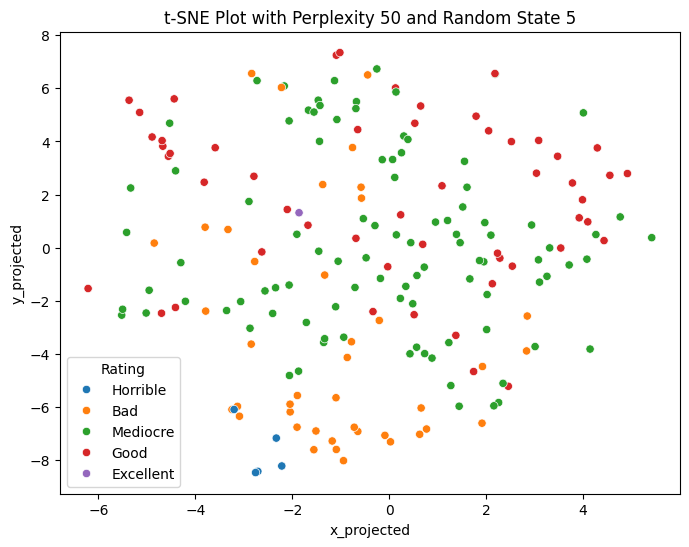

--------------------------------------------


In [ ]:
for perp in [5, 10, 20, 30, 40, 50]:
    for rs in [3, 5]:
        tsne = TSNE(n_components=2, perplexity=perp, random_state=rs)
        data_tsne = tsne.fit_transform(num_df_scaled)

        df_tsne = pd.DataFrame(data_tsne, columns=['x_projected', 'y_projected'])

        df_combo = pd.concat([df_scaled.reset_index(drop=True), df_tsne], axis=1)

        plt.figure(figsize=(8, 6))
        sns.scatterplot(data=df_combo, x='x_projected', y='y_projected', hue='Rating')
        plt.title(f't-SNE Plot with Perplexity {perp} and Random State {rs}')
        plt.show()

    print('--------------------------------------------')


### Clustering Structure

Looking at the t-SNE plots, we see there could be a presence of approximately 7 clusters corresponding to categories like "horrible," "bad," "mediocre," "good," and "excellent." However, due to significant overlap, exact delineation is challenging. In terms of shape, the clusters themselves are irregular and elongated rather than spherical, with some points scattered across the space, indicating non-uniform cluster shapes. We also see that sizes of these clusters seem rather imbalanced. Larger categories such as "mediocre" and "good" dominate, while "excellent" and "horrible" have comparatively fewer observations. Unfortunately, we also see many clusters that seem to be poorly separated. For example, "mediocre" overlaps significantly with "good" and "bad," indicating that the features do not fully distinguish these groups. Finally, for any potential nested cluster relationships, the t-SNE plots do not show strong evidence of nested clustering. Instead, they reveal overlapping groups without clear hierarchical structures.

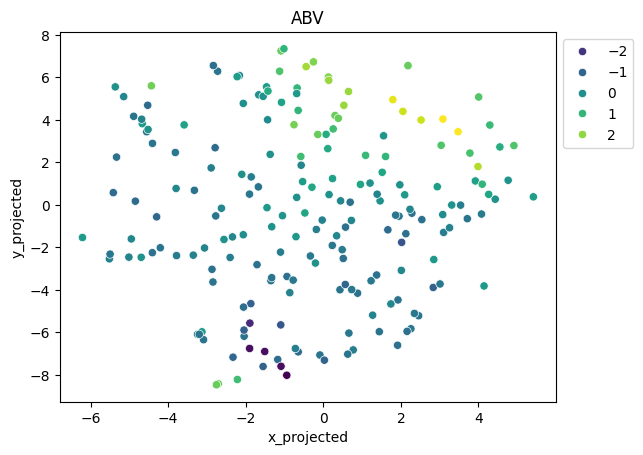

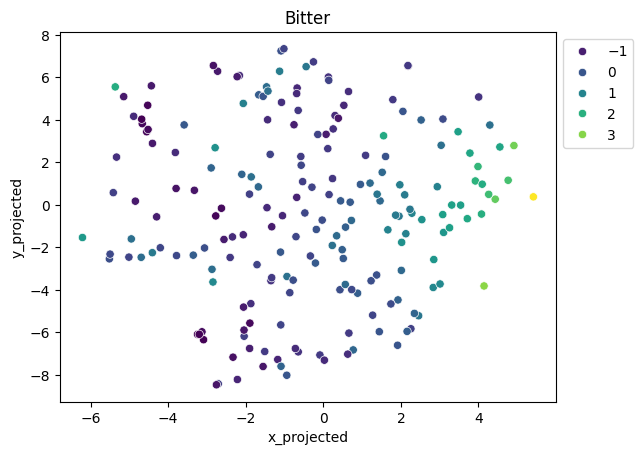

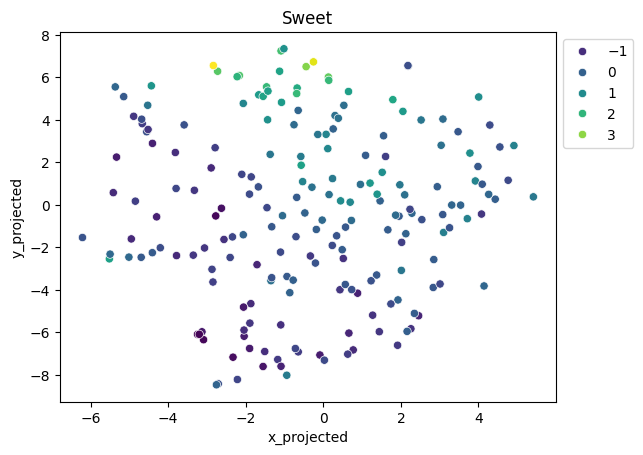

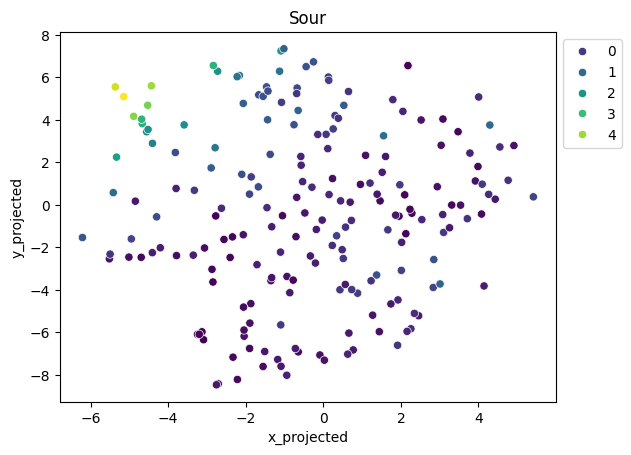

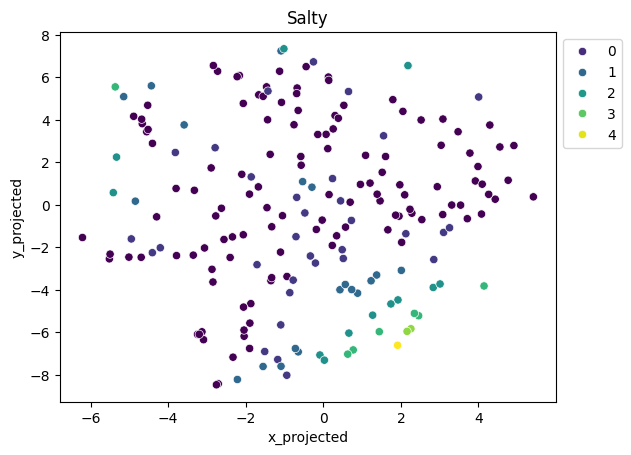

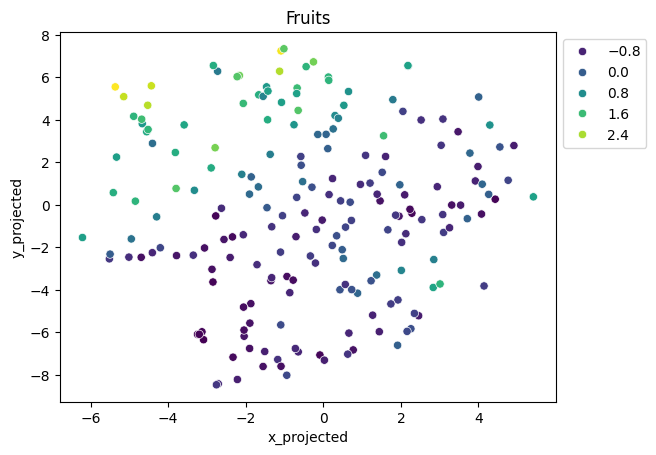

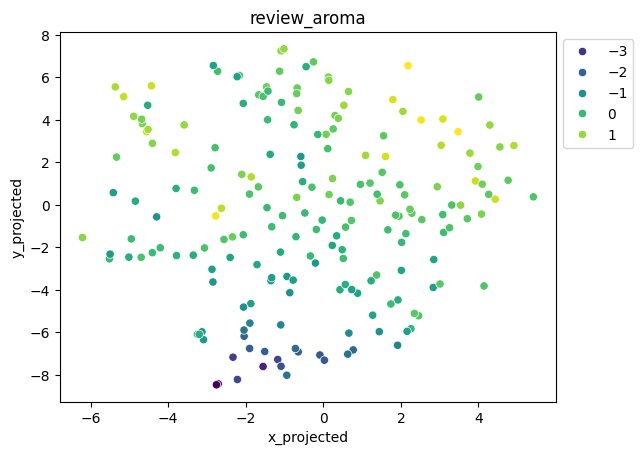

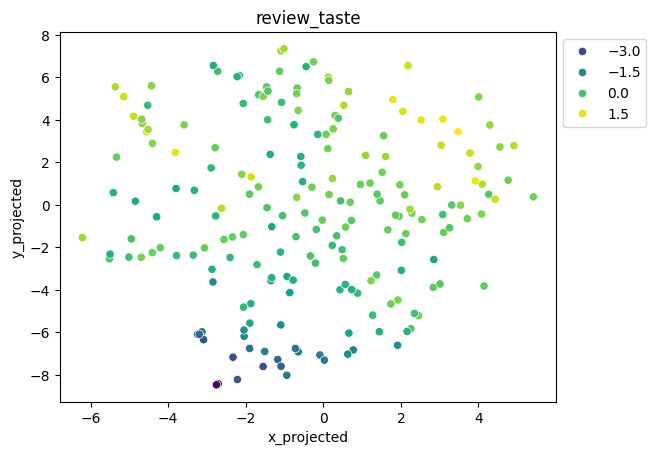

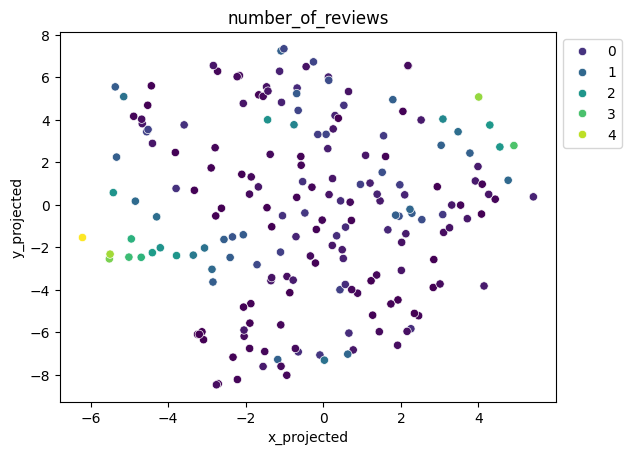

In [ ]:
for col in num_df_scaled.columns:
    sns.scatterplot(x='x_projected', y='y_projected', data=df_combo, hue=col, palette='viridis')
    plt.title(col)
    plt.legend(bbox_to_anchor=(1, 1))
    plt.show()


### Association Between Attributes and Clusters:
Attributes like Sweet, Sour, and Bitter show patterns where high or low values (e.g., yellow or purple) are grouped in specific regions, indicating some association with clusters. Attributes like review_aroma and number_of_reviews are more spread out, showing weaker clustering.

### Clear vs Overlapping Clusters:
Some attributes (e.g., Sweet) form clear localized clusters. Other attributes (e.g., Sour and Salty) have overlapping regions, showing less distinct separation.

### Stronger Attributes for Clustering:
Features like ABV and Sweet are better associated with clusters compared to attributes like number_of_reviews.

Four Original Dataset Properties That t-SNE Plots Cannot Fully Represent:

T-SNE emphasizes local relationships but distorts the global structure. For example, distances between far-apart clusters in the plot may not reflect actual distances in the high-dimensional space. T-SNE does not preserve the actual size or density of clusters. A dense cluster in the original dataset might appear larger and more diffuse in the plot, and vice versa. T-SNE does not indicate which features contributed most to the clustering. It combines all dimensions without showing which attributes drive the observed separation.
T-SNE cannot reliably show hierarchical or nested relationships between clusters. If there are subtle overlaps or parent-child relationships between groups, they may not be accurately reflected in the visualization.
These limitations mean that t-SNE should be used as an exploratory tool, and its outputs should be interpreted alongside other analytical methods.



---



## 7. Clustering Algorithm Selection Motivation

K-Means

K-Means allows us to group beers with similar flavor and sensory attributes, directly supporting our goal of identifying patterns to aid breweries and marketers in refining products and targeting consumers. It also works well with our numerical variables (ABV, Bitter, Sweet, etc.). This algorithm is suitable for datasets with moderately distinct and compact clusters, as suggested by our exploratory t-SNE analysis. Its easily adjustable cluster count aligns with our need to experiment with segmentation granularity.






Hierarchical Clustering

Hierarchical Clustering allows us to explore nested relationships between beers, uncovering subgroups within broader clusters. This can help breweries analyze similarities between different beer styles or flavors and refine their products accordingly. It also does not assume a predefined number of clusters, enabling us to explore the data structure flexibly. Suitable for datasets where overlapping or nested clusters are expected, as observed in our exploratory t-SNE analysis. The algorithm produces a dendrogram, which visually represents how beers cluster together at different levels, providing insights into hierarchical relationships. This helps identify broader flavor categories and smaller subgroups within these categories.


Fuzzy clustering would be beneficial given the overlapping nature of beer profiles observed in the dataset. It allows beers to belong to multiple clusters with varying degrees of membership, which aligns with:
Overlapping Characteristics: Captures beers that share attributes, reflecting their true nature.

Hierarchical clustering would be beneficial for this dataset and research motivation. It provides insights into nested relationships between beers, which can be valuable in the following ways:
Understanding Nested Similarities: Hierarchical clustering reveals broader groups and finer subgroups, helping breweries analyze flavor trends at multiple levels. This approach aligns with our goal of uncovering flavor trends and provides breweries with both high-level and detailed insights.

## 8. Clustering Algorithm #1 - K-Means


In [ ]:
X=num_df_scaled.copy()

#### Selecting Parameters

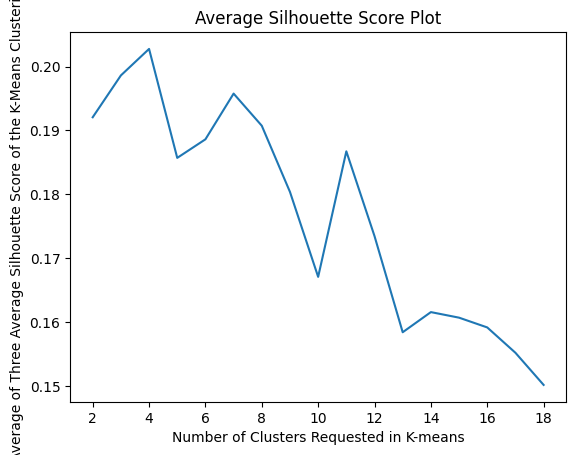

In [ ]:
#Evaluating for k=2,3,...,14 clusters
cluster_num_list=range(2,19)

#Generating a List of Average Average Silhouette Scores
avg_avg_sil_score_list=[]
for k in cluster_num_list:
    avg_sil_score_list=[]
    for i in range(1):
        #Clusters the dataset
        kmeans=KMeans(n_clusters=k, random_state=seed).fit(X)

        #Extract the cluster labels of the clustering
        cluster_labels = kmeans.labels_

        #Finds the average silhoutte score of ALL objects in the given clustering
        avg_sil_score=silhouette_score(X, cluster_labels)

        #Appends this
        avg_sil_score_list.append(avg_sil_score)
    #print('Average Silhouette Score with k=%s Clusters'%(k))
    #print(avg_sil_score_list)

    #Takes the average of the three average silhouette scores (from each of the three clustering with k clusters produced)
    avg_avg_sil_score_list.append(np.average(avg_sil_score_list))

#Plot it
plt.plot(cluster_num_list,avg_avg_sil_score_list)
plt.xlabel('Number of Clusters Requested in K-means')
plt.ylabel('Average of Three Average Silhouette Score of the K-Means Clusterings')
plt.title('Average Silhouette Score Plot')
plt.show()

The average silhouette scores peak at k=4, k=7, and k=11, which suggests that these could be good numbers of clusters to use for K-means.

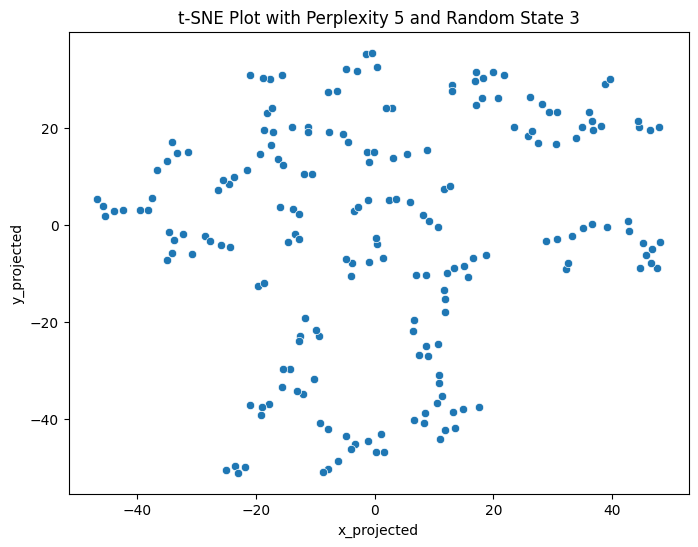

In [ ]:
for perp in [5]:
    for rs in [3]:
        tsne = TSNE(n_components=2, perplexity=perp, random_state=rs)
        data_tsne = tsne.fit_transform(num_df_scaled)

        df_tsne = pd.DataFrame(data_tsne, columns=['x_projected', 'y_projected'])

        df_combo = pd.concat([df_scaled.reset_index(drop=True), df_tsne], axis=1)

        plt.figure(figsize=(8, 6))
        sns.scatterplot(data=df_combo, x='x_projected', y='y_projected')
        plt.title(f't-SNE Plot with Perplexity {perp} and Random State {rs}')
        plt.show()

To determine how many clusters we should use during K-Means, we can take a look at one of the T-SNE plots from earlier. This specific plot was selected because it had the best separation between clusters. We can see approximately 7-8 clusters, but they are still difficult to distinguish. Because this method of selecting a number of clusters is subjective, we will also look at the K-Means elbow plot.

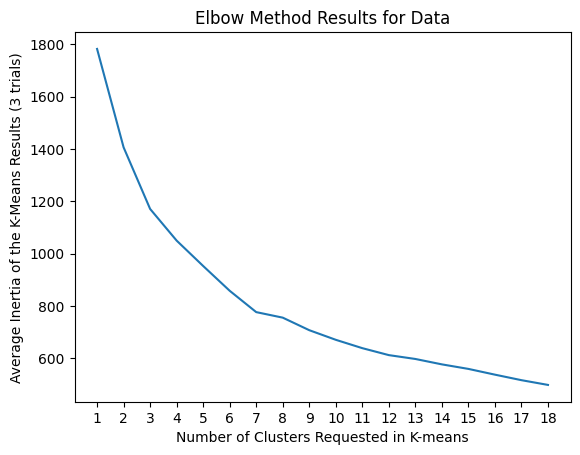

In [ ]:
cluster_num_list=range(1,19)
avg_inertia_list=[]
for k in cluster_num_list:
  sub_inertia_list=[]
  for i in range(0,4):
    kmeans = KMeans(n_clusters=k, random_state=i).fit(X)
    sub_inertia_list.append(kmeans.inertia_)
  avg_inertia_list.append(np.average(sub_inertia_list))

plt.plot(cluster_num_list,avg_inertia_list)
plt.xlabel('Number of Clusters Requested in K-means')
plt.ylabel('Average Inertia of the K-Means Results (3 trials)')
plt.title('Elbow Method Results for Data')
plt.xticks(np.arange(1,19,1))
plt.show()

The elbow plot considers clusterings with k=1, k=2, ..., k=18 clusters. There appears to be small elbows at k=7, so k-means is detecting a clustering structres with k=7 clusters. This supports what the T-SNE and silhouette score plots suggested. For our analysis, we will go with k=7 clusters.

#### Clustering

In [ ]:
kmeans=KMeans(n_clusters=7,random_state=seed).fit(num_df_scaled)
X['predicted cluster']=kmeans.labels_
X.head()
X['predicted cluster'].value_counts()

,count
predicted cluster,
1,56
4,36
2,26
6,26
0,23
5,17
3,14


#### Analysis

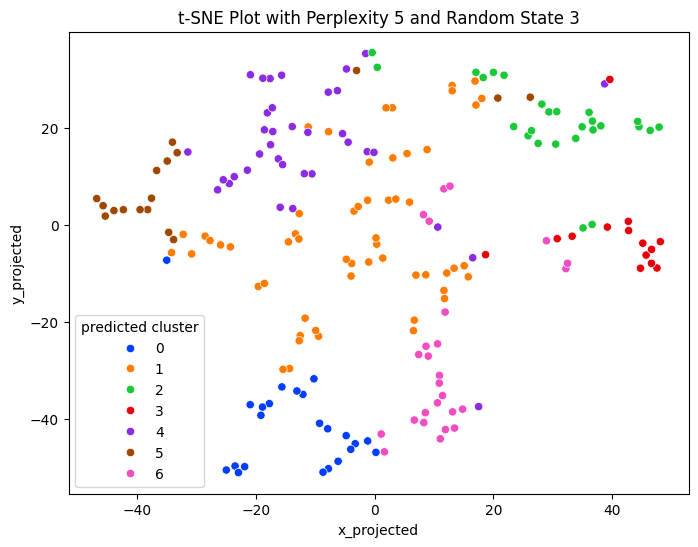

In [ ]:
for perp in [5]:
    for rs in [3]:
        tsne = TSNE(n_components=2, perplexity=perp, random_state=rs)
        data_tsne = tsne.fit_transform(num_df_scaled)

        df_tsne = pd.DataFrame(data_tsne, columns=['x_projected', 'y_projected'])

        df_combo = pd.concat([X.reset_index(drop=True), df_tsne], axis=1)

        plt.figure(figsize=(8, 6))
        sns.scatterplot(data=df_combo, x='x_projected', y='y_projected', hue='predicted cluster', palette='bright')
        plt.title(f't-SNE Plot with Perplexity {perp} and Random State {rs}')
        plt.show()

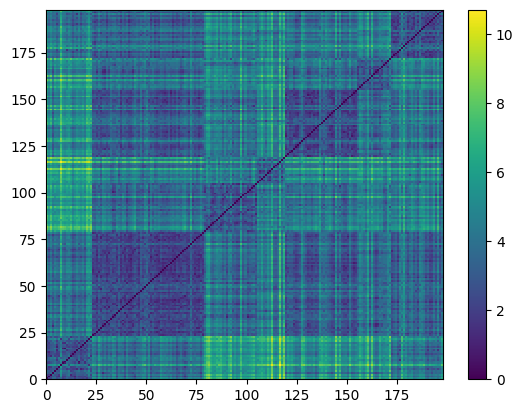

In [ ]:
#Cluster-sorted similarity matrix
df_sort=X.sort_values(by=['predicted cluster'])
df_sort=df_sort.drop(['predicted cluster'], axis=1)

#Create a distance matrix
dist_mat = squareform(pdist(df_sort))

#Then visualize the distance matrix with a heat map.
plt.pcolormesh(dist_mat)
plt.colorbar()
N = len(df_sort)
plt.xlim([0,N])
plt.ylim([0,N])
plt.show()

Cluster 0 is farthest away from clusters 2 and 3 because the average distance between cluster 0 and the other two is larger than the distance between other pairs of clusters. Cluster 0 is also pretty far away from cluster 4. The two clusters that are closest to each other seem to be cluster 1 and cluster 4. According to this plot, cluster 1 seems to have the highest cohesion and lowest sparsity. Clusters 3 and 5 are smaller and appear to be more sparse.

For n_clusters = 7 The average silhouette_score is : 0.33070174505170813


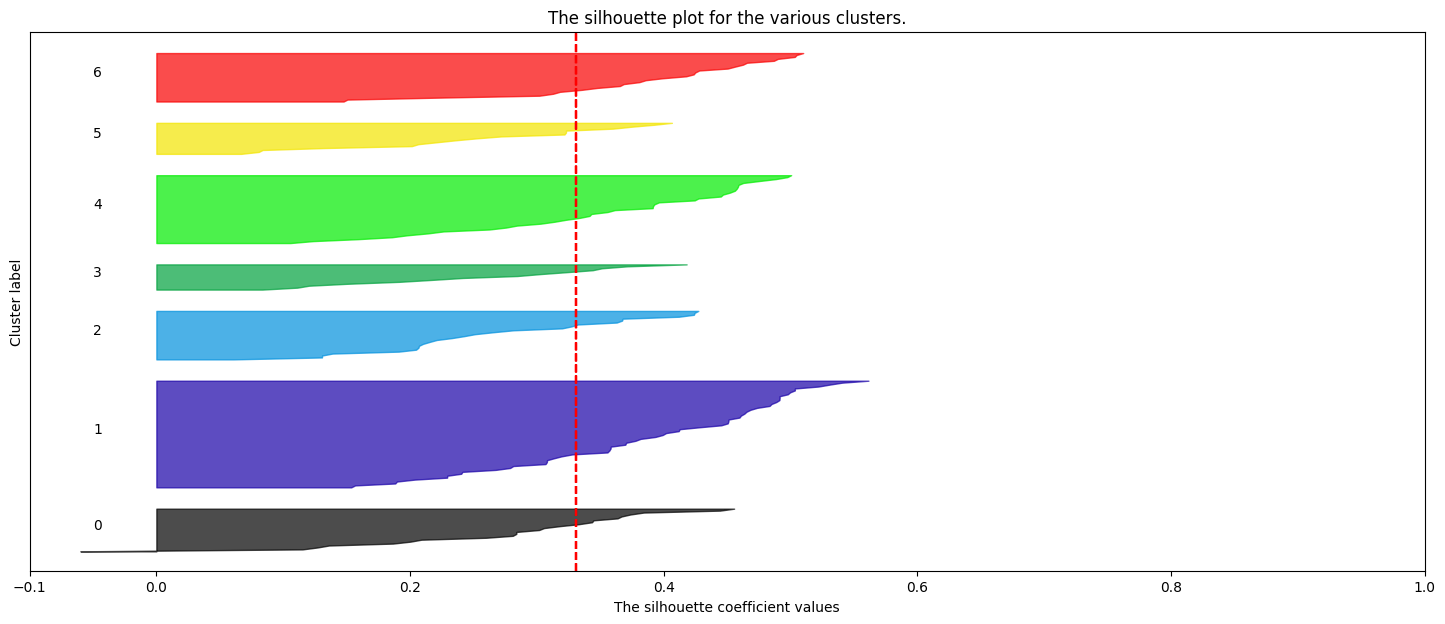

In [ ]:
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
#silhouette plot
def show_silhouette_plots(X,cluster_labels):

    # This package allows us to use "color maps" in our visualizations
    import matplotlib.cm as cm

    #How many clusters in your clustering?
    n_clusters=len(np.unique(cluster_labels))

    # Create a subplot with 1 row and 2 columns
    fig, ax1 = plt.subplots(1, 1)
    fig.set_size_inches(18, 7)

    # The 1st subplot is the silhouette plot
    # The silhouette coefficient fcan range from -1, 1 but in this example all
    # lie within [-0.1, 1]
    ax1.set_xlim([-0.1, 1])
    # The (n_clusters+1)*10 is for inserting blank space between silhouette
    # plots of individual clusters, to demarcate them clearly.
    ax1.set_ylim([0, len(X) + (n_clusters + 1) * 10])


    # The silhouette_score gives the average value for all the samples.
    # This gives a perspective into the density and separation of the formed
    # clusters
    silhouette_avg = silhouette_score(X, cluster_labels)
    print("For n_clusters =", n_clusters,
          "The average silhouette_score is :", silhouette_avg)

    # Compute the silhouette scores for each sample
    sample_silhouette_values = silhouette_samples(X, cluster_labels)

    y_lower = 10
    for i in range(n_clusters):
        # Aggregate the silhouette scores for samples belonging to
        # cluster i, and sort them
        ith_cluster_silhouette_values = \
            sample_silhouette_values[cluster_labels == i]


        ith_cluster_silhouette_values.sort()

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax1.fill_betweenx(np.arange(y_lower, y_upper),
                          0, ith_cluster_silhouette_values,
                          facecolor=color, edgecolor=color, alpha=0.7)

        # Label the silhouette plots with their cluster numbers at the middle
        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

        # Compute the new y_lower for next plot
        y_lower = y_upper + 10  # 10 for the 0 samples

        ax1.set_title("The silhouette plot for the various clusters.")
        ax1.set_xlabel("The silhouette coefficient values")
        ax1.set_ylabel("Cluster label")

        # The vertical line for average silhouette score of all the values
        ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

        ax1.set_yticks([])  # Clear the yaxis labels / ticks
        ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])


    plt.show()

    return
cluster_labels=kmeans.labels_
show_silhouette_plots(X, cluster_labels)

Cluster 0 is the only cluster with negative silhouette scores, which means that it has points that are closer to a different cluster. This cluster is not very cohesive. The rest of the clusters only have positive silhouette scores, so they are relatively more cohesive. Cluster 1 has a pretty high average silhouette score, so it is the most cohesive cluster. Cluster 6 also appears to have a relatively high average silhouette score. The average silhouette score of 0.3307 is closer to 0 than 1, which means that the clusters aren't great, but they could be worse.

The T-SNE plot colored by predicted clusters suggested that many of our clusters are not convex or well separated. This means that many clustering algoritms may have a hard time separating the different clusters, including K-means. Because our clusters are not convex, a cluster-sorted similarity matrix or silhouette plot might not be the best technique to use.

Based on the T-SNE plot, cluster 1 seemed to "take over" parts of what we thought would be separate clusters. In the T-SNE plot, we expected the cluster in the top right corner containing mostly cluster 2's green points to be well separated enough it was its own inherent cluster, but it contained points from clusters 1, 3, 4, and 5 as well. Similarly, we expected cluster 3's red points in the middle of the right side to be their own inherent cluster because it looked fairly well separated on the T-SNE plot, but the cluster also contained points from clusters 2 and 6.

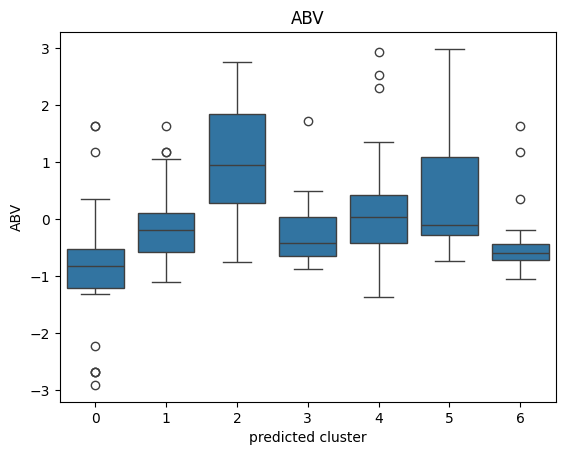

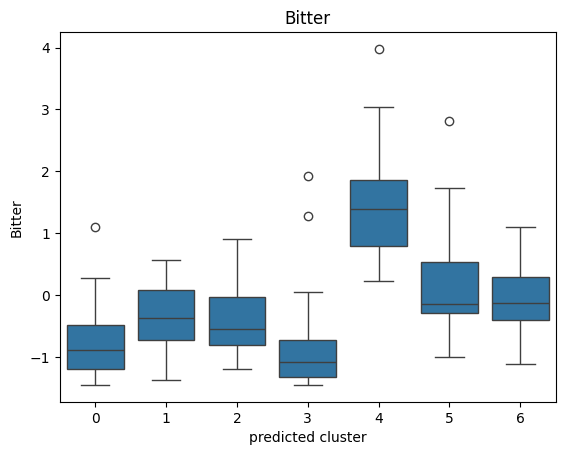

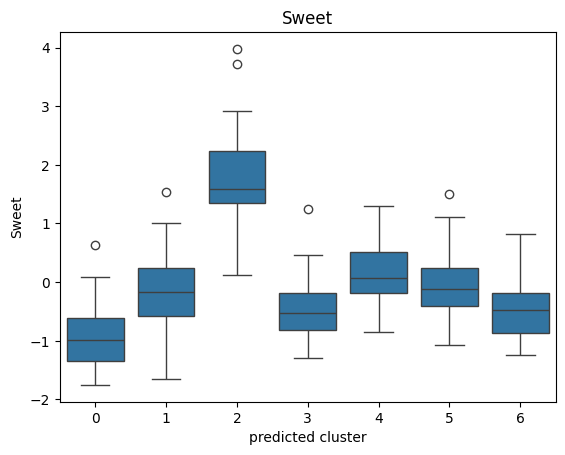

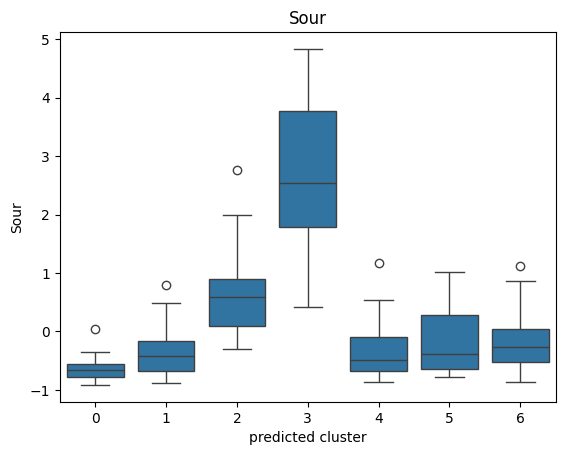

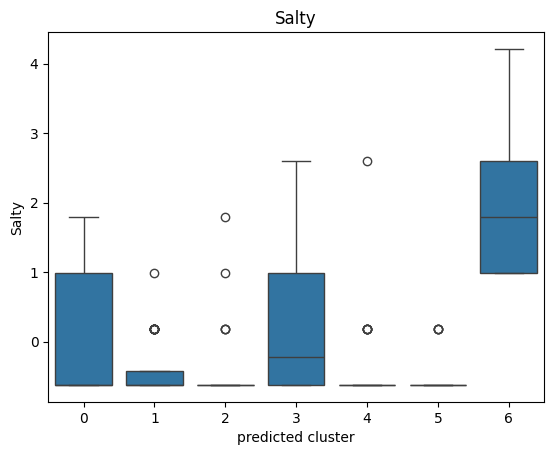

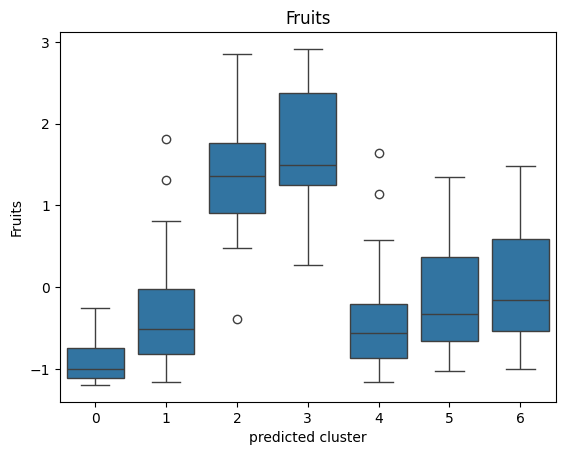

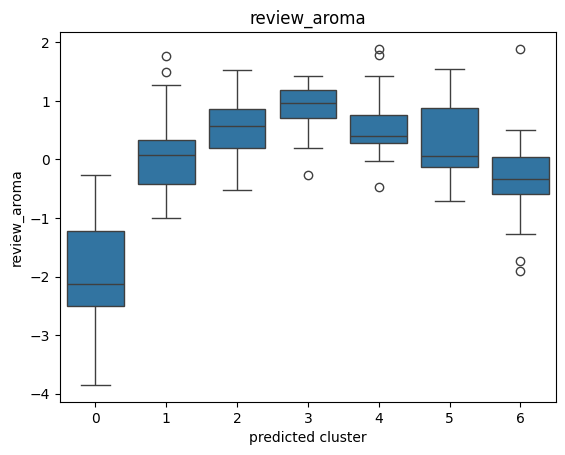

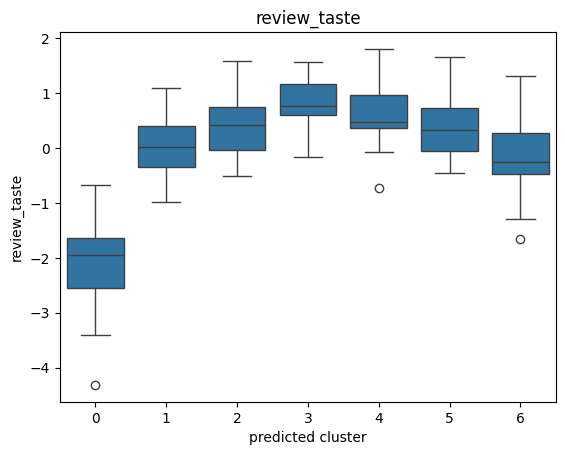

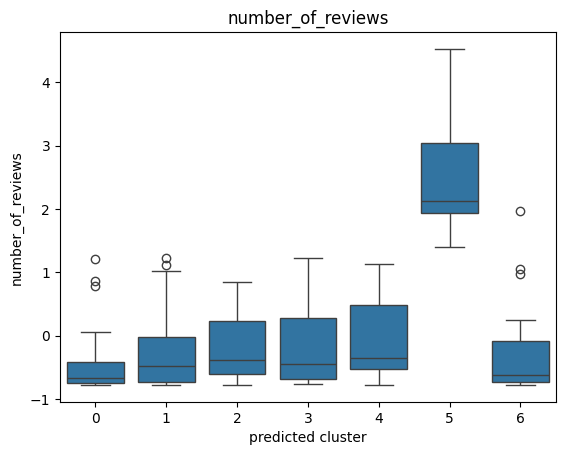

In [ ]:
for col in num_df_scaled.columns:
    sns.boxplot(x='predicted cluster',y=col, data=X)
    plt.title(col)
    plt.show()

Some attributes that characterized cluster 2 was that it had a higher ABV and Sweet value than the other clusters. The aroma and taste reviews followed a similar pattern, with cluster 3 having the highest average value and cluster 0 having the lowest average value for both attributes. Cluster 3 also had the highest Sour score. Cluster 4 was the most bitter, while cluster 6 was the saltiest. Clusters 2 and 3 both had high average Fruits scores. Overall, we were successful in finding a cluster of beer that scored higher than the others for each attribute that we considered. This could be helpful to someone who knows what they like but is still trying to find new beers to try or to someone selling beer so that they can make sure they have a good variety available.

## 9. Clustering Algorithm #2 (HAC)

---



### Parameter Selection

In [ ]:
X=X.drop(['predicted cluster'], axis=1)


single 0.41980462992417217


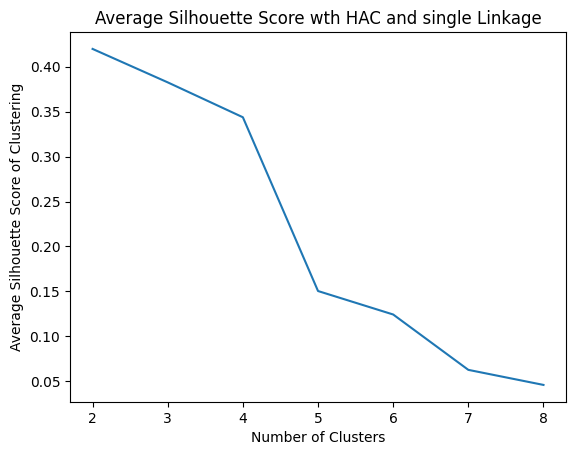

complete 0.26491616381107674


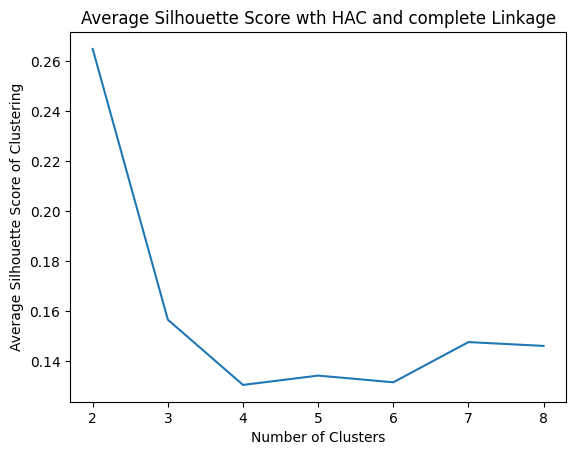

ward 0.22515050685533783


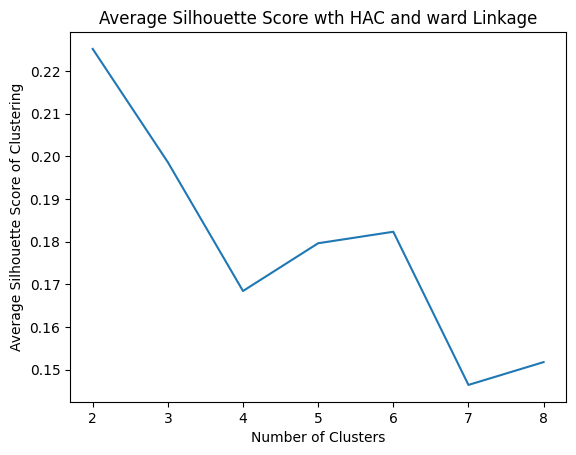

average 0.2952818591627935


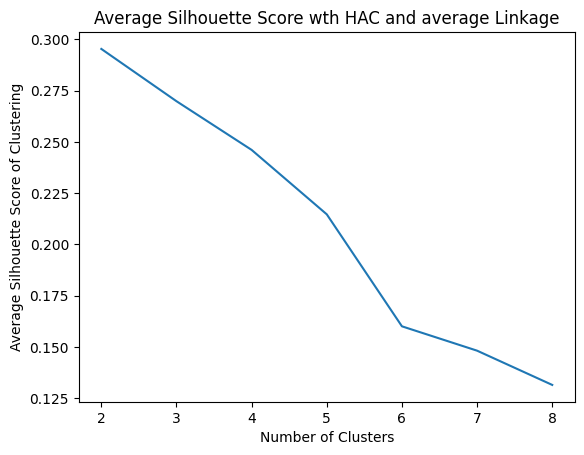

In [ ]:
for link in ['single', 'complete', 'ward', 'average']:
    avg_ss=[]
    for k in [2,3,4,5,6,7,8]:
        #First, designate the HAC linkage function, and the number of clusters you want to extract from the resulting dendrogram
        hac = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage=link)
        Y_pred = hac.fit_predict(num_df_scaled)
        avg_ss.append(silhouette_score(num_df_scaled, Y_pred))
    max_score = max(avg_ss)
    print(link, max_score)
    plt.plot([2,3,4,5,6,7,8], avg_ss)
    plt.title('Average Silhouette Score wth HAC and %s Linkage'%link)
    plt.xlabel('Number of Clusters')
    plt.ylabel('Average Silhouette Score of Clustering')
    plt.show()



Based on the average silhouette scores, the highest linkeage HAC is single linkeage with a silhouette score of 0.41980462992417217. We will still plot the dendrograms for all 4 clusters to see the structure and determine if any of the linkeage approaches result in singleton clusters or not. Our goal is to find inherent clustering structure so the lowest average silhouette score is not really guaranteed to show this. We need to look at the tsne plots and the clusters that each of these algorithms and linkeages make to determine the best one for finding the inherent clusters.


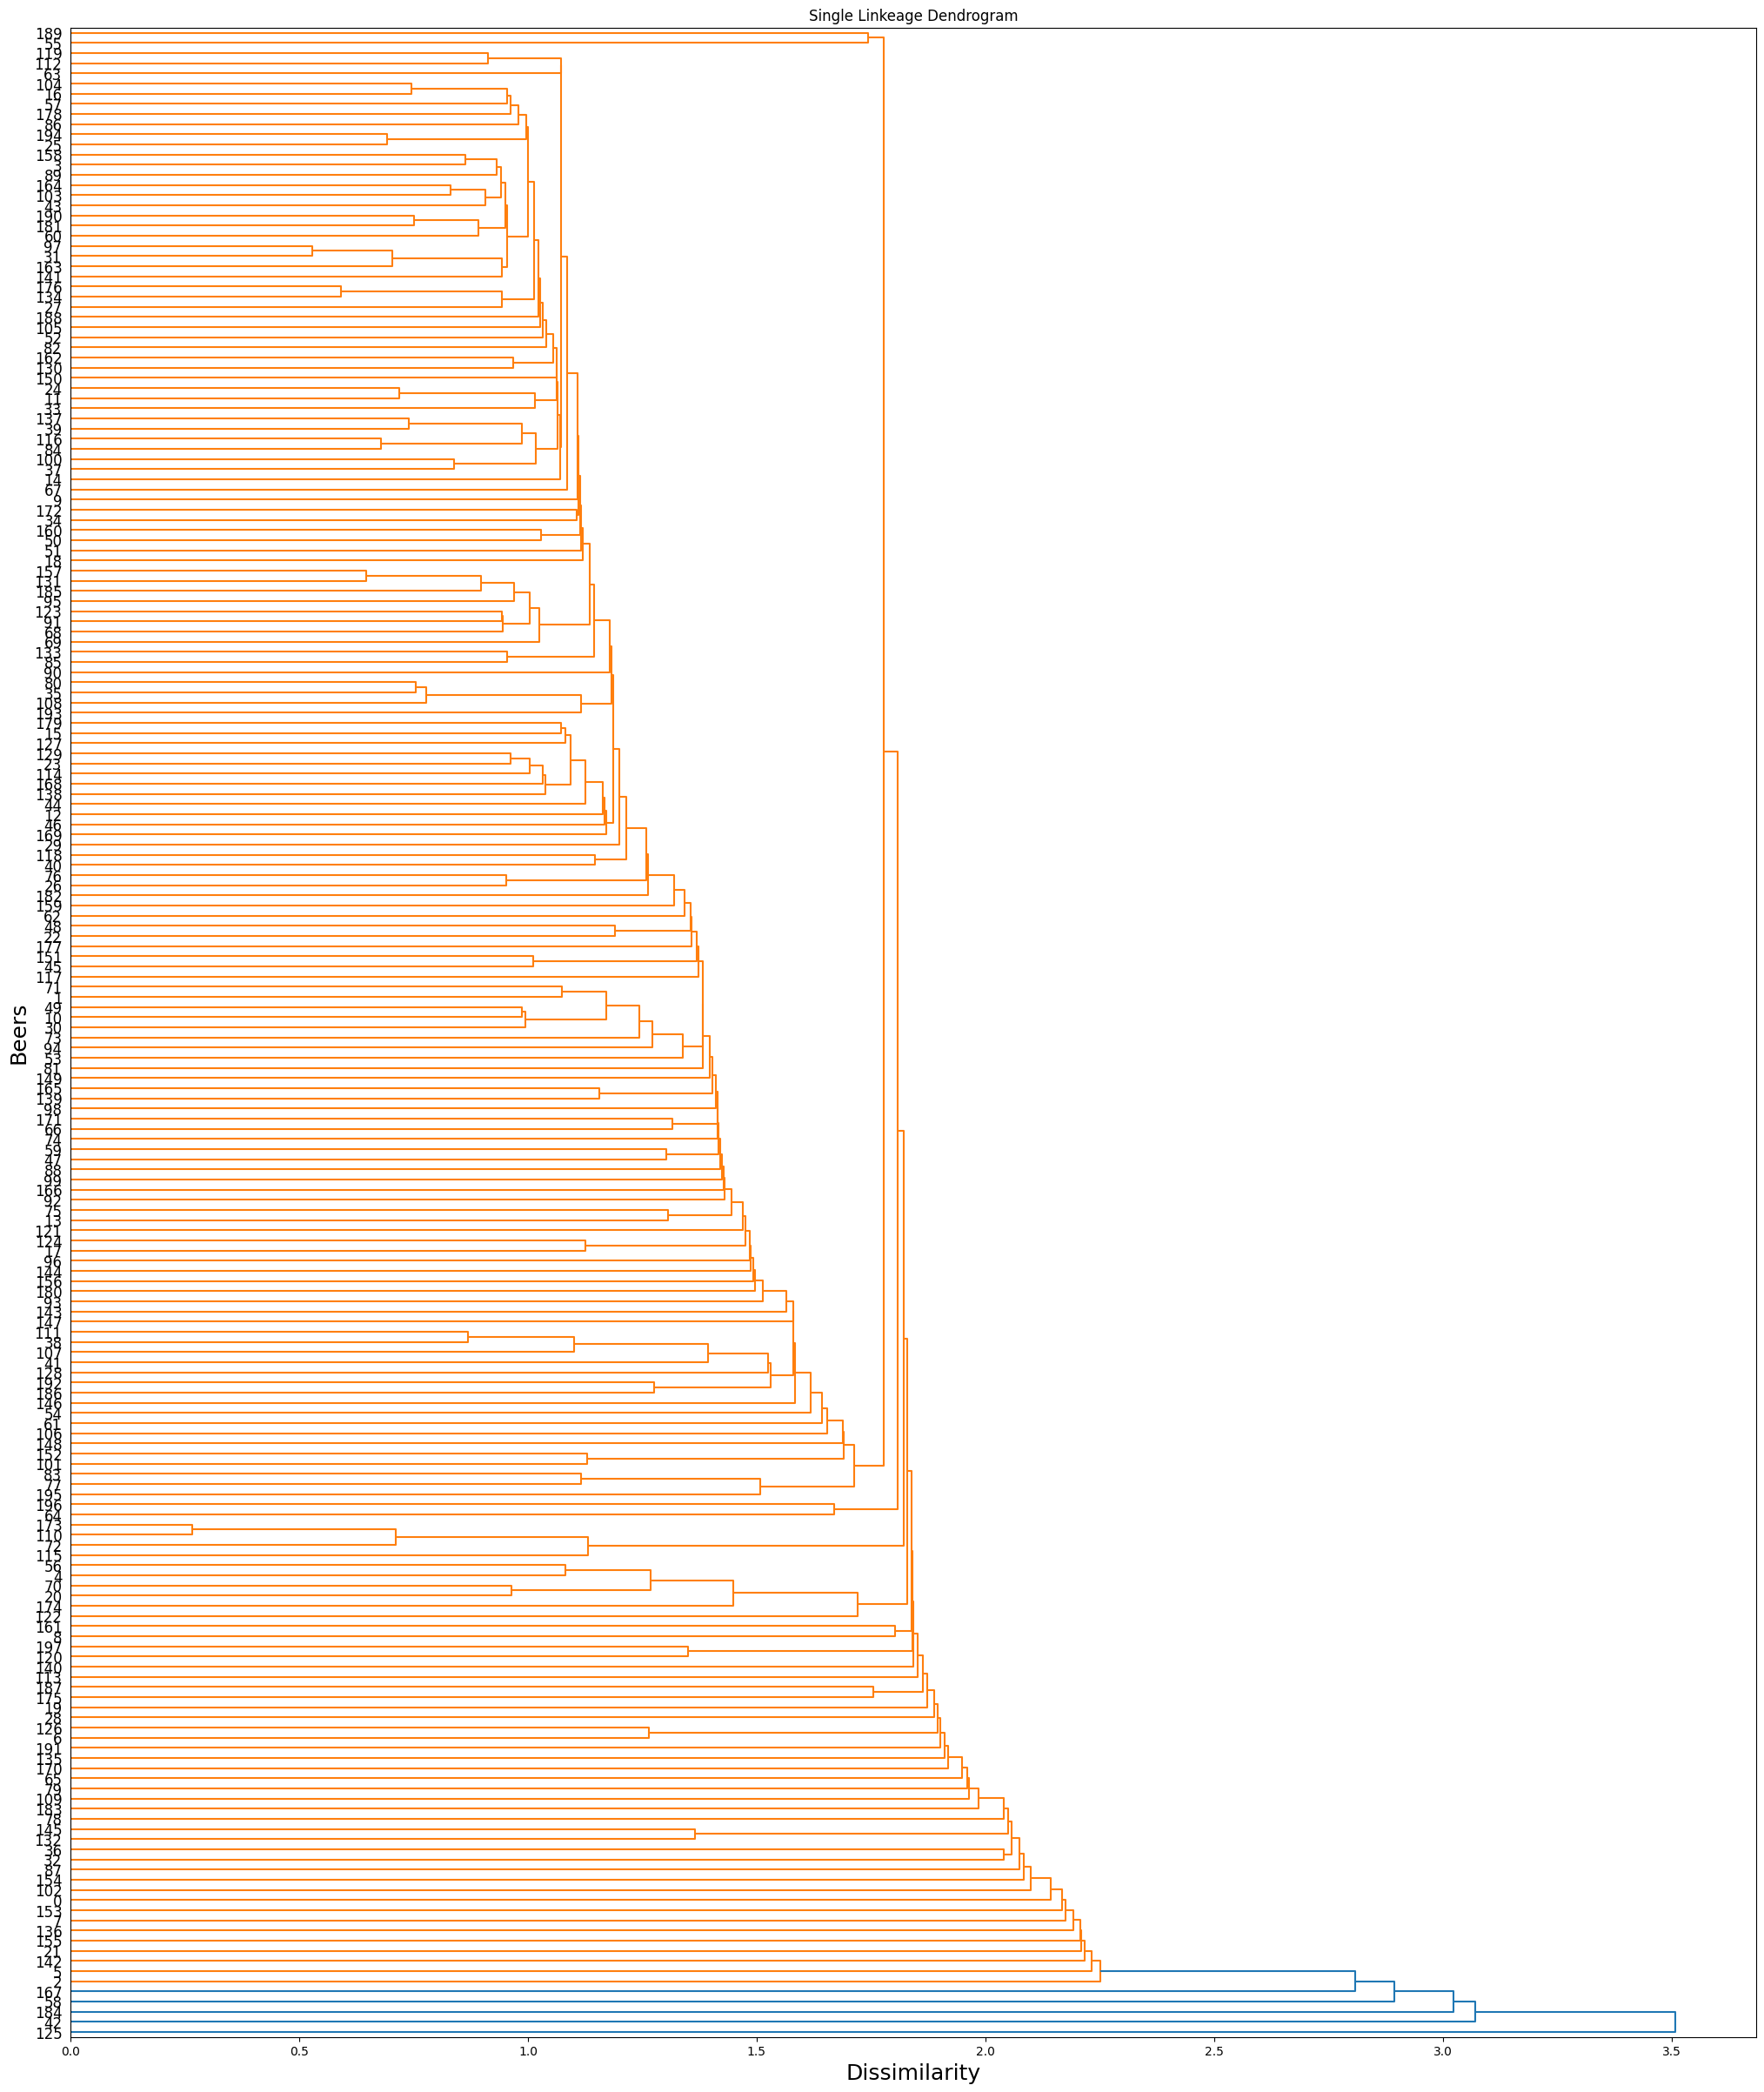

In [ ]:
dm = pdist(num_df_scaled, metric='euclidean')
Z = linkage(dm, method='single')

fig, ax = plt.subplots(figsize=(25, 30))
d = dendrogram(Z, orientation='right', ax=ax)
ax.set_xlabel('Dissimilarity', fontsize=18)
ax.set_ylabel('Beers', fontsize=18)
plt.yticks(fontsize=12)
plt.title('Single Linkeage Dendrogram')
plt.show()

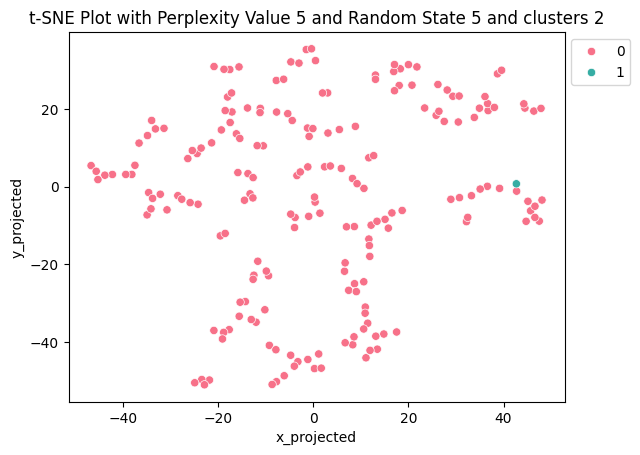

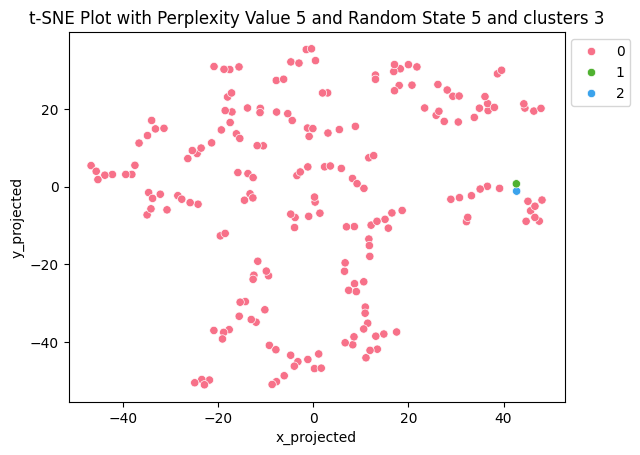

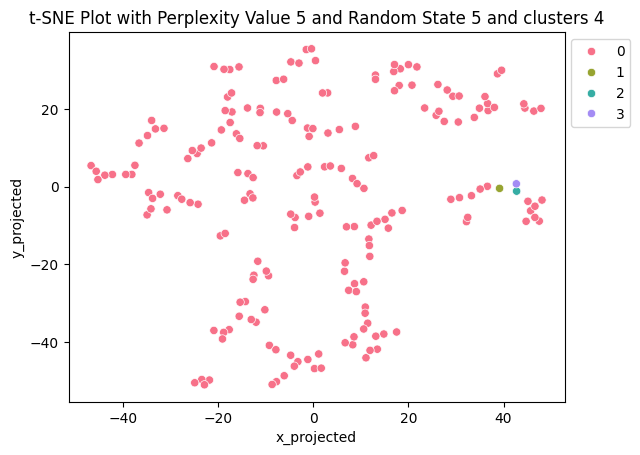

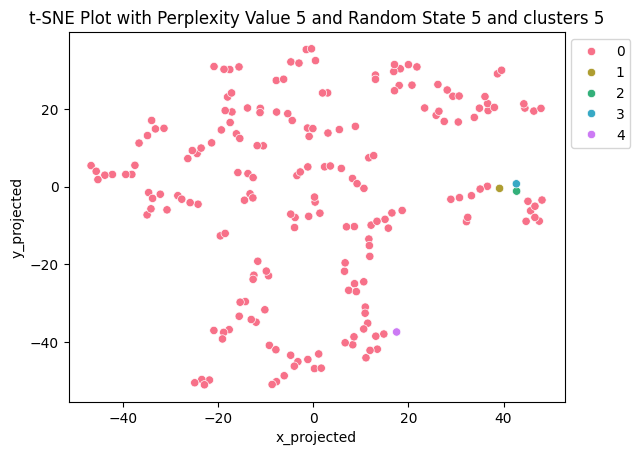

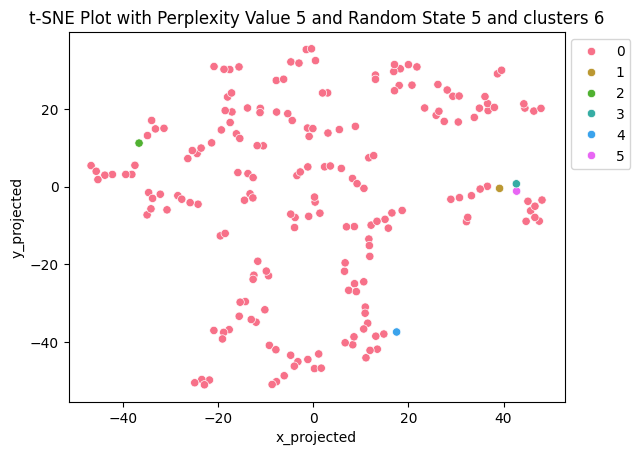

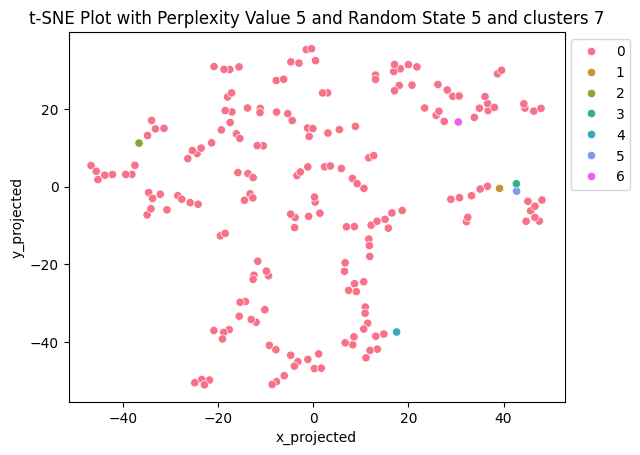

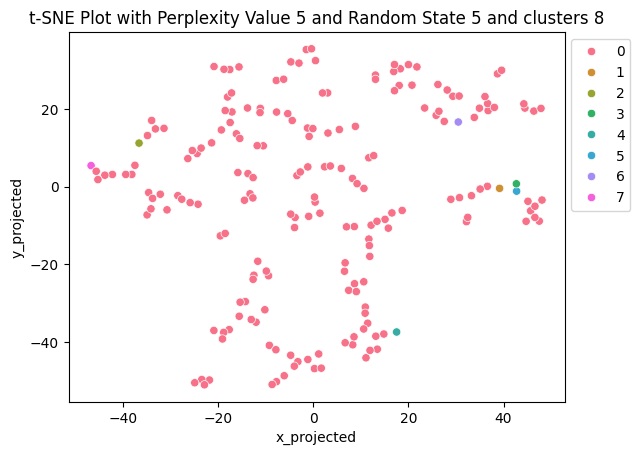

In [ ]:
for k in range(2,9):
    #Clustering from dendrogram with k clusters
    hac = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='single')
    df_combo['predicted_cluster'] = hac.fit_predict(num_df_scaled)

    #Map the resulting cluster labels onto our chosen t-SNE plot
    sns.scatterplot(x='x_projected',y='y_projected', hue='predicted_cluster', palette=sns.color_palette("husl", k), data=df_combo)
    plt.title('t-SNE Plot with Perplexity Value %s and Random State %s and clusters %s' %(5, 5, k))
    plt.legend(bbox_to_anchor=(1,1))
    plt.show()

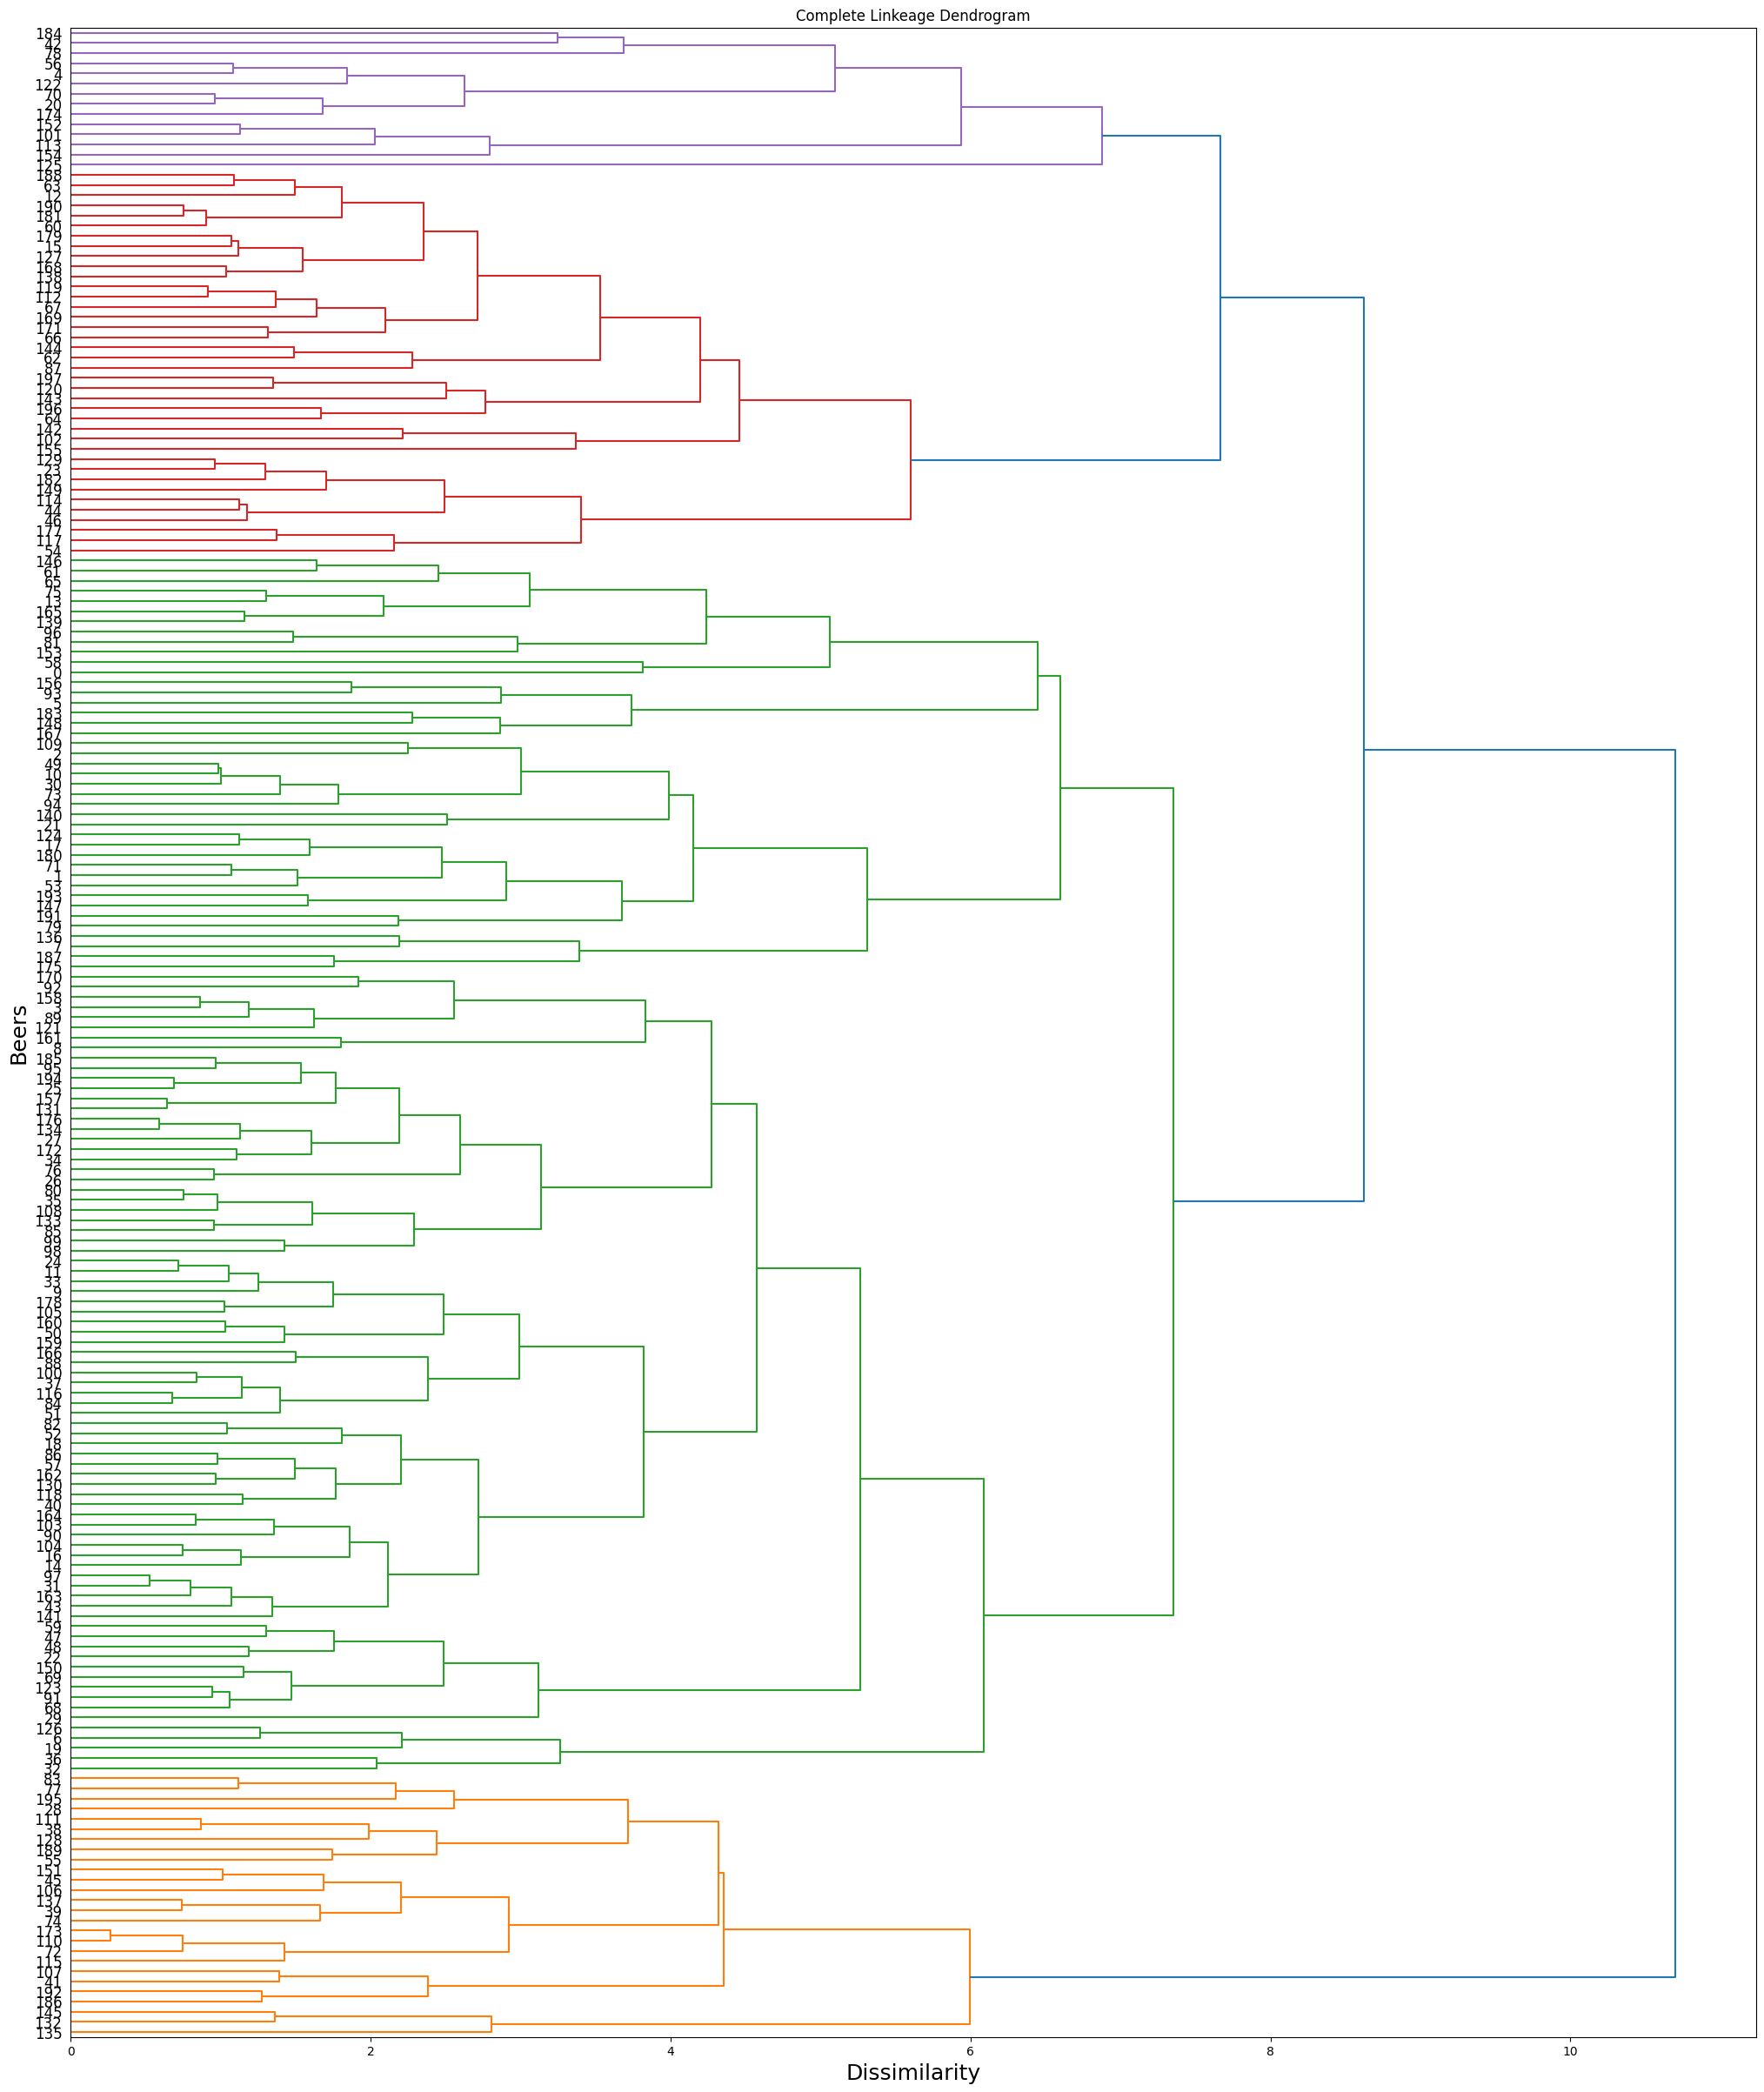

In [ ]:
dm = pdist(num_df_scaled, metric='euclidean')
Z = linkage(dm, method='complete')

fig, ax = plt.subplots(figsize=(25, 30))
d = dendrogram(Z, orientation='right', ax=ax)
ax.set_xlabel('Dissimilarity', fontsize=18)
ax.set_ylabel('Beers', fontsize=18)
plt.yticks(fontsize=12)
plt.title('Complete Linkeage Dendrogram')

plt.show()

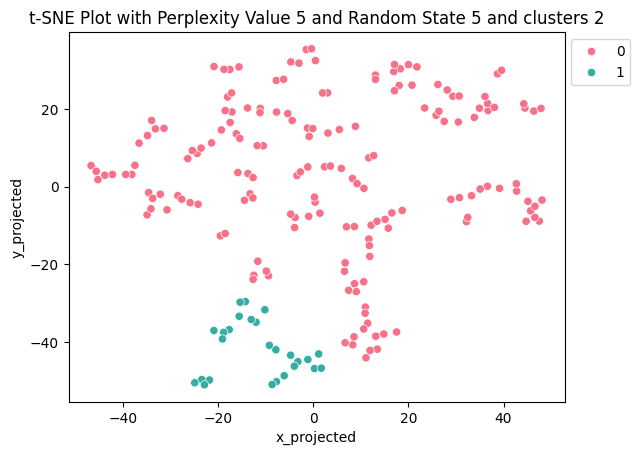

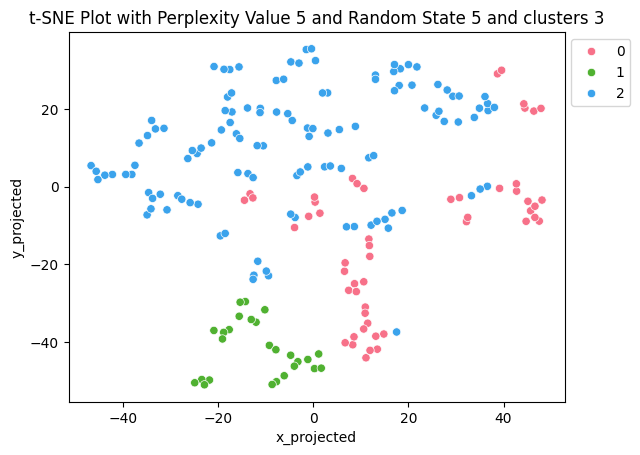

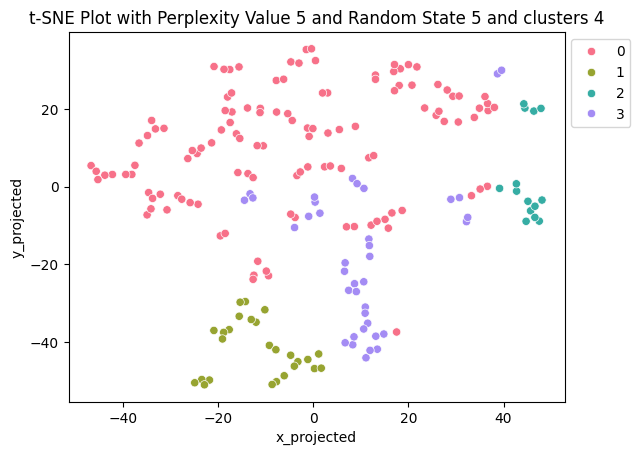

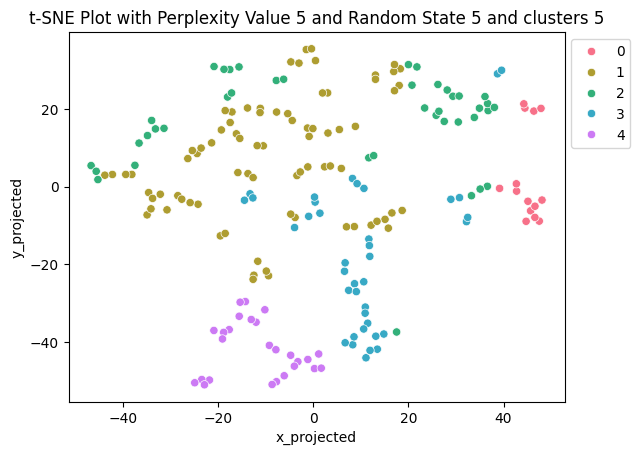

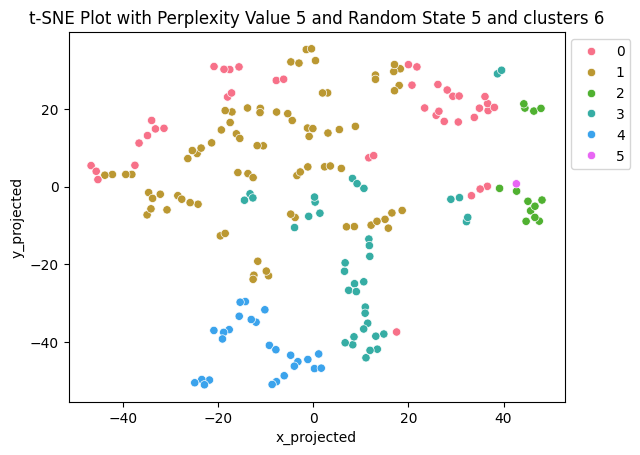

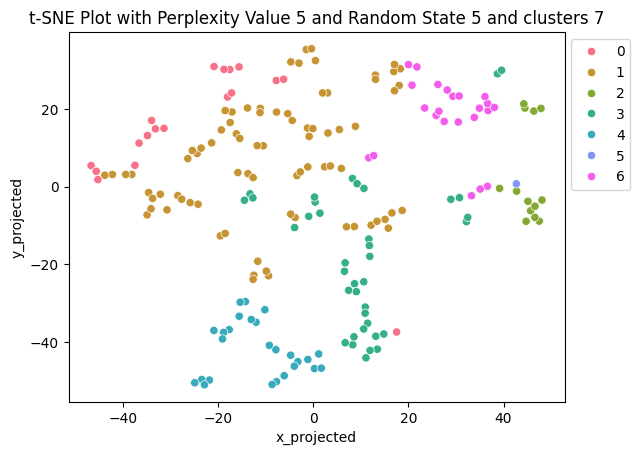

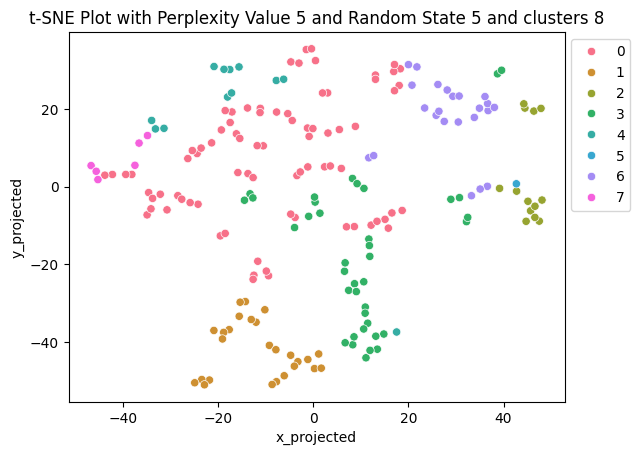

In [ ]:
for k in range(2,9):
    #Clustering from dendrogram with k clusters
    hac = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='complete')
    df_combo['predicted_cluster'] = hac.fit_predict(num_df_scaled)

    #Map the resulting cluster labels onto our chosen t-SNE plot
    sns.scatterplot(x='x_projected',y='y_projected', hue='predicted_cluster', palette=sns.color_palette("husl", k), data=df_combo)
    plt.title('t-SNE Plot with Perplexity Value %s and Random State %s and clusters %s' %(5, 5, k))
    plt.legend(bbox_to_anchor=(1,1))
    plt.show()

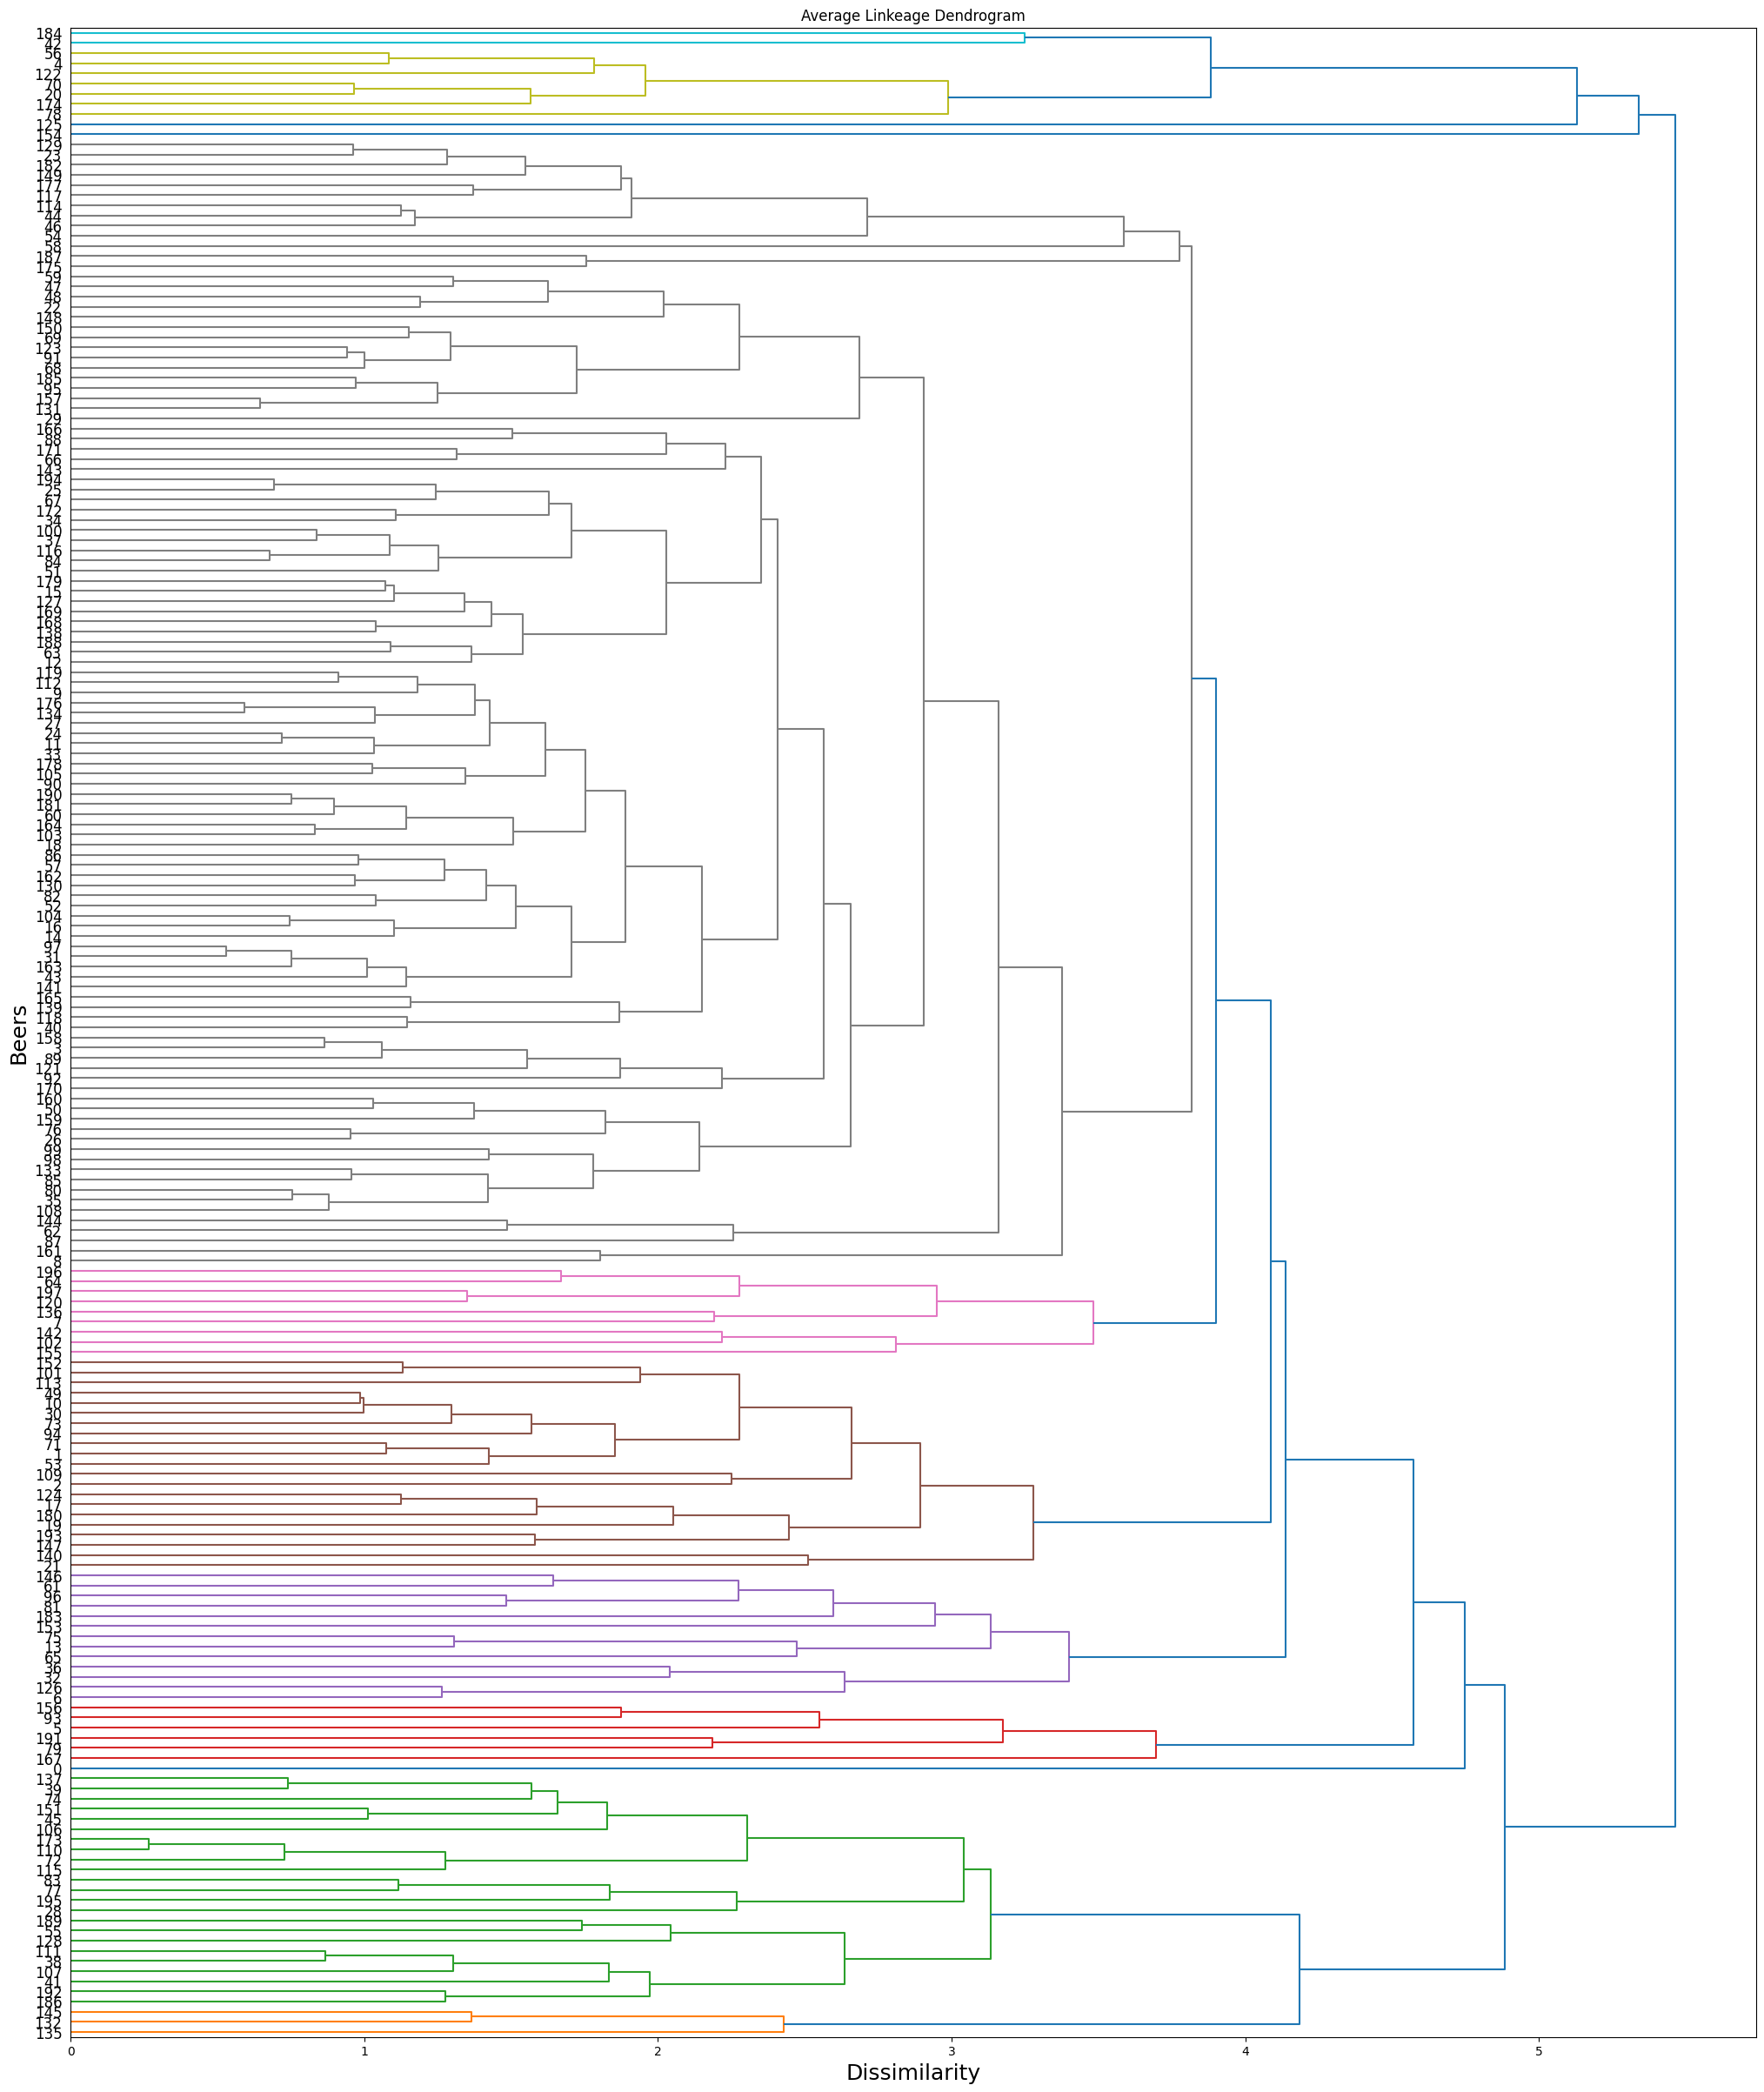

In [ ]:
dm = pdist(num_df_scaled, metric='euclidean')
Z = linkage(dm, method='average')

fig, ax = plt.subplots(figsize=(25, 30))
d = dendrogram(Z, orientation='right', ax=ax)
ax.set_xlabel('Dissimilarity', fontsize=18)
ax.set_ylabel('Beers', fontsize=18)
plt.yticks(fontsize=12)
plt.title('Average Linkeage Dendrogram')

plt.show()

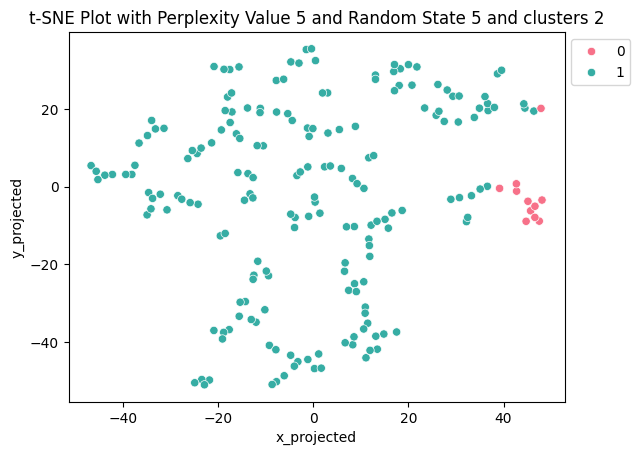

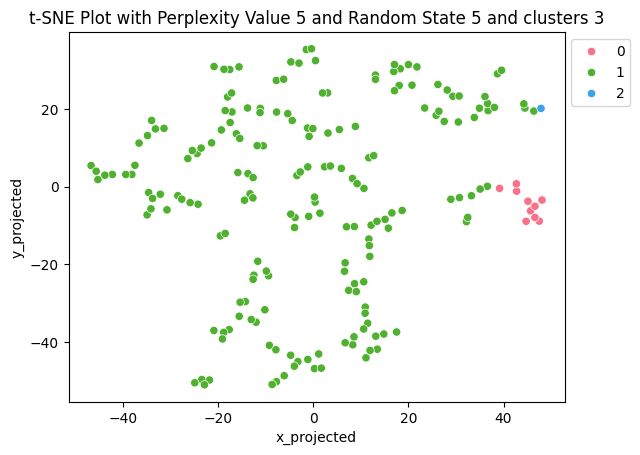

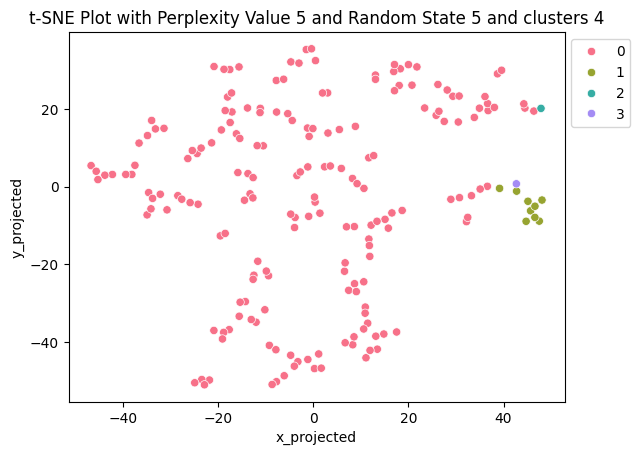

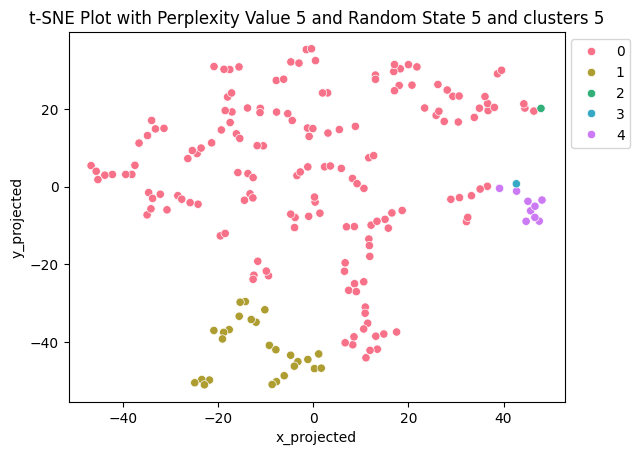

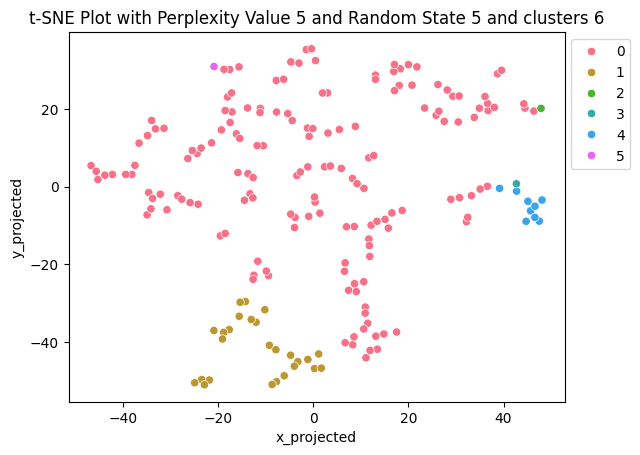

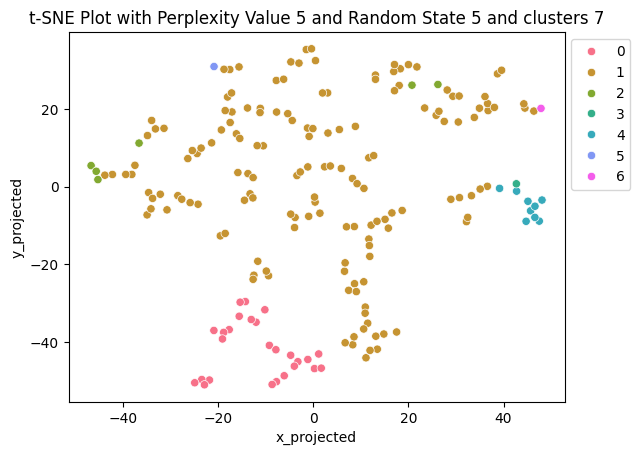

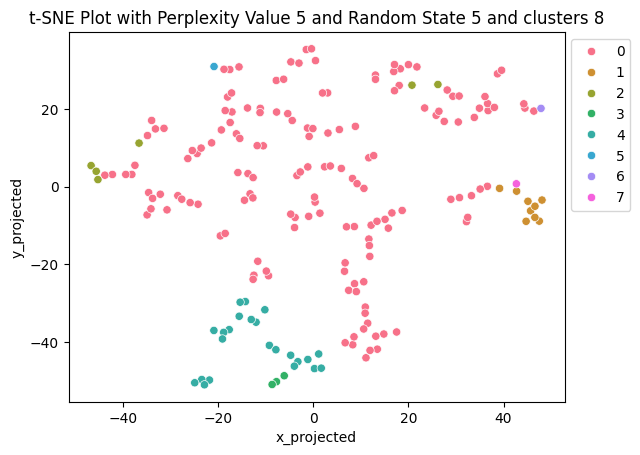

In [ ]:
for k in range(2,9):
    #Clustering from dendrogram with k clusters
    hac = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='average')
    df_combo['predicted_cluster'] = hac.fit_predict(num_df_scaled)

    #Map the resulting cluster labels onto our chosen t-SNE plot
    sns.scatterplot(x='x_projected',y='y_projected', hue='predicted_cluster', palette=sns.color_palette("husl", k), data=df_combo)
    plt.title('t-SNE Plot with Perplexity Value %s and Random State %s and clusters %s' %(5, 5, k))
    plt.legend(bbox_to_anchor=(1,1))
    plt.show()

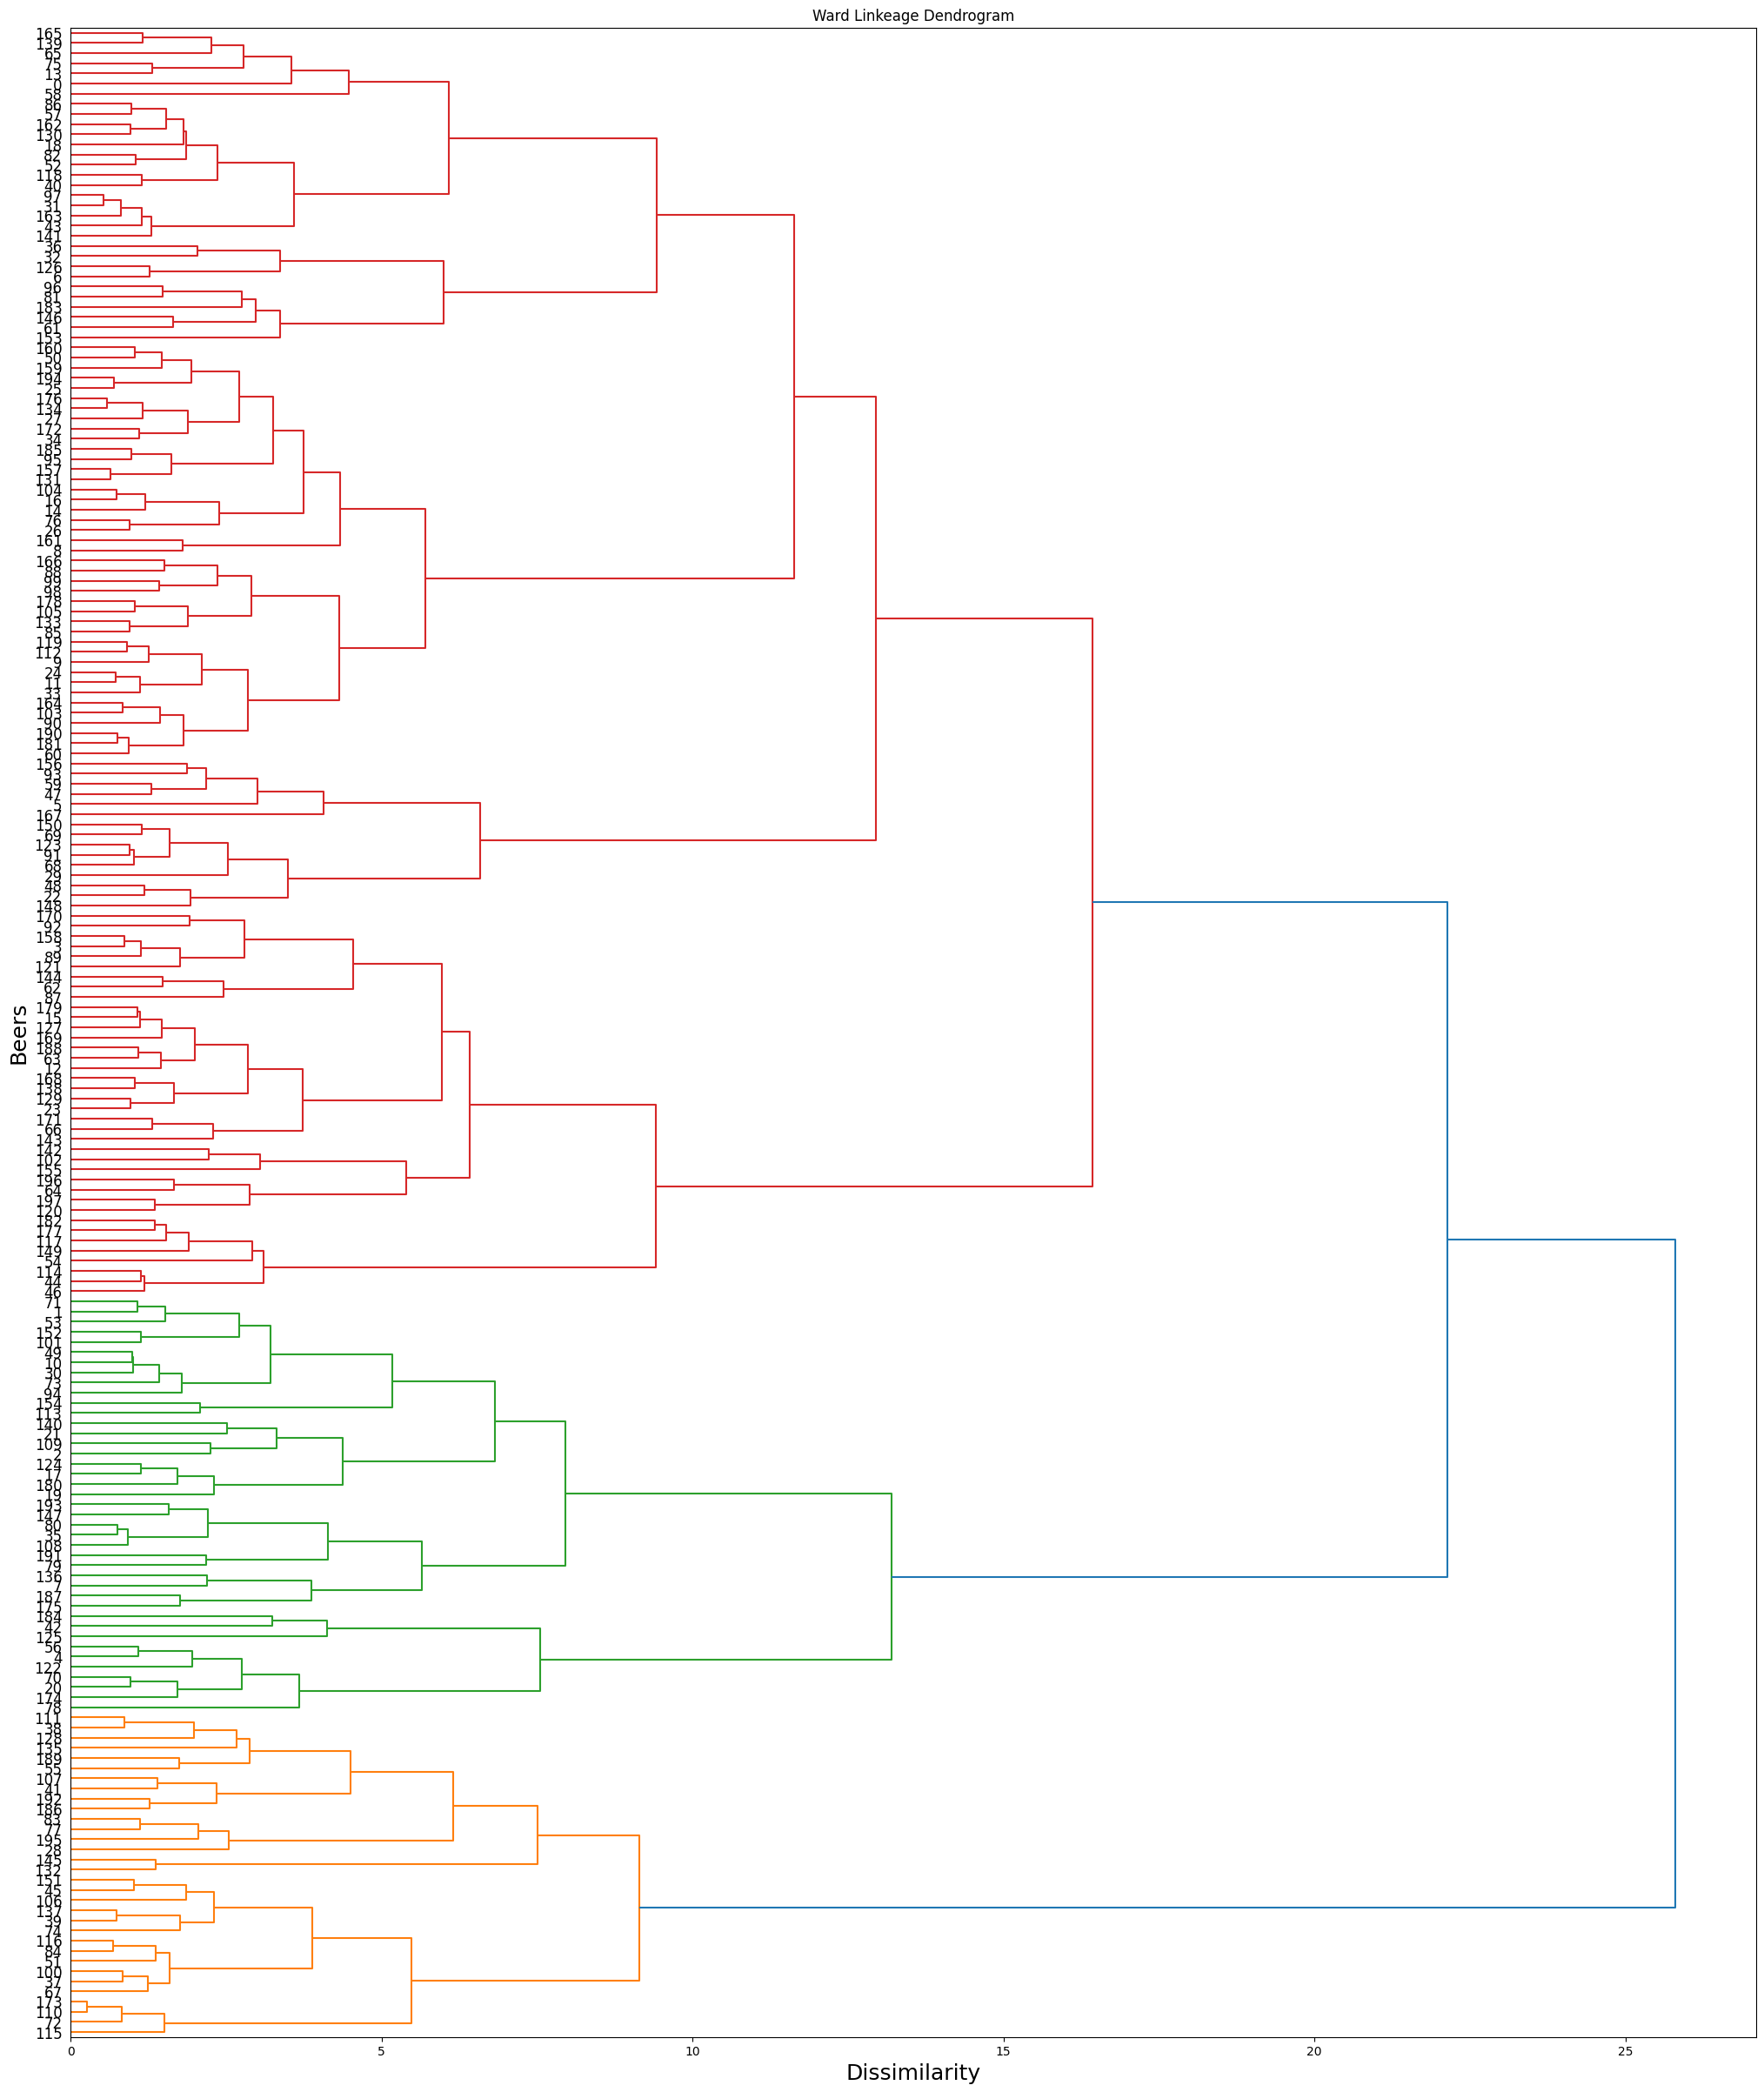

In [ ]:
dm = pdist(num_df_scaled, metric='euclidean')
Z = linkage(dm, method='ward')

fig, ax = plt.subplots(figsize=(25, 30))
d = dendrogram(Z, orientation='right', ax=ax)
ax.set_xlabel('Dissimilarity', fontsize=18)
ax.set_ylabel('Beers', fontsize=18)
plt.yticks(fontsize=12)
plt.title('Ward Linkeage Dendrogram')

plt.show()

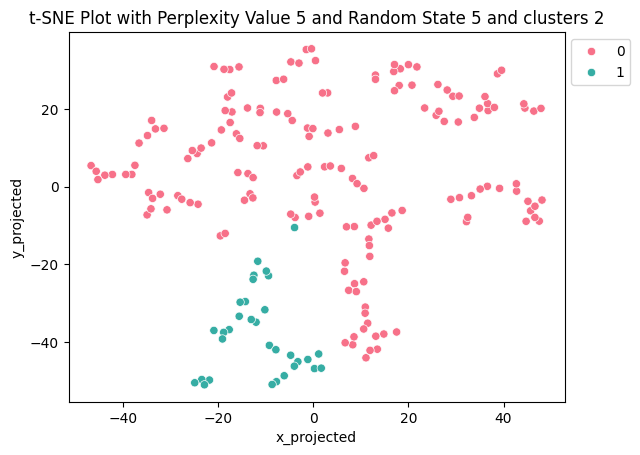

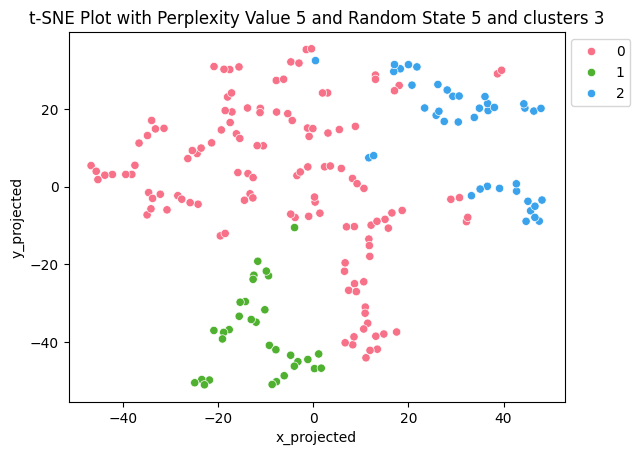

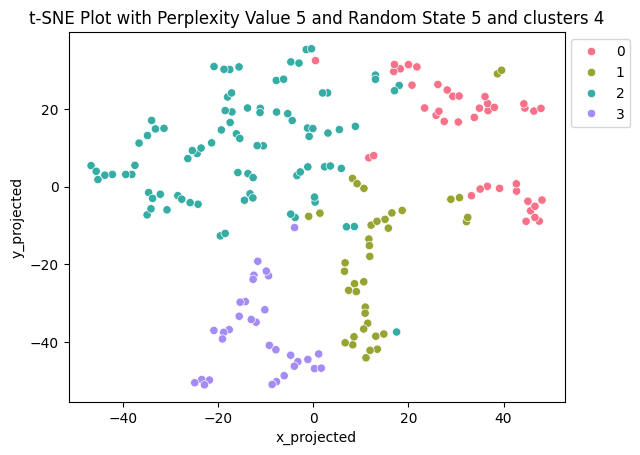

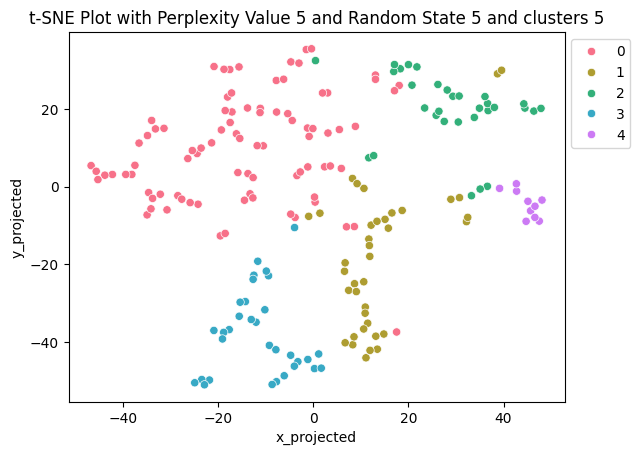

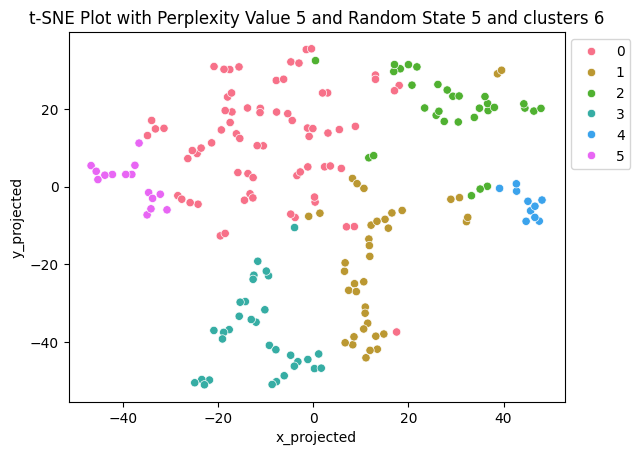

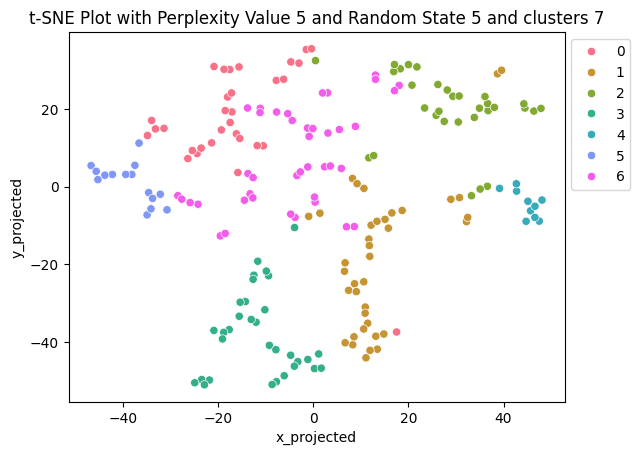

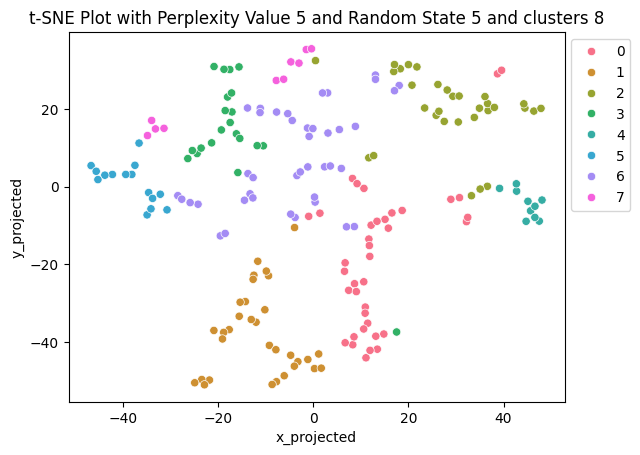

In [ ]:
for k in range(2,9):
    #Clustering from dendrogram with k clusters
    hac = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
    df_combo['predicted_cluster'] = hac.fit_predict(num_df_scaled)

    #Map the resulting cluster labels onto our chosen t-SNE plot
    sns.scatterplot(x='x_projected',y='y_projected', hue='predicted_cluster', palette=sns.color_palette("husl", k), data=df_combo)
    plt.title('t-SNE Plot with Perplexity Value %s and Random State %s and clusters %s' %(5, 5, k))
    plt.legend(bbox_to_anchor=(1,1))
    plt.show()

### Parameter Selection Justification
After consulting the dendrograms as well as the TSNE plots we will choose to use ward linkeage with k=3 clusters. In looking at purely the silhouette score, one might think to choose single linkeage with k=2 clusters, however, in looking at the dendrogram and tsne plot, we can see that this results in singleton cluster, with just one datapoint separated from the rest of the observations. This is not what we want as we are looking to find the inherent clustering within this data. The next highest average silhouette score comes from average linkeage but once again this results in poor clustering as suggested by the tsne and dendrograms, with a lot of singleton clusters that are rather uninformative. The choice then comes down to two linkeages, complete and ward. Both have a similar silhouette score, with complete being slightly larger but in looking at the tsne plots, the clustering chosen by ward matches with the structure of the data closer. The clustering with k=3 offers fair separation given the dataset and results in a more informative split when compared to the compelte linkeage which tends to split up the limited inherent clusters seen in the tsne plot. The dendrogram seems to support this decision as the ward linkeage provides the least number of singleton clusters out of all the links tested, with a distinct separation, although disbalanced in size, at k=3 clusters. Thus we choose k=3 clusters with ward linkeage.

The two methods we used to select k number of clusters is the average silhouette score as well as the tsne plot and the dendrogram to some extent. We chose k based on the tsne plot since it is easier to see cluster assignment following the shape of the data in a more natural way. The clustering with k=2 has the higher silhouette score but it does not perform well in this case due to the disbalanced nature of inherent clusters as well as the lack of distinct spherical shapes that the metric relies on for good results. Therefore we would prefer the k=3 cluster decision made by examining the tsne plot structure over the one suggested by the silhoutte score plot.

### Clustering the Data

In [ ]:
df_sort2=X.copy()
df_sort2.head()

,ABV,Bitter,Sweet,Sour,Salty,Fruits,review_aroma,review_taste,number_of_reviews
0,0.377743,3.978169,0.532650,0.256548,-0.622832,1.143207,0.279727,0.488746,-0.268539
1,0.945115,-0.848699,1.755616,0.340279,-0.622832,1.611021,0.582700,0.338058,-0.155632
2,2.170638,0.685422,2.914215,0.591471,-0.622832,1.477360,-0.235703,-0.440068,-0.519442
3,-0.552746,-0.399688,-0.432849,0.312369,-0.622832,0.207580,0.272403,0.245975,-0.640712
4,-0.643525,-1.372545,-0.336299,1.763699,-0.622832,1.276869,1.398541,1.504006,0.275086


In [ ]:
hac3 = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
df_sort2['predicted_cluster3'] = hac3.fit_predict(X)
df_sort2.head()

,ABV,Bitter,Sweet,Sour,Salty,Fruits,review_aroma,review_taste,number_of_reviews,predicted_cluster3
0,0.377743,3.978169,0.532650,0.256548,-0.622832,1.143207,0.279727,0.488746,-0.268539,0
1,0.945115,-0.848699,1.755616,0.340279,-0.622832,1.611021,0.582700,0.338058,-0.155632,2
2,2.170638,0.685422,2.914215,0.591471,-0.622832,1.477360,-0.235703,-0.440068,-0.519442,2
3,-0.552746,-0.399688,-0.432849,0.312369,-0.622832,0.207580,0.272403,0.245975,-0.640712,0
4,-0.643525,-1.372545,-0.336299,1.763699,-0.622832,1.276869,1.398541,1.504006,0.275086,2


### Clustering Results Presentation

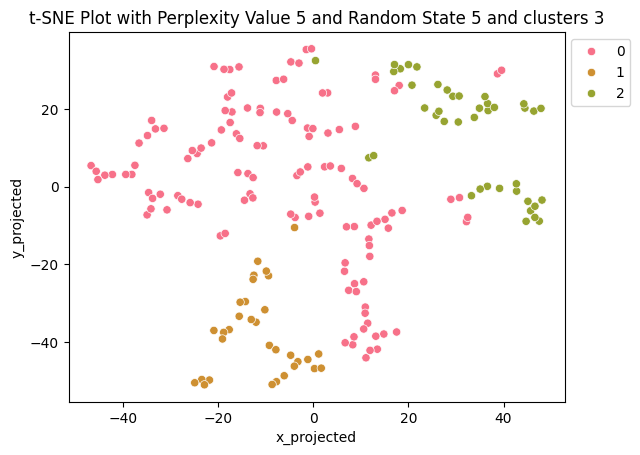

In [ ]:
#Clustering from dendrogram with k clusters
hac3T = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
df_combo['predicted_cluster'] = hac3T.fit_predict(num_df_scaled)

#Map the resulting cluster labels onto our chosen t-SNE plot
sns.scatterplot(x='x_projected',y='y_projected', hue='predicted_cluster', palette=sns.color_palette("husl", k), data=df_combo)
plt.title('t-SNE Plot with Perplexity Value %s and Random State %s and clusters %s' %(5, 5, 3))
plt.legend(bbox_to_anchor=(1,1))
plt.show()

When we cluster the dataset with ward linkeage and k=3 clusters we can see that we get 3 fairly well separated clusters that are disbalanced in size. We can also see that cluster 2 appears to be split somewhat and may be belonging to a different cluster. Cluster 1 seems to be the most well separated. Cluster 0 is the largest and least spherical out of the 3 clusters (although they are all not very spherical).

### Additional Clustering Exploration

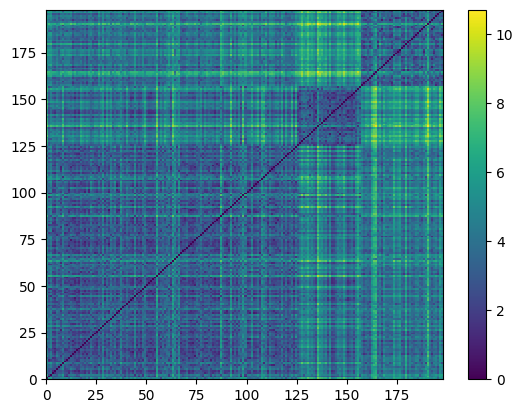

In [ ]:
#Cluster-sorted similarity matrix

df_sort2=df_sort2.sort_values(by=['predicted_cluster3'])
df_sort2=df_sort2.drop(['predicted_cluster3'], axis=1)

#Create a distance matrix
dist_mat = squareform(pdist(df_sort2))

#Then visualize the distance matrix with a heat map.
plt.pcolormesh(dist_mat)
plt.colorbar()
N = len(df_sort)
plt.xlim([0,N])
plt.ylim([0,N])
plt.show()

In looking at the cluster-sorted similarity matrix we can see that clusters 1 and 2 are the furthest apart from each other since they have the most yellow away from the main diagon, indicating their great separation.

For n_clusters = 3 The average silhouette_score is : 0.19860066627672465


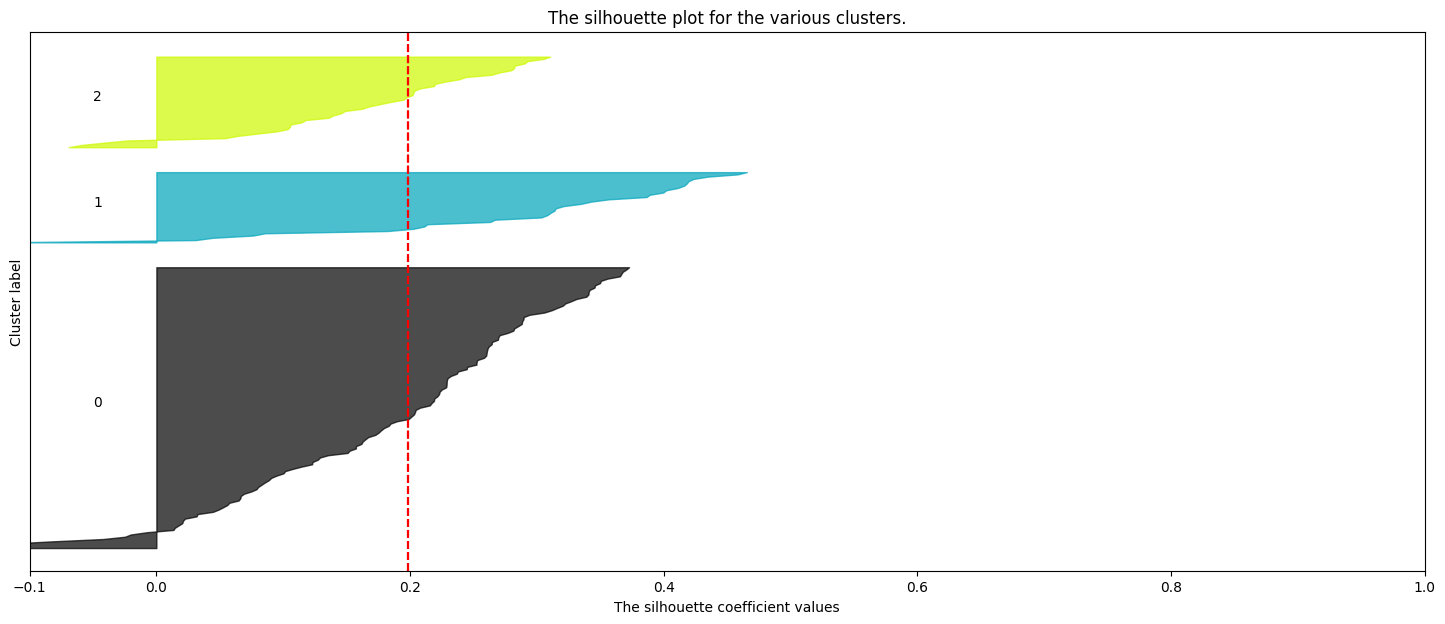

In [ ]:
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
#silhouette plot
def show_silhouette_plots(X,cluster_labels):

    # This package allows us to use "color maps" in our visualizations
    import matplotlib.cm as cm

    #How many clusters in your clustering?
    n_clusters=len(np.unique(cluster_labels))

    # Create a subplot with 1 row and 2 columns
    fig, ax1 = plt.subplots(1, 1)
    fig.set_size_inches(18, 7)

    # The 1st subplot is the silhouette plot
    # The silhouette coefficient fcan range from -1, 1 but in this example all
    # lie within [-0.1, 1]
    ax1.set_xlim([-0.1, 1])
    # The (n_clusters+1)*10 is for inserting blank space between silhouette
    # plots of individual clusters, to demarcate them clearly.
    ax1.set_ylim([0, len(X) + (n_clusters + 1) * 10])


    # The silhouette_score gives the average value for all the samples.
    # This gives a perspective into the density and separation of the formed
    # clusters
    silhouette_avg = silhouette_score(X, cluster_labels)
    print("For n_clusters =", n_clusters,
          "The average silhouette_score is :", silhouette_avg)

    # Compute the silhouette scores for each sample
    sample_silhouette_values = silhouette_samples(X, cluster_labels)

    y_lower = 10
    for i in range(n_clusters):
        # Aggregate the silhouette scores for samples belonging to
        # cluster i, and sort them
        ith_cluster_silhouette_values = \
            sample_silhouette_values[cluster_labels == i]


        ith_cluster_silhouette_values.sort()

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax1.fill_betweenx(np.arange(y_lower, y_upper),
                          0, ith_cluster_silhouette_values,
                          facecolor=color, edgecolor=color, alpha=0.7)

        # Label the silhouette plots with their cluster numbers at the middle
        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

        # Compute the new y_lower for next plot
        y_lower = y_upper + 10  # 10 for the 0 samples

        ax1.set_title("The silhouette plot for the various clusters.")
        ax1.set_xlabel("The silhouette coefficient values")
        ax1.set_ylabel("Cluster label")

        # The vertical line for average silhouette score of all the values
        ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

        ax1.set_yticks([])  # Clear the yaxis labels / ticks
        ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])


    plt.show()

    return
cluster_labels=hac3.labels_
show_silhouette_plots(X, cluster_labels)

The silhouette plot suggests that the clusters have mostly weak cohesion and separation. We have fairly low coefficient values for each of the clusters, varying between about 0.5 and 0.3. Each cluster also has some negative values, suggesting that some points have been wrongfully assigned to the wrong cluster. The most cohesive cluster appears to be cluster 1 as it has the highest silhouette score and the lowest number of negative elements. Cluster 0 has the most negative elements and it is also the largest cluster so that somewhat makes sense as some points were likely misclassified due to poor separation. Cluster 2 has the lowest silhouette score overall and a fair number of negative values. The most cohesive and well separated cluster is cluster 1 while clusters 0 and 2 are significantly less cohesive and well separated. This makes sense as our data points are not very well separted, tsne clusters are not spherical and the clusters tend to vary in size.

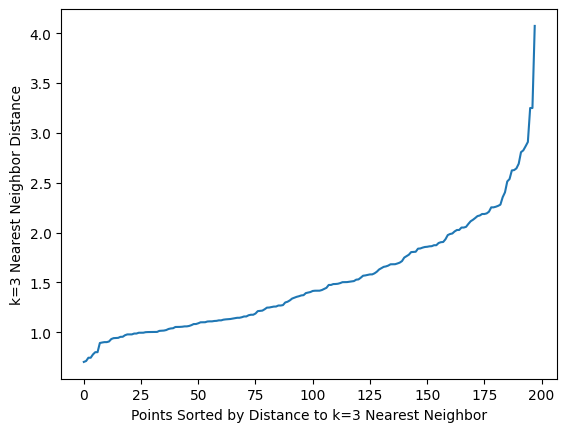

In [ ]:
#Find the distance of the kth nearest neighbor
for k in range(3,4):
    nbrs = NearestNeighbors(n_neighbors=k, algorithm='ball_tree').fit(num_df_scaled)
    distances, indices = nbrs.kneighbors(num_df_scaled)

    plt.plot(np.sort(distances.T[k-1]))
    #plt.axvline(x=3841, color='black')
    plt.xlabel('Points Sorted by Distance to k=%s Nearest Neighbor'%k)
    plt.ylabel('k=%s Nearest Neighbor Distance'%k)
    plt.show()

We can see that cluster 2 is perhaps slightly more sparse than clusters 0 and 1 when looking at the cluster similarity matrix as denoted by the darkness of shading within it. This is corroborated by the KNN distance plot, although generally speaking, all three clusters are rather sparse. This makes sense when compared to the tsne plot as we can see a clear split in cluster 2 which is likely the source of the sparsity detected by KNN distance plot and cluster similarity matrix.

### Shortcomings

Some of the shortcomings of the silhouette plots and cluster similarity matrix are that they typically work best for similar sized clusters that are approximately spherical. This is not the case for our dataset as the clusters we see are neither spherical not similarly sized. As a result the silhouette plots in particular are rather poor.

### Finding the Inherent clusters

In looking at the dendrogram we do not see any significant evidence of a cluster being split but when looking at the tsne plot, we can see that cluster 2 appears to be somewhat split into two parts. This is further corroborated by the cluster similarity matrix and KNN distance plots. We also have evidence that cluster 0 may contain at least 2 inherent clusters. In looking at the tsne plot it appears to be possible to split the bottom right portion of it and make it its own cluster or join it with clusters 1 or 2. The same can be observed in the dendrogram as cluster 0 (the big red cluster) appears to have at least 5 similar merge points which may be indicative of the presence of up to 5 subclusters within it. In looking at the tsne plot though, it would be hard to say that this separation would be meaningful.

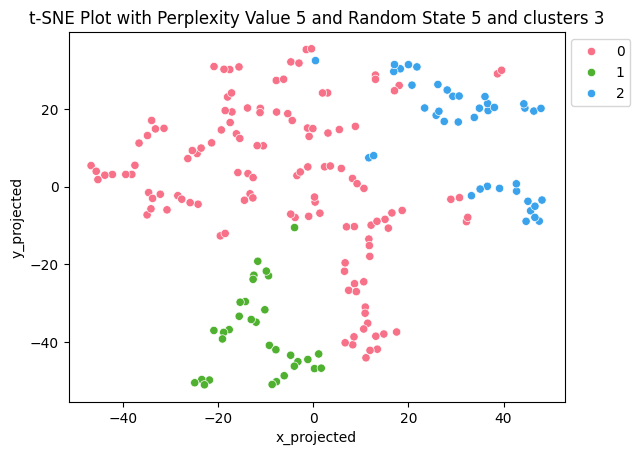

In [ ]:
#Clustering from dendrogram with k clusters
hac3T = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
df_combo['predicted_cluster'] = hac3T.fit_predict(num_df_scaled)

#Map the resulting cluster labels onto our chosen t-SNE plot
sns.scatterplot(x='x_projected',y='y_projected', hue='predicted_cluster', palette=sns.color_palette("husl", k), data=df_combo)
plt.title('t-SNE Plot with Perplexity Value %s and Random State %s and clusters %s' %(5, 5, 3))
plt.legend(bbox_to_anchor=(1,1))
plt.show()

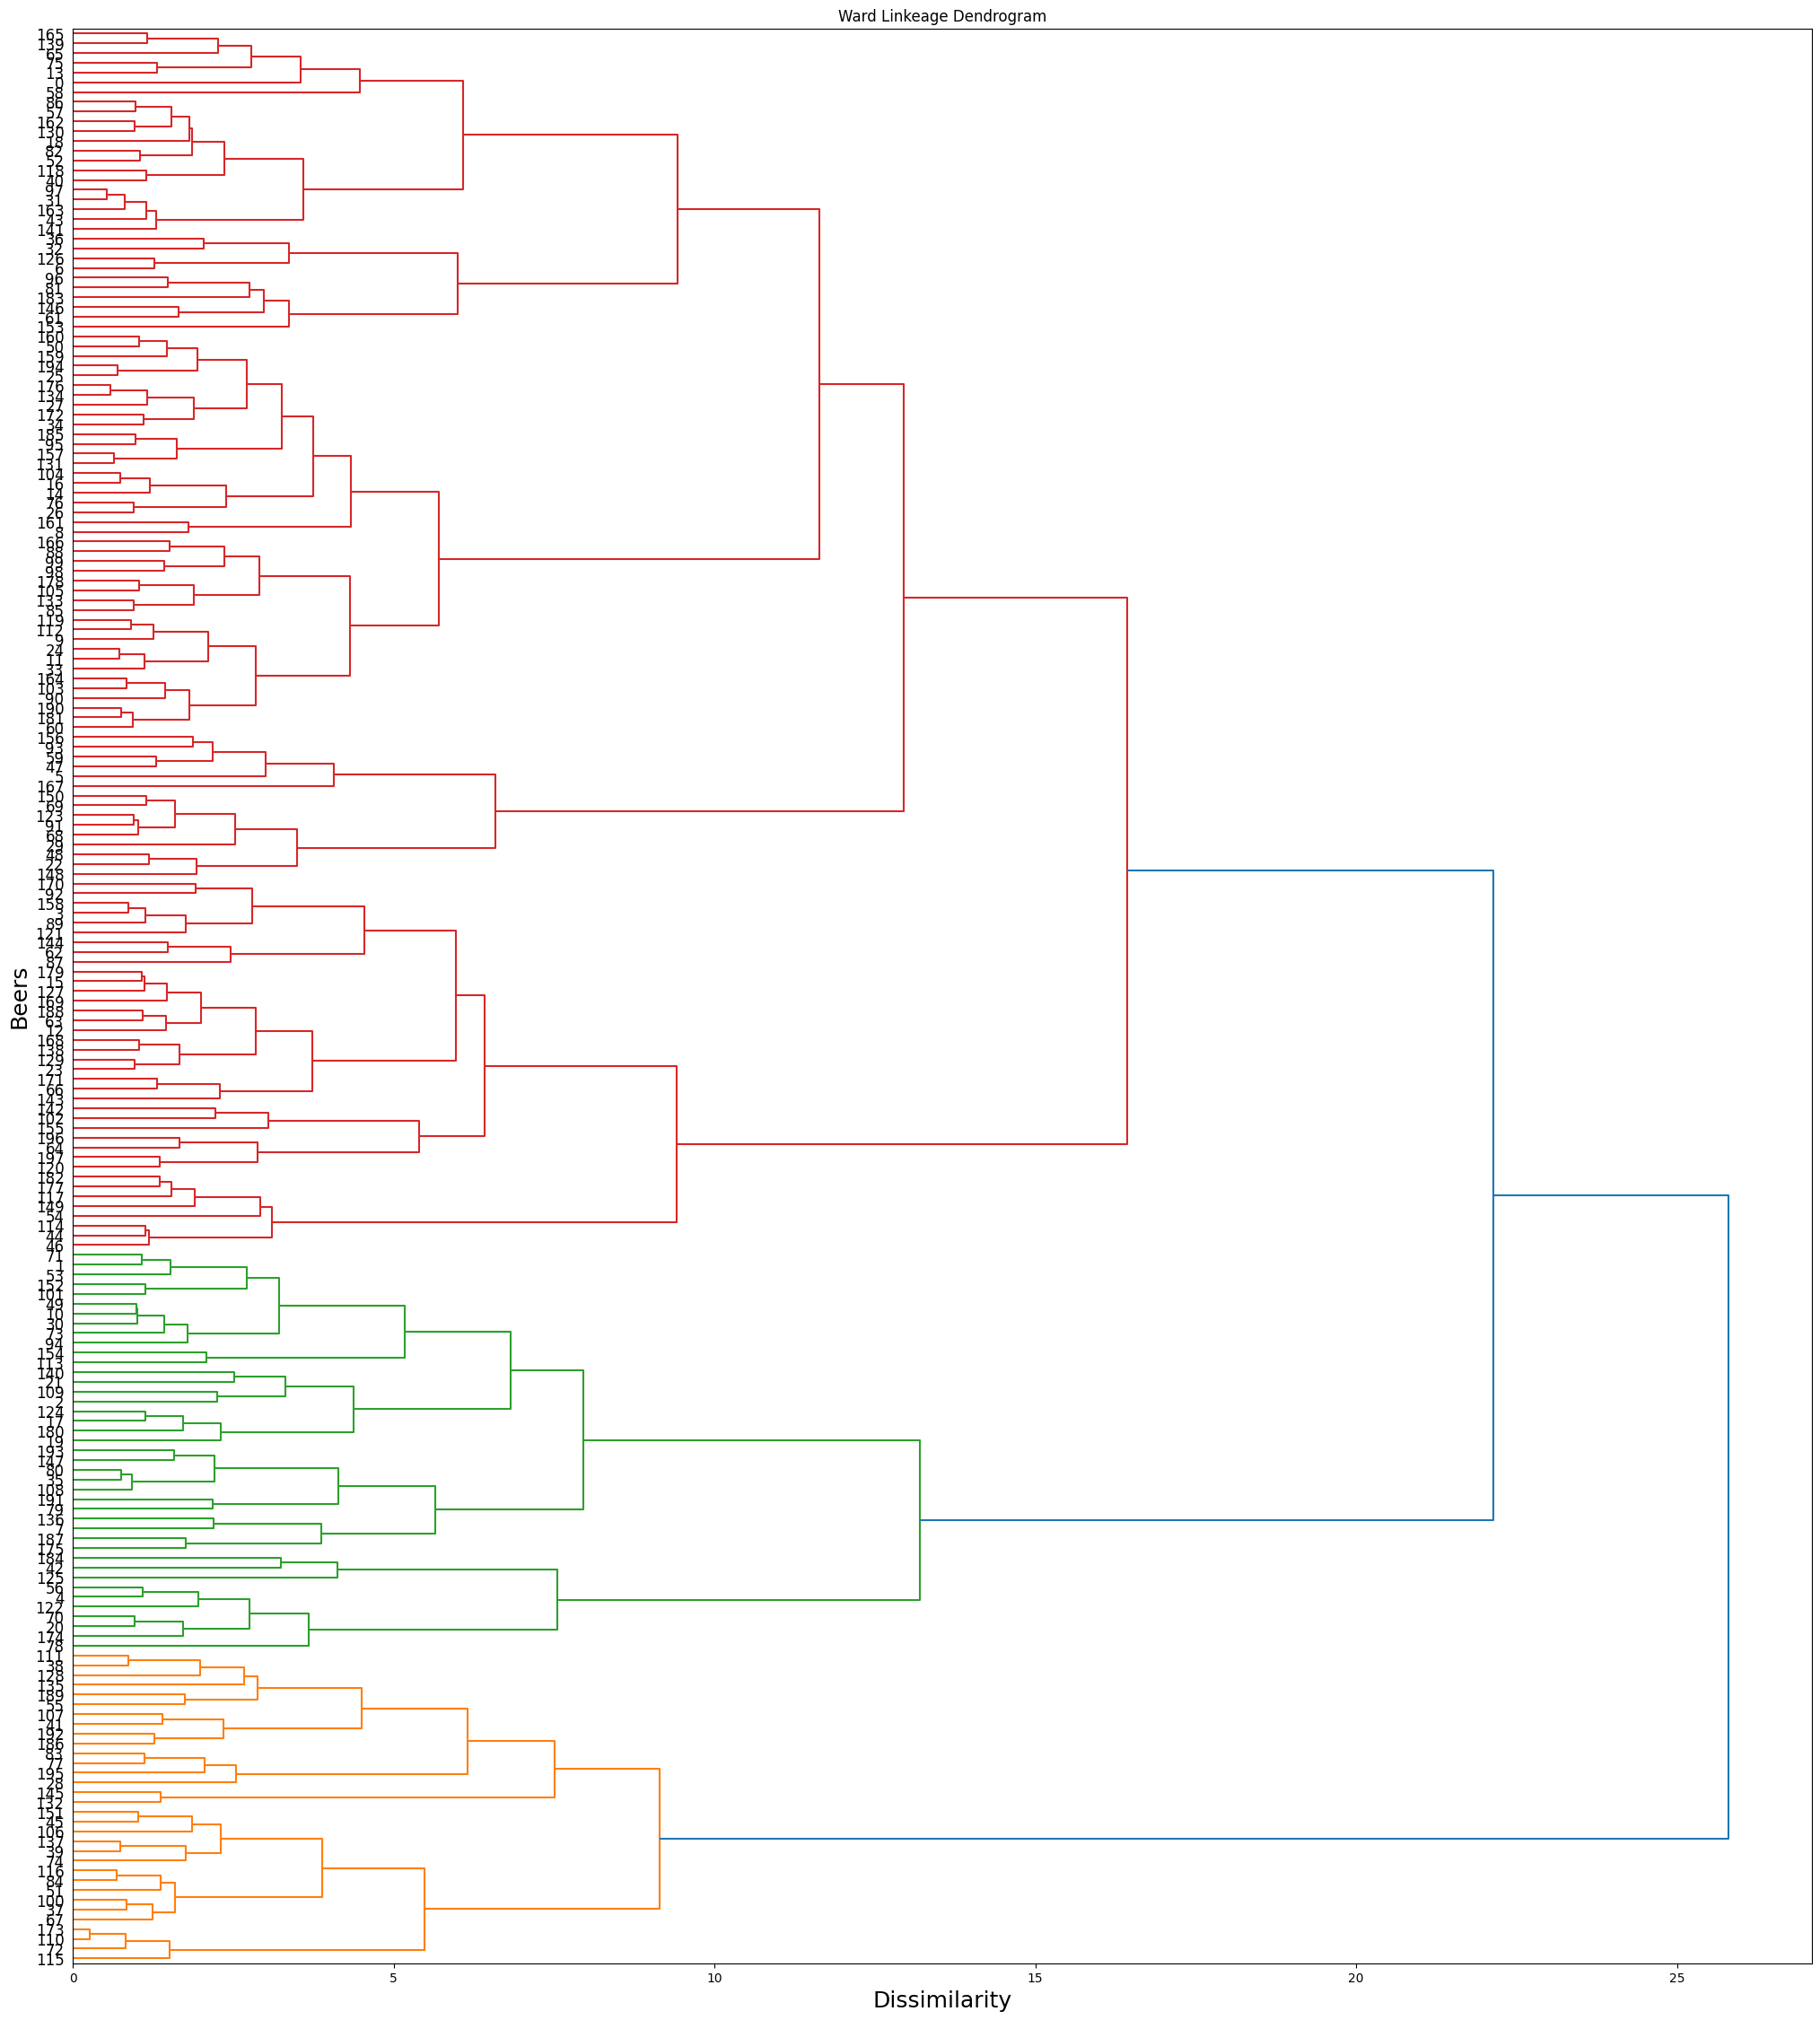

In [ ]:
dm = pdist(num_df_scaled, metric='euclidean')
Z = linkage(dm, method='ward')

fig, ax = plt.subplots(figsize=(25, 28))
d = dendrogram(Z, orientation='right', ax=ax)
ax.set_xlabel('Dissimilarity', fontsize=18)
ax.set_ylabel('Beers', fontsize=18)
plt.yticks(fontsize=12)
plt.title('Ward Linkeage Dendrogram')

plt.show()

### Describing Each of the Clusters

In [ ]:
hac3 = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
df['predicted_cluster3'] = hac3.fit_predict(X)


In [ ]:
cols=df.columns
cols=cols.drop(['index','Name','Style','Brewery','Beer Name (Full)','Description','Rating','predicted_cluster3'])
cols


Index(['ABV', 'Min IBU', 'Max IBU', 'Astringency', 'Body', 'Alcohol', 'Bitter',
       'Sweet', 'Sour', 'Salty', 'Fruits', 'Hoppy', 'Spices', 'Malty',
       'review_aroma', 'review_appearance', 'review_palate', 'review_taste',
       'review_overall', 'number_of_reviews'],
      dtype='object')

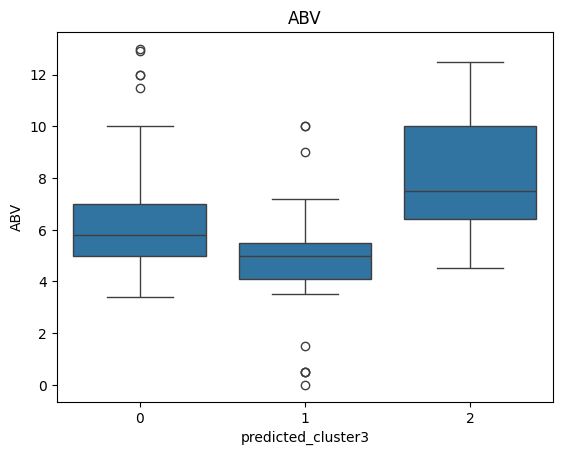

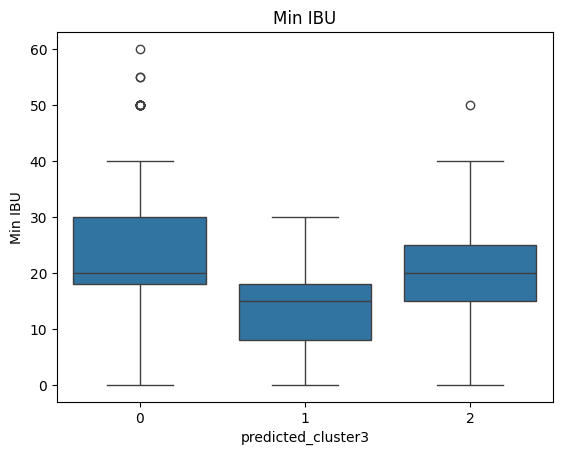

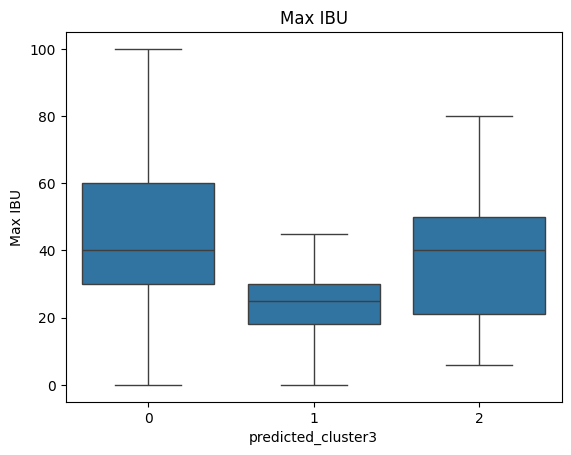

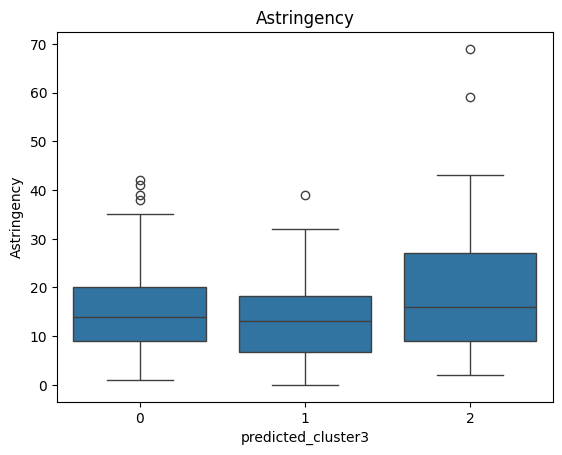

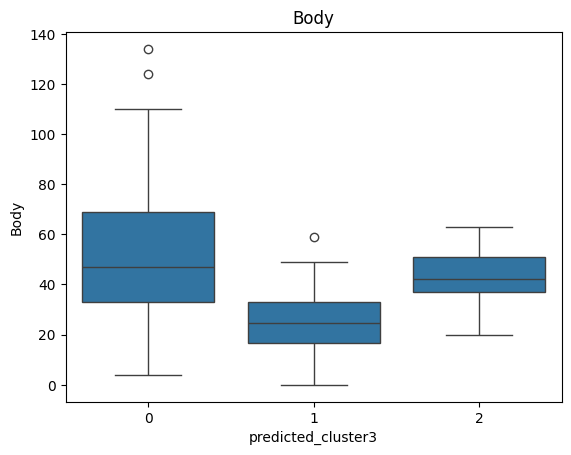

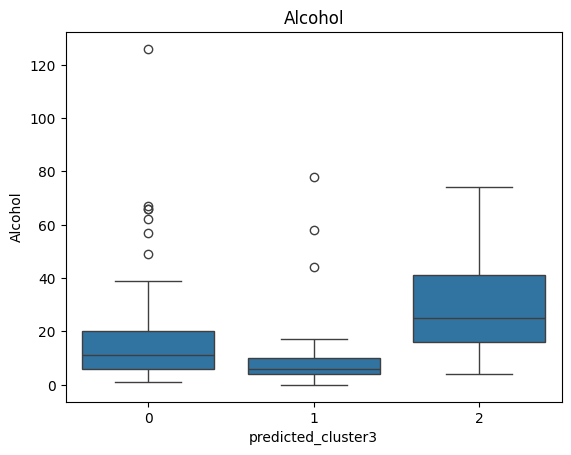

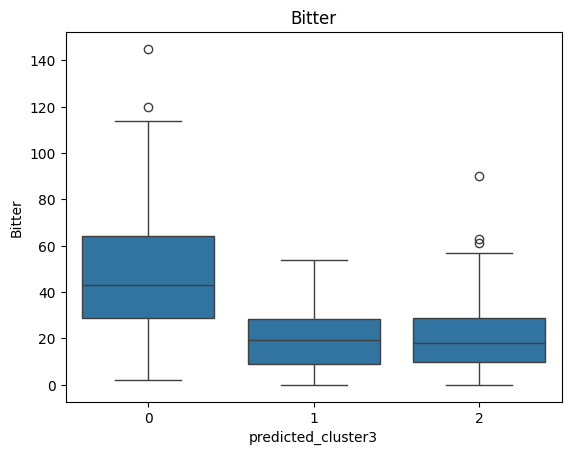

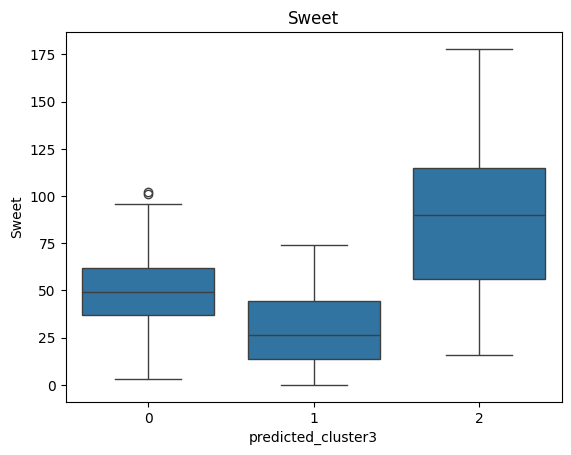

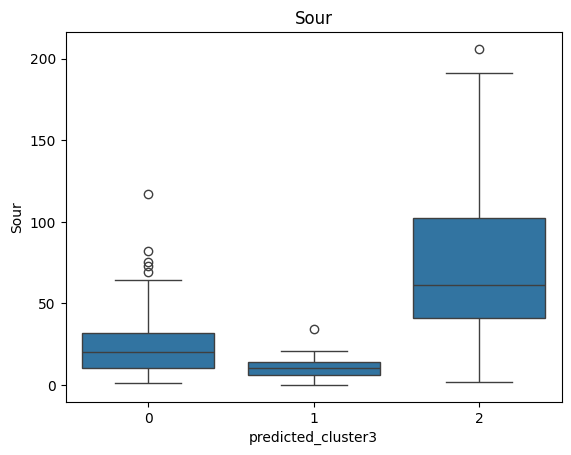

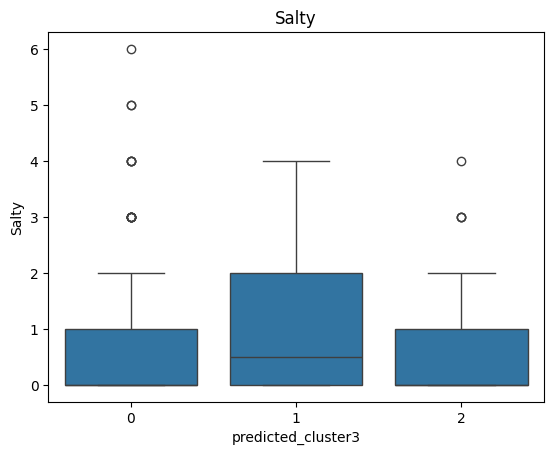

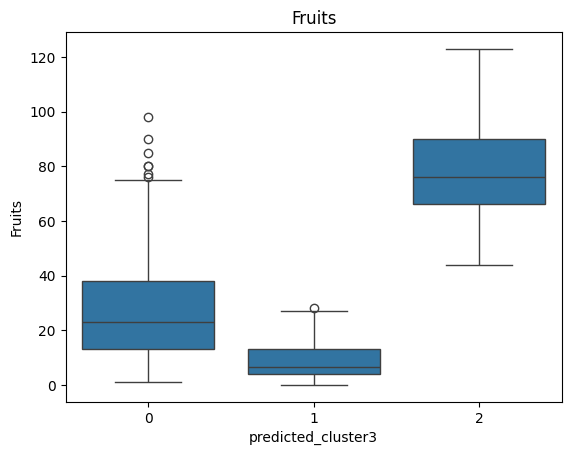

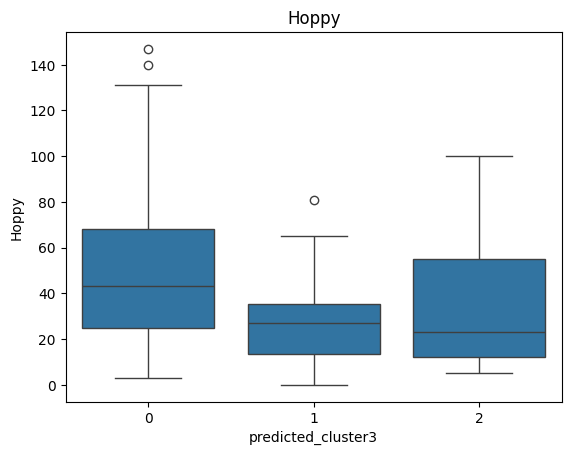

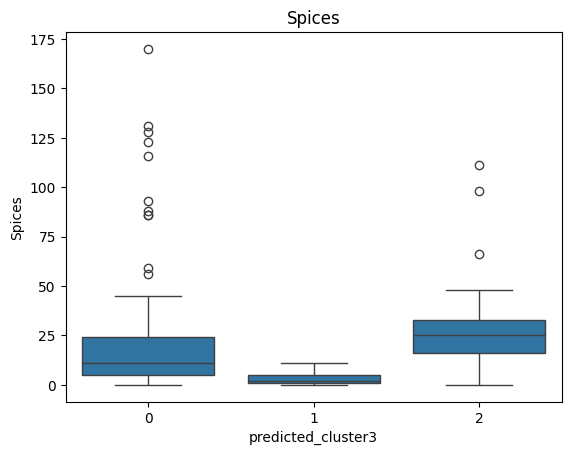

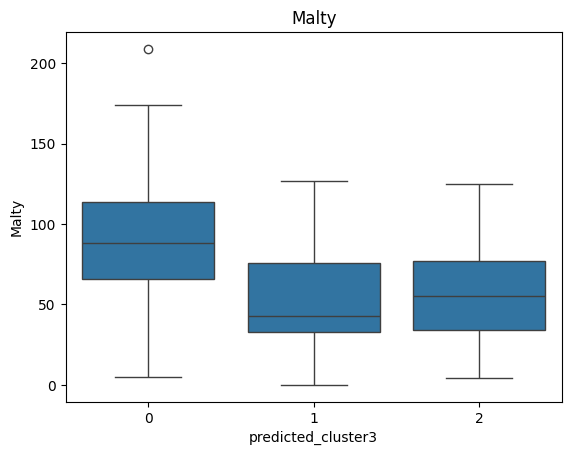

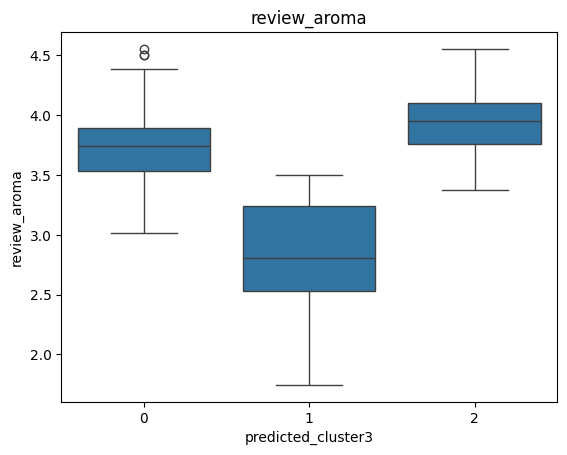

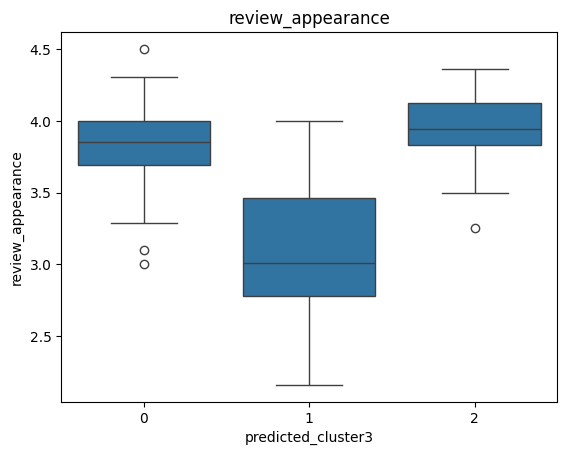

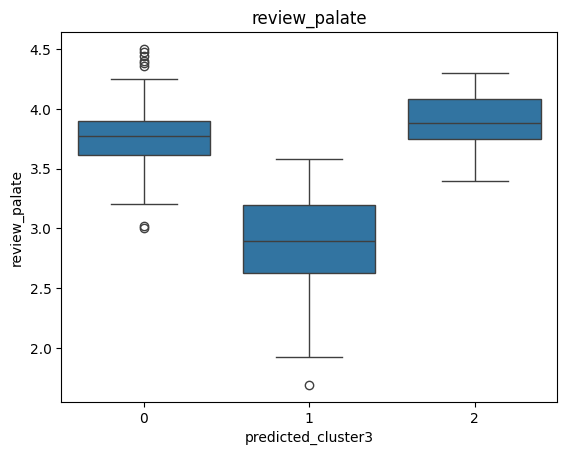

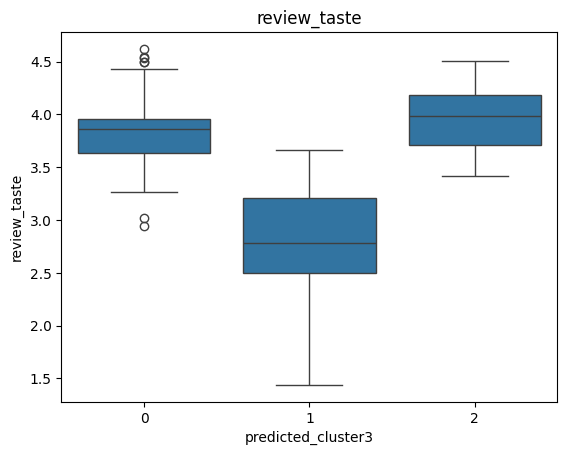

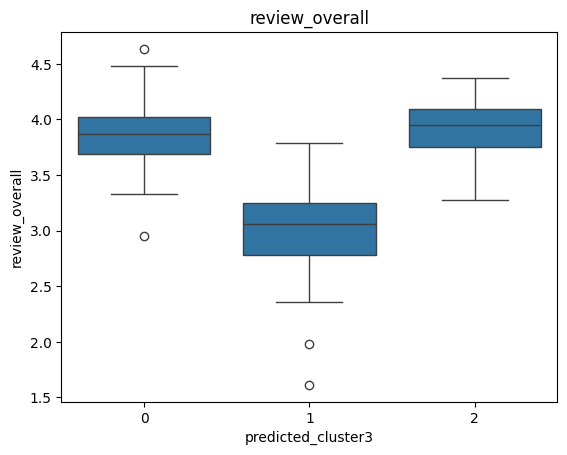

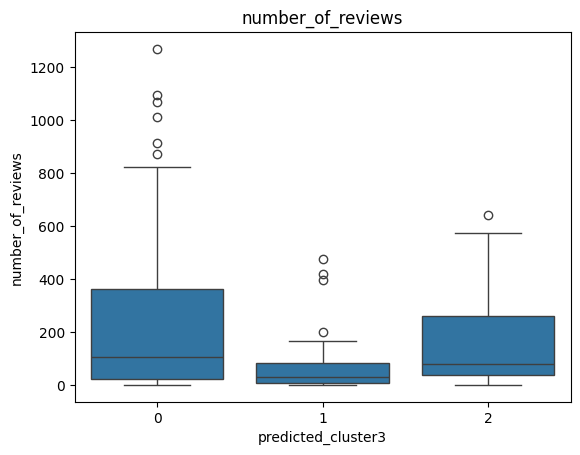

In [ ]:
for col in cols:
    sns.boxplot(x='predicted_cluster3',y=col,data=df)
    plt.title(col)
    plt.show()

In [ ]:
df.groupby(['predicted_cluster3','Rating']).agg('count')

index  Name  Style  Brewery  Beer Name (Full)  \
predicted_cluster3 Rating                                                     
0                  Horrible       0     0      0        0                 0   
                   Bad           15    15     15       15                15   
                   Mediocre      73    73     73       73                73   
                   Good          36    36     36       36                36   
                   Excellent      1     1      1        1                 1   
1                  Horrible       5     5      5        5                 5   
                   Bad           22    22     22       22                22   
                   Mediocre       5     5      5        5                 5   
                   Good           0     0      0        0                 0   
                   Excellent      0     0      0        0                 0   
2                  Horrible       0     0      0        0                 0   
                   Bad            4     4      4        4                 4   
                   Mediocre      20    20     20       20                20   
                   Good          17    17     17       17                17   
                   Excellent      0     0      0        0                 0   

                              Description  ABV  Min IBU  Max IBU  Astringency  \
predicted_cluster3 Rating                                                       
0                  Horrible             0    0        0        0            0   
                   Bad                 15   15       15       15           15   
                   Mediocre            73   73       73       73           73   
                   Good                36   36       36       36           36   
                   Excellent            1    1        1        1            1   
1                  Horrible             5    5        5        5            5   
                   Bad                 22   22       22       22           22   
                   Mediocre             5    5        5        5            5   
                   Good                 0    0        0        0            0   
                   Excellent            0    0        0        0            0   
2                  Horrible             0    0        0        0            0   
                   Bad                  4    4        4        4            4   
                   Mediocre            20   20       20       20           20   
                   Good                17   17       17       17           17   
                   Excellent            0    0        0        0            0   

                              ...  Fruits  Hoppy  Spices  Malty  review_aroma  \
predicted_cluster3 Rating     ...                                               
0                  Horrible   ...       0      0       0      0             0   
                   Bad        ...      15     15      15     15            15   
                   Mediocre   ...      73     73      73     73            73   
                   Good       ...      36     36      36     36            36   
                   Excellent  ...       1      1       1      1             1   
1                  Horrible   ...       5      5       5      5             5   
                   Bad        ...      22     22      22     22            22   
                   Mediocre   ...       5      5       5      5             5   
                   Good       ...       0      0       0      0             0   
                   Excellent  ...       0      0       0      0             0   
2                  Horrible   ...       0      0       0      0             0   
                   Bad        ...       4      4       4      4             4   
                   Mediocre   ...      20     20      20     20            20   
                   Good       ...      17     17      17     17            17   
            

We can see that cluster 2 tends to have a higher ABV (alcohol by volume) than the other 2 clusters. Cluster 0 tends to favor bitter beers while cluster 2 is predominantly sweet in flavor. Cluster 2 is also more fruity and sour when compared to the other 2 clusters. Cluster 0 tends to be more malty than clusters 1 and 2. Clusters 0 and 2 recieved approximately similar reviews on aroma, appearence, palate, taste, and overall review from the customers in our data sample. Between clusters 0 and 2, cluster 2 tended to have slightly higher reviews in all the aformentioned categories. When we look at the grouped data, we can see that cluster 1 recieved predominantly bad and horrible reviews, with only a few calling the beers within it mediocre (perhaps they were being nice). Cluster 2 has the highest proportion of good reviewed beers, with only 4 bad beers and 20 mediocre reviews (perhaps they were being harsh). Cluster 0 is a bit of a mixed bag but has predominantly mediocre reviews with twice as many good rated beers as bad rated ones. If we were to generalize these results, we would say that Cluster 2 tends to contain beers that are the best reviewed (when looking at proportions of good beers within clusters rather than raw numbers). The beers within cluster 2 are characterized by higher alcohol content, predominantly sweet, fruity, and sour flavor when compared to the other 2 clusters. Cluster 1 contains predominalty poorly reviewed beers that are mostly salty and contain the least amount of spices. Cluster 0 containts mostly mediocre beers that tend to be the most bitter but otherwise do not stand out much from the other two clusters in most characteristics.

## 10. Discussion


#### Adjusted Rand Score

In [ ]:
print(adjusted_rand_score(df['predicted_cluster3'], df['Rating']))
print(adjusted_rand_score(df['predicted cluster 7'], df['Rating']))

0.14864327950680276
0.0933966688291716


In [ ]:
kmeans = KMeans(n_clusters=7, random_state=seed)
kmeans.fit(num_df_scaled)
df['predicted cluster 7'] = kmeans.labels_
adjusted_rand_score(df['predicted_cluster3'], df['predicted cluster 7'])

0.24370667281031522

### What was different
We used a different number of clusters for the two methods, we were able to achieve different goals with each one. Comparing the resulting clusters to the ratings that each beer was given, we can see that the K-Means clusters were slightly more similar to the rating groups than the HAC clusters, but the two clustering algorithms are more similar to each other than either is to the rating groups. K-means clustering split the larger cluster (cluster 0 from HAC clustering) into about 5 distinct clusters. It also split cluster 2 into 2 distinct clusters as we hypothesized due to the sparsitity found in our HAC analysis. Because K-Means used more clusters, the clusters were able to get a bit more specific about which attribute was most dominant in determining whether an observation belonged in that cluster.


### Ability to Identify the "Inherent Clusters"
We believe that for our purposes, K-Means was better able to identify the clusters that we were looking for. The clusters were more similar to the ratings, and we were able to better see some of the trends for each attribute's average values across the different clusters. The clusters from HAC clustering were simply too generic and uninformative to make proper informed decisions about the content of an ideal beer.


### Clustering Trustworthiness/Usefulness
Since K-Means had the higher adjusted rand score, it's clusters were more similar to the rating groups, which is one of the things we were looking for. It should be noted that the rand score is specific only to determining the relationship between clustering and the inherent labels not the inherent clustering structure.


### Clustering Insights
Both clusterings had certain attributes that tended to be higher or lower on average than the other attributes, but because K-Means had more clusters, the number of extreme attributes for each cluster was lower, so the clusters were more specific. This could be beneficial for someone who has a better idea of what they're looking for in a beer. For example, if they like sour beer, they should choose one from cluster 3. In the HAC clustering, the Sour attribute is highest in cluster 2, but the difference between clusters isn't as large. One insight that we were able to see during the HAC clustering is the nested relationship between the clusters in the dendrogram. Being able to see when each cluster merges with the others can tell us how similar the observations in each cluster are, which we can't see with K-Means.

## 11. Conclusion

### Summarize
In this report we examined a sample dataset of beer reviews taken from a larger dataset of over 1.5 million reviews to see if we could find inherent clusters within it. These inherent clusters (if they were found) would then be used to make informed decisions for brewers on what attributes to focus on to make beer people would actually enjoy drinking. We used HAC clustering with ward linkeage as well as K-means clustering to see if we were able to find these inherent clusters. We discovered that K-Means with k=7 worked better for finding the inherent clusters than HAC. The cluster that was the most well-reviewed is characterized by high fruit content and high level of sourness with a low level of bitterness in the taste. HAC with ward link and k=3 clusters was able to effectively separate poorly reviewed beers but had less effective and meaningful separation that K-means overall. The beers in the best reviewed cluster in HAC clustering were characterized by higher alcohol content, predominantly sweet, fruity, and sour flavor when compared to the other 2 clusters.
### Recommendation
Overall, the insights we extracted may be used as additional evidence and guidelines when deciding on the content and composition of a new beer that a brewery may be making. The characteristics of a well-reviewed beer are a high fruit content and high level of sourness with a low level of bitterness in the taste so it would make sense to brew a beer that is abundant in these categories. The insights should not be taken as a hard rule as overall the clustering structure was not particularly strong but it was strong enough to make plausible conclusions and takeaways that can be used to further inform a brewer about beer characteristics that are desired by customers.
### Shortcomings/Caveats
The shortcomings of our analysis stem mainly from the nature of the dataset rather than our methods. The dataset itself does not easily lend itself to clean separation between observations. The majority of the beers reviewed in our sample had a mediocre review score and there were very few beers that had a high or low score. The overwhelming number of mediocre reviews made it harder to separte these observation and determine what actually made good beers. This makes sense as at the end of the day beers would generally share a fair number of basic characteristics such as containing a fairly low amount of alcohol when compared to other alcoholic drinks and containing some form of hops and malt which is generally used in the process of making beer. Furthermore, the clusters that were identified were not particularly spherical which made it difficult for certain algorithms to effectively cluster them. We were also somewhat limited by the lack of quality information from most of our categorical variables and had to primarily rely on scaled numerical variables to for our analysis.
### Future work
Based on our analysis we would aim to potentially explore the dataset further with different clustering algorithms such as potentially fuzzy c-means due to the lack of proper separation between clusters we have found through our analysis. This may prove somewhat troublesome as the clusters are not particularly spherical but it may reveal more insights into the inherent clustering present within this datset. In addition, we may wish to explore different clustering parameters such as a different link algorithm or k value for the clustering algorithms we used in this analysis to see if they would reveal something better than what we have observed. Lastly, it may be interesting to take a larger sample of data or perhaps even process the whole datset through an online clustering algorithm (such as mini-batch K-means) to see if our analysis results could be improved. Generally speaking, more datapoints do tend to increase the accuracy and results of analysis so it is reasonable to expect some new insights to show from an expanded dataset.

## References

[1]
“Using Data Science to Brew Beer.” School of Data Science, www.datascience.virginia.edu/pages/using-data-science-brew-beer. Accessed 16 Dec. 2024. \


[2]
Oleg, Pochepskiy. “Expert Perspectives: Analyzing the 22 Major Beer Trends.” Cleverence, 17 June 2024, www.cleverence.com/articles/business-blogs/expert-perspectives-analyzing-the-22-major-beer-trends/. Accessed 16 Dec. 2024. \


[3]
Habschied, K., Krstanović, V., & Mastanjević, K. “Beer Quality Evaluation—A Sensory Aspect.” Beverages, 2022, 8(1), 15. https://doi.org/10.3390/beverages8010015
